# Noether-SurPhiN : notebook de validation des lois de bilan topologiques (v2, adapté aux nuages 04b)

**Projet** : SurPhiN / COHESION_LAB_V01
**Données** : `nuages_complementaires/X_fam...*.npy` — familles A-E historiques et noms à tokens des familles F/H/I/J/K générées pour N11-N17.
**Module externe (inchangé)** : `noether_persistence.py` — tous les appels existants sont conservés tels quels.

## Ce qui a changé par rapport à la v1
| Zone | v1 | v2 |
|---|---|---|
| Parsing | regex qui ne détectait jamais la famille ; paramètres 04c ignorés | un parseur à tokens indexe `g/T/m/seed` et `tau/N/eps/tv/ds` ; supporte aussi les anciens noms compacts |
| Chargement | premier fichier du glob qui matche (ambigu entre A, C, D, E) | accès exact par clé `(famille, variante, g, T, m, seed)` ; erreur explicite si absent |
| Erreurs | `except FileNotFoundError: pass` | journal `ERRORS` + `MANQUANTS`, une section ne bloque plus les suivantes |
| N2 | dimension simulée par troncature `X[:, :m]` | **vrai plongement** (famille C), diagrammes bruts **et** normalisés |
| N3 | `mean_diagram_proxy` = concaténation de toutes les graines | diagramme représentatif (médian) ; 2 balayages 1D (A en T, D en g) |
| Charges | copeau seul (dérivée par rapport à l'index de graine) | + écart-type inter-graines, CV, versions normalisées, ARI/VI le long du paramètre |
| Tests | N1-N5 | N1-N5 recâblés + **N6 (A), N7 (B), N8 (dans N2, C), N9 (D), N10 (E)** |
| Export | N1-N3 | un seul CSV alimenté au fil des tests |

## Mode d'emploi pour déboguer pas à pas
1. Exécuter les cellules 1 → « Smoke test » : chaque appel externe est testé **isolément** sur un nuage jouet (✅/❌ + traceback court).
2. Chaque test est une fonction `run_N*()` : appelable seule, ou sous débogueur VSCode (point d'arrêt dans la fonction).
3. Les drapeaux `RUN = {...}` de la cellule de configuration permettent de n'activer qu'une section.

## Points d'attention noether_persistence.py (à garder en tête)
Les contrats supposés par ce notebook sont **ceux de la v1** (aucune modification du module). Ils sont vérifiés par la cellule « contrat d'API » et le « smoke test » :
1. `NoetherPipeline.from_faisceau_purifie(merges, n_points=n, param={})` : `merges` = liste `(i, j, d)` triée par `d` croissant → renvoie un `PersDiagram`.
2. `PersDiagram(pairs, param)` : `pairs` = tableau `(k, 2)` (naissance, mort), **la mort peut être `inf`** (classe essentielle) → tous les helpers filtrent les valeurs finies.
3. `TopologicalCharges.<charge>(dgm)` : une seule entrée (le diagramme), pas de paramètres supplémentaires.
4. `NoetherBalance.compute_balance(dgms, params_array, nom_param, charge_fn, nom_charge, tol=...)` puis `robustesse_noetherienne(balances)` → dict avec `regime`, `copeau_mediane`, `copeau_spread`, `n_samples`.
5. `NoetherPipeline.analyze_grille_couplage(grille, G_VALUES, T_VALUES)` : attend une grille `(g, T) → PersDiagram`. **Inconnue à vérifier** : accepte-t-elle une grille 1D (une seule valeur de g ou de T) ? Le notebook essaie et journalise l'échec. Les clés lues sont `"<charge>_vs_T_g<g>"` et `"<charge>_vs_g_T<T>"` ; la recherche est tolérante (voir `trouver_cle`).
6. `summary_report` : commenté dans l'import v1 mais appelé → le notebook le cherche dans le module / les classes, sinon utilise un repli local.
7. `WardIdentities.commutator_copeau(dgm_a, dgm_b, g_a, g_b, bottleneck_distance_fn=...)` appelle cette fonction avec des **`PersDiagram`**, alors que `bottleneck_H0` attend des **tableaux de morts** : le notebook passe `BOTTLENECK_FN`, un adaptateur qui essaie les diagrammes puis bascule sur les morts. Sans option, la branche par défaut appelle `bottleneck_H0(dgm, dgm)` et lève la `TypeError` observée.
8. `PersistenceCurrent.from_mst(merges, n_points, n_bins)` et `integrated_source(current)` : attributs lus `epsilon_grid`, `ncomp`, `flux`, `source`.
9. L'exposant `p` de `persistence_energy` est **détecté automatiquement** (smoke test) pour que `pers_energy_norm = E_p / M^p` soit cohérent avec le module.

## Limites méthodologiques à garder en tête
- Le « copeau » de N1 est une dérivée de charge **par rapport à l'index de graine** : l'ordre des graines étant arbitraire, il faut le lire comme un indicateur de dispersion, d'où l'ajout de l'écart-type inter-graines.
- ARI / VI entre partitions n'ont de sens que si les points se correspondent : ici, **à graine fixe** le long de T, g ou m (mêmes signaux de base, même bruit mis à l'échelle). Jamais entre graines. Pour `m` variable la correspondance est approximative (léger décalage temporel).
- Après `standardiser`, les distances croissent avec la dimension du plongement : les charges extensives (`pers_energy`, `pers_mass`) ne sont comparables entre `m` qu'après normalisation (mode `max_death`).
- Les nuages A, D (g=0.35, T=0.40) et C (m=3) sont identiques par construction : à ne pas compter trois fois.

In [1]:
# -----------------------------------------------------------------------------
# 1. SETUP : imports, racine du projet (chemins relatifs), configuration
# -----------------------------------------------------------------------------
import os, sys, re, csv, json, time, traceback, inspect, warnings
from pathlib import Path
from collections import defaultdict, OrderedDict, Counter
from functools import lru_cache
from typing import List, Dict, Tuple, Optional

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.cluster.hierarchy import linkage, fcluster

def trouver_racine(depart=None) -> Path:
    """Remonte depuis le dossier courant jusqu'à un marqueur de projet."""
    p = Path(depart or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / ".venv").exists() or (cand / ".vscode").exists() or (cand / "noether_persistence.py").exists():
            return cand
    return p

BASE_DIR = trouver_racine()
FIG_DIR = BASE_DIR   # mêmes emplacements de figures que la v1

def trouver_nuage_dir() -> Path:
    # 04b a écrit dans <cwd de 04b>/nuages_complementaires : on teste cwd puis racine
    for base in (Path.cwd(), BASE_DIR):
        d = base / "nuages_complementaires"
        if d.is_dir():
            return d
    return BASE_DIR / "nuages_complementaires"

NUAGE_DIR = trouver_nuage_dir()

# noether_persistence.py doit être importable (même dossier que le notebook ou racine)
for d in (Path.cwd(), BASE_DIR):
    if (d / "noether_persistence.py").exists() and str(d) not in sys.path:
        sys.path.insert(0, str(d))

# ---- Configuration ----
SEEDS = list(range(35))          # 04b : 12->35 graines
K_PART = 5                       # nombre de classes pour les partitions H0 (ARI / VI)
N_BINS_CURRENT = 80              # résolution du courant de persistance (N4, N10)
NORM_MODES = ("none", "max_death")   # diagrammes bruts / normalisés par la mort max finie
PROXY_MODE = "median"            # N3 : "median" (représentant médian) ou "concat" (comportement v1)
REF_SEED = 0                     # graine de référence pour N4 (v1 : commentaire seed=0, code seed=7)
RUN = {"N1": True, "N2": True, "N3": True, "N4": True, "N5": True,
       "N6": True, "N7": True, "N9": True, "N10": True}    # N8 est dans N2

print(f"BASE_DIR  : {BASE_DIR}")
print(f"NUAGE_DIR : {NUAGE_DIR}  ({'✅ existe' if NUAGE_DIR.is_dir() else '❌ introuvable'})")
print(f"sys.path[0] : {sys.path[0]}")

BASE_DIR  : C:\Users\anton\source\Takens_H0_Simondon_in_PHY_noether-surphin-suite_forPUB
NUAGE_DIR : c:\Users\anton\source\Takens_H0_Simondon_in_PHY_noether-surphin-suite_forPUB\nuages_complementaires  (✅ existe)
sys.path[0] : C:\Users\anton\source\Takens_H0_Simondon_in_PHY_noether-surphin-suite_forPUB


In [2]:
# -----------------------------------------------------------------------------
# 2. IMPORT DE noether_persistence.py (inchangé) + contrat d'API
# -----------------------------------------------------------------------------
import importlib
try:
    import noether_persistence as NP
    importlib.reload(NP)          # reprend les modifs du .py sans redémarrer le noyau
    from noether_persistence import (
        NoetherPipeline,
        TopologicalCharges,
        NoetherBalance,
        PersDiagram,
        PersistenceCurrent,
        WardIdentities,
    )
    print(f"✅ noether_persistence importé depuis : {NP.__file__}")
except Exception:
    traceback.print_exc()
    raise RuntimeError("Import de noether_persistence impossible : vérifier que le fichier est "
                       "dans le dossier du notebook (ou la racine du projet) et que le noyau VSCode "
                       "est bien celui du .venv.")

# summary_report : commenté dans l'import v1 mais appelé en N3 -> on le cherche partout
summary_report = None
for _src in (NP, NoetherPipeline, WardIdentities, NoetherBalance):
    if hasattr(_src, "summary_report"):
        summary_report = getattr(_src, "summary_report")
        print(f"ℹ️ summary_report trouvé dans {getattr(_src, '__name__', _src)}")
        break
if summary_report is None:
    def summary_report(results):
        """Repli local (le module n'expose pas summary_report)."""
        rob = (results or {}).get("robustesse", {})
        lignes = [f"{k:45s} regime={v.get('regime','?'):12s} copeau_med={v.get('copeau_mediane', float('nan')):.4f}"
                  for k, v in sorted(rob.items())]
        return "\n".join(lignes) if lignes else "(aucun résultat de robustesse)"
    print("ℹ️ summary_report absent du module -> repli local utilisé")

# ---- Contrat d'API : signatures réellement présentes ----
_CONTRAT = [
    (NoetherPipeline, "from_faisceau_purifie"), (NoetherPipeline, "analyze_grille_couplage"),
    (TopologicalCharges, "persistence_energy"), (TopologicalCharges, "persistence_mass"),
    (TopologicalCharges, "pers_median"), (TopologicalCharges, "pers_entropy"), (TopologicalCharges, "pers_iqr"),
    (TopologicalCharges, "adiabatic_ncomp"), (TopologicalCharges, "depth_fraction"),
    (TopologicalCharges, "topological_gini"),
    (NoetherBalance, "compute_balance"), (NoetherBalance, "robustesse_noetherienne"),
    (PersistenceCurrent, "from_mst"), (PersistenceCurrent, "integrated_source"),
    (WardIdentities, "commutator_copeau"),
]
print("\n--- Contrat d'API (signatures réelles) ---")
for cls, name in _CONTRAT:
    fn = getattr(cls, name, None)
    if fn is None:
        print(f"❌ {cls.__name__}.{name} : ABSENT")
        continue
    try:
        sig = str(inspect.signature(fn))
    except (TypeError, ValueError):
        sig = "(signature illisible)"
    print(f"✅ {cls.__name__}.{name}{sig}")

✅ noether_persistence importé depuis : C:\Users\anton\source\Takens_H0_Simondon_in_PHY_noether-surphin-suite_forPUB\noether_persistence.py
ℹ️ summary_report trouvé dans noether_persistence

--- Contrat d'API (signatures réelles) ---
✅ NoetherPipeline.from_faisceau_purifie(merges: 'List[Tuple[int, int, float]]', n_points: 'int', param: 'Dict') -> 'PersDiagram'
✅ NoetherPipeline.analyze_grille_couplage(diagram_grid: 'Dict[Tuple[float, float], PersDiagram]', g_values: 'List[float]', T_values: 'List[float]') -> 'Dict'
✅ TopologicalCharges.persistence_energy(dgm: 'PersDiagram', p: 'float' = 2.0) -> 'float'
✅ TopologicalCharges.persistence_mass(dgm: 'PersDiagram') -> 'float'
✅ TopologicalCharges.pers_median(dgm)
✅ TopologicalCharges.pers_entropy(dgm)
✅ TopologicalCharges.pers_iqr(dgm)
✅ TopologicalCharges.adiabatic_ncomp(dgm: 'PersDiagram', epsilon_frac: 'float' = 0.5) -> 'int'
✅ TopologicalCharges.depth_fraction(dgm: 'PersDiagram', epsilon_frac: 'float' = 0.5) -> 'float'
✅ TopologicalCharge

In [3]:
# -----------------------------------------------------------------------------
# 3. I/O : parsing des noms, index des nuages, chargement exact
# -----------------------------------------------------------------------------
# Les paramètres non présents dans un nom conservent les références du protocole.
FNAME_RE = re.compile(r"^X_fam(?P<fam>[A-Z]\d*)_(?P<body>.+)\.npy$")
FIELD_RE = re.compile(r"^(?P<field>g|T|m|seed|s|tau|N|eps|tv|ds)(?P<value>\d+(?:\.\d+)?)$")

def _decode_filename_number(field, value):
    number = float(value)
    if field == "g" and "." not in value and len(value) == 3:
        number /= 100
    elif field == "T" and "." not in value and len(value) in (2, 3):
        number /= 100
    return int(number) if field in {"m", "seed", "s", "tau", "N", "tv", "ds"} else number

def parse_filename(fname) -> Optional[dict]:
    """Parse les noms historiques et les tokens explicites des familles 04c."""
    base = os.path.basename(str(fname))
    match = FNAME_RE.fullmatch(base)
    if match is None:
        return None
    result = {"famille": match["fam"], "variante": "", "g": 0.0, "T": None,
              "m": 3, "seed": None, "tau": 7, "N": 300,
              "eps": float("nan"), "tv": float("nan"), "ds": 1, "_compact": False}
    variants, seen = [], set()
    for token in match["body"].split("_"):
        token_match = FIELD_RE.fullmatch(token)
        if token_match is None:
            variants.append(token)
            continue
        field = token_match["field"]
        value = token_match["value"]
        if field in {"m", "seed", "s", "tau", "N", "tv", "ds"} and "." in value:
            return None
        if field == "s" or (field == "g" and "." not in value and len(value) == 3) or (field == "T" and "." not in value and len(value) in (2, 3)):
            result["_compact"] = True
        field = "seed" if field == "s" else field
        if field in seen:
            return None
        seen.add(field)
        result[field] = _decode_filename_number(field, token_match["value"])
    if result["T"] is None or result["seed"] is None:
        return None
    result["variante"] = "_".join(variants)
    result["path"] = str(fname)
    return result

def construire_index(nuage_dir: Path):
    index, non_parses, doublons_compacts = {}, [], 0
    for f in sorted(Path(nuage_dir).glob("X_fam*.npy")):
        meta = parse_filename(f.name)
        if meta is None:
            non_parses.append(f.name)
            continue
        meta["path"] = f
        number = lambda value: None if isinstance(value, (float, np.floating)) and not np.isfinite(value) else round(float(value), 5)
        key = (meta["famille"], meta["variante"], number(meta["g"]), number(meta["T"]), meta["m"], meta["tau"], meta["N"], number(meta["eps"]), number(meta["tv"]), meta["ds"], meta["seed"])
        previous = index.get(key)
        if previous is None:
            index[key] = meta
        elif previous["_compact"] != meta["_compact"]:
            if previous["_compact"]:
                index[key] = meta
            doublons_compacts += 1
        else:
            raise ValueError(f"Deux fichiers portent la même clé de nuage : {previous['path'].name} / {f.name}")
    return sorted(index.values(), key=lambda row: row["path"].name), non_parses, doublons_compacts

INDEX, NON_PARSES, DOUBLONS_COMPACTS = construire_index(NUAGE_DIR)
# L'API historique load_nuage sert A-E ; N11-N17 utilisent l'index étendu KEY2.
KEY = {(r["famille"], r["variante"], r["g"], r["T"], r["m"], r["seed"]): r["path"]
       for r in INDEX if r["famille"] in {"A", "B", "C", "D", "E"}}
MANQUANTS = set()

@lru_cache(maxsize=None)
def _npy(path_str: str) -> np.ndarray:
    X = np.load(path_str)
    X.flags.writeable = False     # les nuages sont partagés par le cache : lecture seule
    return X

def load_nuage(g: float, T: float, seed: int, famille: str, m: int = 3, variante: str = ""):
    """Charge un nuage par clé EXACTE. Renvoie (X, meta). Lève FileNotFoundError si absent.
    NB : la v1 prenait le premier fichier du glob ; la famille est maintenant obligatoire."""
    key = (famille, variante, round(float(g), 2), round(float(T), 2), int(m), int(seed))
    p = KEY.get(key)
    if p is None:
        proches = [k for k in KEY if k[0] == famille and k[1] == variante][:3]
        raise FileNotFoundError(f"Nuage introuvable : fam={famille} var='{variante}' g={g} T={T} m={m} seed={seed} "
                                f"(exemples existants : {proches})")
    meta = {"famille": famille, "variante": variante, "g": key[2], "T": key[3], "m": key[4], "seed": key[5], "path": str(p)}
    return _npy(str(p)), meta

def valeurs(famille: str, champ: str, **fixes):
    """Valeurs distinctes de `champ` pour une famille, filtrées par les champs fixés (ex. g=0.35, m=3)."""
    out = set()
    for r in INDEX:
        if r["famille"] != famille:
            continue
        if all(np.isclose(r[k], v) if isinstance(v, float) else r[k] == v for k, v in fixes.items()):
            out.add(r[champ])
    return sorted(out)

print(f"{len(INDEX)} nuages indexés ; {len(NON_PARSES)} noms X_fam non reconnus ; {DOUBLONS_COMPACTS} doublons compacts écartés")
if NON_PARSES:
    print("   non reconnus (exemples) :", NON_PARSES[:5])

7455 nuages indexés ; 0 noms X_fam non reconnus ; 0 doublons compacts écartés


In [4]:
# -----------------------------------------------------------------------------
# 4. COMPLÉTUDE + CONTRÔLE QUALITÉ de l'index
# -----------------------------------------------------------------------------
ATTENDU_A_E = {"A": 280, "B": 105, "C": 245, "D": 385, "E": 140}
ATTENDU_04C = {"F": 1540, "H": 1155, "I": 735, "J": 1750, "K": 1120}
par_fam = Counter(r["famille"] for r in INDEX)
print(f"{'Famille':8s} {'trouvés':>8s} {'attendus':>9s}")
for fam, n_att in {**ATTENDU_A_E, **ATTENDU_04C}.items():
    n = par_fam.get(fam, 0)
    print(f"{fam:8s} {n:8d} {n_att:9d}   {'OK' if n == n_att else 'INCOMPLET'}")
print("Familles historiques H1-H4 :", {fam: par_fam[fam] for fam in sorted(par_fam) if fam.startswith("H") and fam != "H"})

problemes = []
for r in INDEX:
    X = _npy(str(r["path"]))
    attendu_cols = r["m"] if r["famille"] == "B" else 2 * r["m"]    # B = un canal ; autres = 2 canaux
    n_points = r["N"]
    if X.ndim != 2: problemes.append(f"{r['path'].name}: ndim={X.ndim}")
    elif X.shape != (n_points, attendu_cols): problemes.append(f"{r['path'].name}: shape={X.shape}, attendu ({n_points}, {attendu_cols})")
    if not np.isfinite(X).all(): problemes.append(f"{r['path'].name}: NaN/inf")
print("Contrôle qualité :", "✅ OK" if not problemes else f"⚠️ {len(problemes)} anomalies")
for p in problemes[:10]:
    print("  -", p)

# Doublons attendus : A(g=.35,T=.40) = D(g=.35) = C(m=3) par construction
if all(k in KEY for k in [("A","",0.35,0.40,3,0), ("D","",0.35,0.40,3,0), ("C","",0.35,0.40,3,0)]):
    a, d_, c = (_npy(str(KEY[(f,"",0.35,0.40,3,0)])) for f in "ADC")
    print("Nuages (0.35, 0.40, m=3, seed0) identiques entre A, D, C :", np.allclose(a, d_) and np.allclose(a, c))

Famille   trouvés  attendus
A             280       280   OK
B             105       105   OK
C             245       245   OK
D             385       385   OK
E             140       140   OK
F            1540      1540   OK
H            1155      1155   OK
I             735       735   OK
J            1750      1750   OK
K            1120      1120   OK
Familles historiques H1-H4 : {}
Contrôle qualité : ✅ OK
Nuages (0.35, 0.40, m=3, seed0) identiques entre A, D, C : True


In [5]:
# -----------------------------------------------------------------------------
# 5. MOTEUR TOPOLOGIQUE : MST -> diagramme H0 (appel noether_persistence inchangé)
# -----------------------------------------------------------------------------
ENGINE_WARNINGS = []

def mst_merges(X: np.ndarray):
    """Arêtes du MST triées par distance croissante : liste (i, j, d). Partagé par H0, N4 et N10."""
    n = X.shape[0]
    D = squareform(pdist(X))
    # scipy traite 0 comme « pas d'arête » : on évite de perdre une fusion pour des points dupliqués
    dup = (D == 0)
    np.fill_diagonal(dup, False)
    if dup.any():
        D[dup] = 1e-12
        ENGINE_WARNINGS.append(f"{int(dup.sum()//2)} paires de points dupliqués (distance 0 -> 1e-12)")
    coo = minimum_spanning_tree(D).tocoo()
    merges = sorted(((int(i), int(j), float(d)) for i, j, d in zip(coo.row, coo.col, coo.data)),
                    key=lambda t: t[2])
    if len(merges) != n - 1:
        ENGINE_WARNINGS.append(f"MST incomplet : {len(merges)} arêtes pour {n} points")
    return merges

def single_linkage_h0_diagram(X: np.ndarray) -> "PersDiagram":
    """Diagramme H0 par single-linkage via MST (même appel que la v1)."""
    n = X.shape[0]
    if n < 2:
        return PersDiagram(pairs=np.zeros((0, 2)), param={})
    merges = mst_merges(X)
    return NoetherPipeline.from_faisceau_purifie(merges, n_points=n, param={})

# ---- Utilitaires d'adaptation (notebook uniquement : noether_persistence.py n'est pas touché) ----
def _pairs(dgm) -> np.ndarray:
    return np.asarray(dgm.pairs, dtype=float).reshape(-1, 2)

def lifetimes(dgm) -> np.ndarray:
    p = _pairs(dgm)
    l = p[:, 1] - p[:, 0]
    return l[np.isfinite(l)]

def mean_lifetime(dgm) -> float:
    l = lifetimes(dgm)
    return float(l.mean()) if l.size else float("nan")

P_ENERGY = 2.0     # sera recalé par le smoke test (comparaison avec TopologicalCharges.persistence_energy)

def pers_energy_norm(dgm, p: Optional[float] = None) -> float:
    """Énergie normalisée par M^p et ajustée au nombre de barres."""
    p = P_ENERGY if p is None else p
    l = lifetimes(dgm)
    M = l.sum()
    if l.size == 0 or M <= 0:
        return float("nan")
    return float((l ** p).sum() / M ** p) * l.size

def normaliser_dgm(dgm, mode: str = "max_death", dim: Optional[int] = None):
    """Renvoie un NOUVEAU PersDiagram mis à l'échelle (le diagramme d'origine n'est pas modifié).
    mode : "none" | "max_death" (mort max finie = 1) | "sqrt_dim" (division par sqrt(dimension))."""
    if mode == "none":
        return dgm
    p = _pairs(dgm).copy()
    if mode == "max_death":
        fin = p[:, 1][np.isfinite(p[:, 1])]
        s = fin.max() if fin.size and fin.max() > 0 else 1.0
    elif mode == "sqrt_dim":
        s = np.sqrt(dim if dim else 1)
    else:
        raise ValueError(f"mode de normalisation inconnu : {mode}")
    return PersDiagram(pairs=p / s, param=dict(getattr(dgm, "param", {}) or {}))

# ---- Partitions H0 et distances entre partitions (ARI, VI) ----
def partition_labels(X: np.ndarray, k: int = K_PART) -> np.ndarray:
    """Partition en k classes par single-linkage (cohérent avec H0).
    Attention : à k fixe, single-linkage isole surtout des points aberrants -> ARI souvent proche de 1."""
    Z = linkage(pdist(X), method="single")
    return fcluster(Z, t=k, criterion="maxclust")

def _contingence(a, b):
    ua, ia = np.unique(a, return_inverse=True)
    ub, ib = np.unique(b, return_inverse=True)
    C = np.zeros((len(ua), len(ub)), dtype=np.int64)
    np.add.at(C, (ia, ib), 1)
    return C

def ari(a, b) -> float:
    C = _contingence(a, b)
    n = C.sum()
    comb = lambda x: x * (x - 1) / 2.0
    sij, sa, sb, tot = comb(C).sum(), comb(C.sum(1)).sum(), comb(C.sum(0)).sum(), comb(n)
    exp = sa * sb / tot if tot else 0.0
    mx = (sa + sb) / 2.0
    return 1.0 if mx == exp else float((sij - exp) / (mx - exp))

def vi(a, b) -> float:
    C = _contingence(a, b) / len(a)
    pa, pb = C.sum(1), C.sum(0)
    nz = C > 0
    mi = (C[nz] * np.log(C[nz] / np.outer(pa, pb)[nz])).sum()
    ha, hb = -(pa * np.log(pa)).sum(), -(pb * np.log(pb)).sum()
    return float(ha + hb - 2 * mi)

print("Moteur H0 et utilitaires d'adaptation prêts.")

Moteur H0 et utilitaires d'adaptation prêts.


In [6]:
# -----------------------------------------------------------------------------
# 6. INFRASTRUCTURE : charges, cache de diagrammes, bilan, journal d'erreurs, lignes d'export
# -----------------------------------------------------------------------------
CHARGES = {
    "pers_energy": TopologicalCharges.persistence_energy,
    "pers_mass": TopologicalCharges.persistence_mass,
    "adiabatic_ncomp": TopologicalCharges.adiabatic_ncomp,
    "depth_fraction": TopologicalCharges.depth_fraction,
    "topological_gini": TopologicalCharges.topological_gini,
    "pers_median": TopologicalCharges.pers_median,    # <--- AJOUTE
    "pers_entropy": TopologicalCharges.pers_entropy,   # <--- AJOUTE
    "pers_iqr": TopologicalCharges.pers_iqr,       # <--- AJOUTE
}
REGIME_COLOR = {"conservatif": "#2ecc71", "adiabatique": "#f39c12", "turbulent": "#e74c3c"}
REGIME_ABBR = {"conservatif": "CON", "adiabatique": "ADI", "turbulent": "TUR"}

ERRORS: List[Tuple[str, str]] = []     # (étiquette, message) : plus aucune erreur n'est avalée
ROWS: List[dict] = []                  # lignes du CSV final
CSV_FIELDS = ["test", "famille", "variante", "param", "param_value", "charge", "norm", "g", "T", "m", "seed",
              "copeau_mediane", "copeau_spread", "regime", "n_samples",
              "valeur_mediane", "std_inter_graines", "cv", "note"]

def add_row(**kw):
    ROWS.append({k: kw.get(k, "") for k in CSV_FIELDS})

def safe_run(label, fn, *a, **k):
    """Exécute fn ; en cas d'erreur : traceback court + journal, et le notebook continue."""
    try:
        return fn(*a, **k)
    except Exception as e:
        tb = traceback.format_exc().strip().splitlines()
        print(f"❌ [{label}] {type(e).__name__}: {e}")
        for ligne in tb[-4:]:
            print("     ", ligne)
        ERRORS.append((label, f"{type(e).__name__}: {e}"))
        return None

def essai(label, fn):
    """Version bavarde de safe_run pour le smoke test."""
    try:
        res = fn()
        print(f"✅ {label}")
        return res
    except Exception as e:
        print(f"❌ {label} -> {type(e).__name__}: {e}")
        for ligne in traceback.format_exc().strip().splitlines()[-3:]:
            print("     ", ligne)
        ERRORS.append((f"smoke:{label}", f"{type(e).__name__}: {e}"))
        return None

_DGM_CACHE = {}
def diagrammes(famille, g, T, m=3, variante="", seeds=None):
    """(seeds_trouvées, [X], [PersDiagram]) pour une condition. Les graines absentes sont journalisées."""
    seeds = tuple(SEEDS if seeds is None else seeds)
    ck = (famille, variante, round(float(g), 2), round(float(T), 2), int(m), seeds)
    if ck in _DGM_CACHE:
        return _DGM_CACHE[ck]
    ss, Xs, dgms = [], [], []
    for s in seeds:
        try:
            X, meta = load_nuage(g, T, s, famille, m, variante)
        except FileNotFoundError:
            MANQUANTS.add((famille, variante, round(float(g), 2), round(float(T), 2), int(m), s))
            continue
        dgm = single_linkage_h0_diagram(X)
        dgm.param = {"famille": famille, "variante": variante, "g": ck[2], "T": ck[3],
                     "m": int(m), "dim": int(m), "seed": s}
        ss.append(s); Xs.append(X); dgms.append(dgm)
    _DGM_CACHE[ck] = (ss, Xs, dgms)
    return _DGM_CACHE[ck]

def charge_array(dgms, Xs, charge_fn, mode="none") -> np.ndarray:
    """Charge par graine (nan si le calcul échoue pour un diagramme)."""
    out = []
    for d, X in zip(dgms, Xs):
        try:
            out.append(float(charge_fn(normaliser_dgm(d, mode, dim=X.shape[1]))))
        except Exception:
            out.append(float("nan"))
    return np.array(out, dtype=float)

def stats_inter(q: np.ndarray):
    """(médiane, écart-type inter-graines, CV). L'écart-type remplace le « copeau » comme mesure de dispersion (04b §10.2)."""
    q = q[np.isfinite(q)]
    if q.size < 2:
        return (float(np.median(q)) if q.size else float("nan"), float("nan"), float("nan"))
    sd = float(q.std(ddof=1)); mu = float(q.mean())
    return float(np.median(q)), sd, (sd / abs(mu) if mu != 0 else float("nan"))

def bilan(dgms, params, pname, charge_fn, charge_name, tol, label=""):
    """Appels EXACTEMENT comme en v1 : compute_balance(dgms, params, nom_param, charge_fn, nom_charge, tol=...)."""
    try:
        bals = NoetherBalance.compute_balance(dgms, np.asarray(params), pname, charge_fn, charge_name, tol=tol)
        return NoetherBalance.robustesse_noetherienne(bals)
    except Exception as e:
        print(f"❌ [{label or 'bilan'}] compute_balance/robustesse ({charge_name}, param={pname}) : {type(e).__name__}: {e}")
        ERRORS.append((f"bilan:{label}:{charge_name}", f"{type(e).__name__}: {e}"))
        return None

def crit_param(Q: np.ndarray, xvals):
    """Q : (n_param, n_graines). Intervalle de plus forte variation |ΔQ|/Δx, par graine.
    Renvoie (indices par graine, indice modal, fraction de graines d'accord). Indicatif, pas un test."""
    x = np.asarray(xvals, float)
    dQ = np.abs(np.diff(Q, axis=0)) / np.diff(x)[:, None]
    idx = np.nanargmax(np.where(np.isfinite(dQ), dQ, -np.inf), axis=0)
    cnt = Counter(idx.tolist())
    modal, nmod = cnt.most_common(1)[0]
    return idx, modal, nmod / len(idx)

# ---- Adaptateur bottleneck pour WardIdentities.commutator_copeau (N5 + smoke test) ----
# On définit explicitement l'extraction des morts pour éviter le fallback automatique
# qui génère l'avertissement '_approx_bottleneck used'.

def deaths_of(dgm) -> np.ndarray:
    """Morts finies d'un diagramme H0 (les naissances valent 0 en H0 : morts = durées de vie)."""
    # On utilise _pairs qui est déjà défini dans le notebook
    d = _pairs(dgm)[:, 1]
    return d[np.isfinite(d)]

def make_bottleneck_fn():
    # On récupère la fonction brute du module
    f = getattr(NP, "bottleneck_H0", None)
    if f is None:
        try:
            from faisceau_couplage import bottleneck_H0 as f
        except Exception:
            f = None
            
    if f is None:
        print("⚠️ bottleneck_H0 introuvable -> option non utilisée")
        return None

    # On définit une fonction qui extrait systématiquement les morts.
    # Cela garantit l'utilisation de la vraie fonction bottleneck_H0 sans TypeError.
    def fn(dgm_a, dgm_b):
        return f(deaths_of(dgm_a), deaths_of(dgm_b))
    
    return fn

BOTTLENECK_FN = make_bottleneck_fn()

print("Infrastructure prête (mode bottleneck explicite).")


Infrastructure prête (mode bottleneck explicite).


In [7]:
# -----------------------------------------------------------------------------
# 7. SMOKE TEST : chaque appel externe testé ISOLÉMENT sur des nuages jouets
#    -> si un ❌ apparaît ici, le problème est dans le branchement noether_persistence, pas dans les tests N*.
# -----------------------------------------------------------------------------
def smoke_test():
    rng = np.random.default_rng(0)
    clouds = [rng.normal(size=(120, 6)) * (1 + 0.15 * k) for k in range(4)]

    dg = essai("single_linkage_h0_diagram", lambda: single_linkage_h0_diagram(clouds[0]))
    if dg is None:
        print("   -> impossible de continuer : le diagramme H0 n'est pas construit.")
        return
    P = _pairs(dg)
    print(f"   pairs : shape={P.shape}, morts infinies={int((~np.isfinite(P[:,1])).sum())}, "
          f"naissances≠0={int((P[:,0]!=0).sum())}")

    dgms = [single_linkage_h0_diagram(c) for c in clouds]
    for k, d in enumerate(dgms):
        d.param = {"g": 0.35, "T": 0.1 * (k + 1), "seed": k, "dim": k + 2}

    # Charges + détection de l'exposant p de persistence_energy
    for cname, cfn in CHARGES.items():
        v = essai(f"charge {cname}", lambda cfn=cfn: float(cfn(dgms[0])))
        if v is not None:
            print(f"   {cname} = {v:.6g}")
    l = lifetimes(dgms[0])
    try:
        e_mod = float(CHARGES["pers_energy"](dgms[0]))
        cand = {p: float((l ** p).sum()) for p in (1.0, 2.0)}
        p_best = min(cand, key=lambda p: abs(cand[p] - e_mod))
        global P_ENERGY
        if abs(cand[p_best] - e_mod) <= 1e-6 * max(1.0, abs(e_mod)):
            P_ENERGY = p_best
            print(f"   ℹ️ persistence_energy ≈ somme(durées^{p_best:g}) -> P_ENERGY = {P_ENERGY:g}")
        else:
            print(f"   ⚠️ persistence_energy ({e_mod:.6g}) ne correspond ni à p=1 ni à p=2 : "
                  f"pers_energy_norm utilise P_ENERGY={P_ENERGY:g} (à ajuster à la main)")
    except Exception as e:
        print("   (détection de p impossible :", e, ")")

    # Bilan sur un paramètre (comme N1/N2)
    rob = essai("compute_balance + robustesse (param 'seed')",
                lambda: bilan(dgms, np.arange(len(dgms)), "seed", CHARGES["pers_energy"], "pers_energy", 0.05, "smoke"))
    if rob is not None:
        print("   clés de robustesse :", sorted(rob.keys()))
        manquantes = [k for k in ("regime", "copeau_mediane", "copeau_spread", "n_samples") if k not in rob]
        print("   clés attendues manquantes :", manquantes or "aucune")

    # Courant de persistance (N4, N10)
    def _courant():
        merges = mst_merges(clouds[0])
        cur = PersistenceCurrent.from_mst(merges, n_points=clouds[0].shape[0], n_bins=N_BINS_CURRENT)
        for att in ("epsilon_grid", "ncomp", "flux", "source"):
            assert hasattr(cur, att), f"attribut manquant : {att}"
        return PersistenceCurrent.integrated_source(cur)
    s = essai("PersistenceCurrent.from_mst + integrated_source", _courant)
    if s is not None:
        print(f"   source intégrée = {s:.6g}")

    # Ward (N5)
    w = essai("WardIdentities.commutator_copeau",
              lambda: WardIdentities.commutator_copeau(dgms[0], dgms[1], 0.35, 0.40,
                                                       bottleneck_distance_fn=BOTTLENECK_FN))
    if w is not None:
        print(f"   copeau = {w}")

    # Grille 2x2 puis grilles 1D (N3) : la 1D est LE point incertain
    def _grille(Gs, Ts):
        grid = {(g, T): dgms[(i + j) % len(dgms)] for i, g in enumerate(Gs) for j, T in enumerate(Ts)}
        return NoetherPipeline.analyze_grille_couplage(grid, Gs, Ts)
    r22 = essai("analyze_grille_couplage grille 2x2", lambda: _grille([0.35, 0.70], [0.2, 0.4]))
    r1T = essai("analyze_grille_couplage grille 1D en T (1 g, 4 T)", lambda: _grille([0.35], [0.1, 0.2, 0.3, 0.4]))
    r1G = essai("analyze_grille_couplage grille 1D en g (4 g, 1 T)", lambda: _grille([0.1, 0.2, 0.35, 0.7], [0.4]))
    for nom, r in (("2x2", r22), ("1D-T", r1T), ("1D-g", r1G)):
        if r is not None:
            ks = sorted((r.get("robustesse") or {}).keys())
            print(f"   [{nom}] {len(ks)} clés de robustesse, ex. : {ks[:3]}")
    print("\nsummary_report sur la grille 2x2 :")
    if r22 is not None:
        essai("summary_report", lambda: print(summary_report(r22)))

if ERRORS: ERRORS.clear()
smoke_test()
print(f"\n=> {len(ERRORS)} échec(s) au smoke test.")

✅ single_linkage_h0_diagram
   pairs : shape=(119, 2), morts infinies=0, naissances≠0=0
✅ charge pers_energy
   pers_energy = 236.837
✅ charge pers_mass
   pers_mass = 162.711
✅ charge adiabatic_ncomp
   adiabatic_ncomp = 69
✅ charge depth_fraction
   depth_fraction = 0.579832
✅ charge topological_gini
   topological_gini = 0.140323
✅ charge pers_median
   pers_median = 1.34106
✅ charge pers_entropy
   pers_entropy = 4.74708
✅ charge pers_iqr
   pers_iqr = 0.43907
   ℹ️ persistence_energy ≈ somme(durées^2) -> P_ENERGY = 2
✅ compute_balance + robustesse (param 'seed')
   clés de robustesse : ['copeau_mediane', 'copeau_spread', 'n_samples', 'regime']
   clés attendues manquantes : aucune
✅ PersistenceCurrent.from_mst + integrated_source
   source intégrée = 119
✅ WardIdentities.commutator_copeau
   copeau = 15.228018634112098
✅ analyze_grille_couplage grille 2x2
✅ analyze_grille_couplage grille 1D en T (1 g, 4 T)
✅ analyze_grille_couplage grille 1D en g (4 g, 1 T)
   [2x2] 24 clés de rob

## Test N1 — Robustesse multi-graines
**Question noetherienne** : la charge topologique est-elle conservée sous translation dans l'espace des graines ? `dQ / d(seed) = sigma_seed`
**Données** : familles **A** (g=0.35, T=0.10…0.80) et **D** (T=0.40, g=0.05…0.70), m=3. La condition (0.35, 0.40) existe en A et en D (nuages identiques) : comptée **une fois** (A prioritaire).
**Ajouts 04b** : écart-type inter-graines et CV, sur diagrammes bruts et normalisés (`max_death`). Le copeau reste calculé par le module.

In [8]:
# -----------------------------------------------------------------------------
# N1. ROBUSTESSE MULTI-GRAINES
# -----------------------------------------------------------------------------
def conditions_N1():
    conds = OrderedDict()
    for fam in ("A", "D"):
        for (g, T) in sorted({(r["g"], r["T"]) for r in INDEX if r["famille"] == fam and r["m"] == 3}):
            conds.setdefault((g, T), fam)       # (0.35, 0.40) : A d'abord, D ignoré (identique)
    return conds

def run_N1():
    conds = conditions_N1()
    print(f"N1 : {len(conds)} conditions (g, T) distinctes")
    rob = {}
    for (g, T), fam in conds.items():
        seeds, Xs, dgms = diagrammes(fam, g, T)
        if len(dgms) < 2:
            print(f"⚠️ g={g} T={T} (fam {fam}) : {len(dgms)} graine(s) -> ignoré")
            continue
        seeds_arr = np.array(seeds)
        for cname, cfn in CHARGES.items():
            r = bilan(dgms, seeds_arr, "seed", cfn, cname, tol=0.05, label=f"N1 g={g} T={T}")
            if r is None:
                continue
            rob[(g, T, cname)] = r
            for mode in NORM_MODES:
                med, sd, cv = stats_inter(charge_array(dgms, Xs, cfn, mode))
                add_row(test="N1", famille=fam, param="seed", charge=cname, norm=mode, g=g, T=T, m=3, seed="ALL",
                        copeau_mediane=r.get("copeau_mediane", "") if mode == "none" else "",
                        copeau_spread=r.get("copeau_spread", "") if mode == "none" else "",
                        regime=r.get("regime", "") if mode == "none" else "",
                        n_samples=r.get("n_samples", "") if mode == "none" else "",
                        valeur_mediane=med, std_inter_graines=sd, cv=cv)
    print("\n--- Régimes N1 (multi-graines) ---")
    for (g, T, cname), r in sorted(rob.items()):
        print(f"g={g} T={T} | {cname:18s} | regime={str(r.get('regime')):12s} | copeau_med={r.get('copeau_mediane', float('nan')):.4f}")
    return rob

robustesse_n1 = (safe_run("N1", run_N1) or {}) if RUN["N1"] else {}

N1 : 18 conditions (g, T) distinctes

--- Régimes N1 (multi-graines) ---
g=0.05 T=0.4 | adiabatic_ncomp    | regime=turbulent    | copeau_med=65.0000
g=0.05 T=0.4 | depth_fraction     | regime=turbulent    | copeau_med=0.2174
g=0.05 T=0.4 | pers_energy        | regime=turbulent    | copeau_med=11.9358
g=0.05 T=0.4 | pers_entropy       | regime=conservatif  | copeau_med=0.0025
g=0.05 T=0.4 | pers_iqr           | regime=conservatif  | copeau_med=0.0262
g=0.05 T=0.4 | pers_mass          | regime=turbulent    | copeau_med=6.2380
g=0.05 T=0.4 | pers_median        | regime=conservatif  | copeau_med=0.0223
g=0.05 T=0.4 | topological_gini   | regime=conservatif  | copeau_med=0.0059
g=0.1 T=0.4 | adiabatic_ncomp    | regime=turbulent    | copeau_med=62.0000
g=0.1 T=0.4 | depth_fraction     | regime=turbulent    | copeau_med=0.2074
g=0.1 T=0.4 | pers_energy        | regime=turbulent    | copeau_med=9.7752
g=0.1 T=0.4 | pers_entropy       | regime=conservatif  | copeau_med=0.0031
g=0.1 T=0.4 | pe

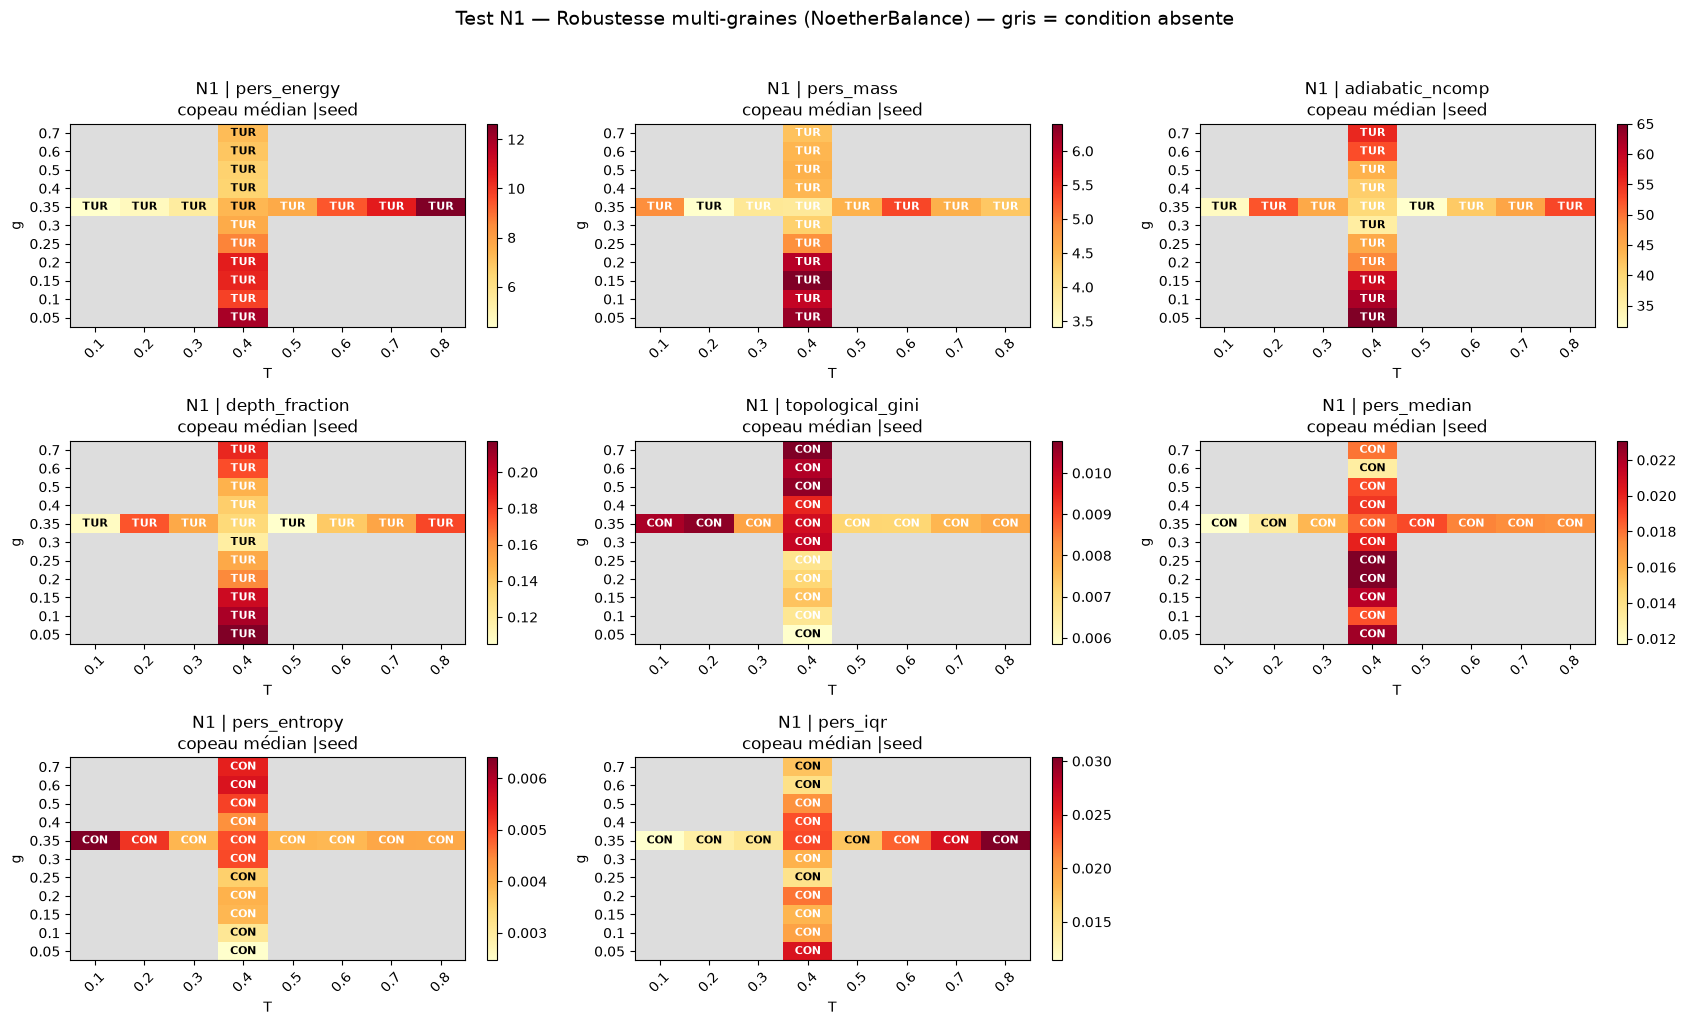

In [9]:
# -----------------------------------------------------------------------------
# N1. PLOT — heatmaps copeau médian + régime (grille g x T partielle : cases vides masquées)
# -----------------------------------------------------------------------------
def plot_N1(rob):
    if not rob:
        print("N1 : rien à tracer"); return
    Gs = sorted({k[0] for k in rob}); Ts = sorted({k[1] for k in rob})
    fig, axes = plt.subplots(3, 3, figsize=(17, 10)); axes = axes.flatten()
    cmap = plt.get_cmap("YlOrRd").copy(); cmap.set_bad("#dddddd")
    for idx, cname in enumerate(CHARGES):
        ax = axes[idx]
        mat = np.full((len(Gs), len(Ts)), np.nan)
        for i, g in enumerate(Gs):
            for j, T in enumerate(Ts):
                r = rob.get((g, T, cname))
                if r: mat[i, j] = r.get("copeau_mediane", np.nan)
        im = ax.imshow(np.ma.masked_invalid(mat), cmap=cmap, aspect="auto", origin="lower")
        ax.set_xticks(range(len(Ts))); ax.set_xticklabels([f"{t:g}" for t in Ts], rotation=45)
        ax.set_yticks(range(len(Gs))); ax.set_yticklabels([f"{g:g}" for g in Gs])
        ax.set_xlabel("T"); ax.set_ylabel("g"); ax.set_title(f"N1 | {cname}\ncopeau médian |seed")
        plt.colorbar(im, ax=ax, fraction=0.046)
        vmax = np.nanmax(mat) if np.isfinite(mat).any() else 0
        for i, g in enumerate(Gs):
            for j, T in enumerate(Ts):
                r = rob.get((g, T, cname))
                if r:
                    ax.text(j, i, REGIME_ABBR.get(r.get("regime", ""), "?"), ha="center", va="center", fontsize=8,
                            weight="bold", color="white" if np.isfinite(mat[i, j]) and mat[i, j] > 0.6 * vmax else "black")
    axes[-1].axis("off")
    plt.suptitle("Test N1 — Robustesse multi-graines (NoetherBalance) — gris = condition absente", fontsize=14, y=1.02)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N1_robustesse_multigraines.png"), dpi=150, bbox_inches="tight")
    plt.show()

safe_run("N1 plot", plot_N1, robustesse_n1)

## Test N2 / N8 — Stabilité dimensionnelle (vrai plongement, famille C)
**Question** : la topologie H0 est-elle conservée sous translation en dimension d'embedding `m` ? `dQ / dm = sigma_m`
**Changement majeur** : plus de troncature `X[:, :m]` — chaque `m` (2…8) est un **vrai plongement de Takens** (famille C, g=0.35, T=0.40). Chaque graine donne une série de diagrammes en `m`.
**N8 (04b)** : `pers_energy` reste-t-il turbulent avec un vrai plongement, et la normalisation (`max_death`) change-t-elle le verdict ?
**Rappel** : après `standardiser`, les distances croissent avec la dimension (2m colonnes) — la lecture brute des charges extensives est biaisée par construction.

In [10]:
# -----------------------------------------------------------------------------
# N2 / N8. STABILITÉ DIMENSIONNELLE (famille C)
# -----------------------------------------------------------------------------
def run_N2():
    Ms = valeurs("C", "m", g=0.35, T=0.40)
    if len(Ms) < 2:
        raise RuntimeError(f"Famille C incomplète (m disponibles : {Ms}) -> relancer la cellule C de 04b")
    per_m = {m: diagrammes("C", 0.35, 0.40, m=m) for m in Ms}
    seeds = sorted(set.intersection(*[set(v[0]) for v in per_m.values()]))
    print(f"N2 : m = {Ms} ; {len(seeds)} graines communes")
    res = {}      # (mode, charge) -> {"rob_par_graine": [...], "Q": array (n_m, n_seeds)}
    for mode in NORM_MODES:
        for cname, cfn in CHARGES.items():
            Q = np.full((len(Ms), len(seeds)), np.nan)
            robs = []
            for k, s in enumerate(seeds):
                dg_m, X_m = [], []
                for m in Ms:
                    ss, Xs, dg = per_m[m]
                    i = ss.index(s)
                    dg_m.append(normaliser_dgm(dg[i], mode, dim=Xs[i].shape[1])); X_m.append(Xs[i])
                for j, d in enumerate(dg_m):
                    try: Q[j, k] = float(cfn(d))
                    except Exception: pass
                r = bilan(dg_m, np.array(Ms), "dim", cfn, cname, tol=0.01, label=f"N2 {mode} seed{s}")
                if r: robs.append(r)
            res[(mode, cname)] = {"rob": robs, "Q": Q}
            if robs:
                reg = Counter(r.get("regime") for r in robs).most_common(1)[0][0]
                cop = float(np.nanmedian([r.get("copeau_mediane", np.nan) for r in robs]))
                add_row(test="N2", famille="C", param="dim", charge=cname, norm=mode, g=0.35, T=0.40, seed="ALL",
                        copeau_mediane=cop, regime=reg, n_samples=len(robs),
                        note="N8 : verdict pers_energy" if cname == "pers_energy" else "")
            # dispersion inter-graines moyenne sur les m
            sds = [stats_inter(Q[j])[1] for j in range(len(Ms))]
            add_row(test="N2", famille="C", param="dim", charge=cname, norm=mode, g=0.35, T=0.40, seed="ALL",
                    std_inter_graines=float(np.nanmean(sds)), note="écart-type inter-graines moyen sur m")
    print("\n--- N2 | verdict par charge (régime majoritaire sur les graines ; copeau médian) ---")
    for cname in CHARGES:
        ligne = []
        for mode in NORM_MODES:
            robs = res[("%s" % mode, cname)]["rob"]
            if robs:
                reg = Counter(r.get("regime") for r in robs).most_common(1)[0][0]
                cop = float(np.nanmedian([r.get("copeau_mediane", np.nan) for r in robs]))
                ligne.append(f"{mode}: {reg} ({cop:.3f})")
            else:
                ligne.append(f"{mode}: n/a")
        print(f"{cname:18s} | " + " | ".join(ligne))
    # N8 : verdict explicite
    for mode in NORM_MODES:
        robs = res[(mode, "pers_energy")]["rob"]
        if robs:
            print(f"N8 | pers_energy [{mode}] -> {Counter(r.get('regime') for r in robs).most_common()}")
    return {"Ms": Ms, "seeds": seeds, "res": res}

n2 = safe_run("N2", run_N2) if RUN["N2"] else None

N2 : m = [2, 3, 4, 5, 6, 7, 8] ; 35 graines communes

--- N2 | verdict par charge (régime majoritaire sur les graines ; copeau médian) ---
pers_energy        | none: turbulent (149.750) | max_death: turbulent (17.952)
pers_mass          | none: turbulent (67.349) | max_death: turbulent (15.814)
adiabatic_ncomp    | none: turbulent (30.000) | max_death: turbulent (30.000)
depth_fraction     | none: turbulent (0.100) | max_death: turbulent (0.100)
topological_gini   | none: conservatif (0.015) | max_death: conservatif (0.015)
pers_median        | none: turbulent (0.228) | max_death: adiabatique (0.053)
pers_entropy       | none: conservatif (0.005) | max_death: conservatif (0.005)
pers_iqr           | none: conservatif (0.025) | max_death: conservatif (0.014)
N8 | pers_energy [none] -> [('turbulent', 35)]
N8 | pers_energy [max_death] -> [('turbulent', 35)]


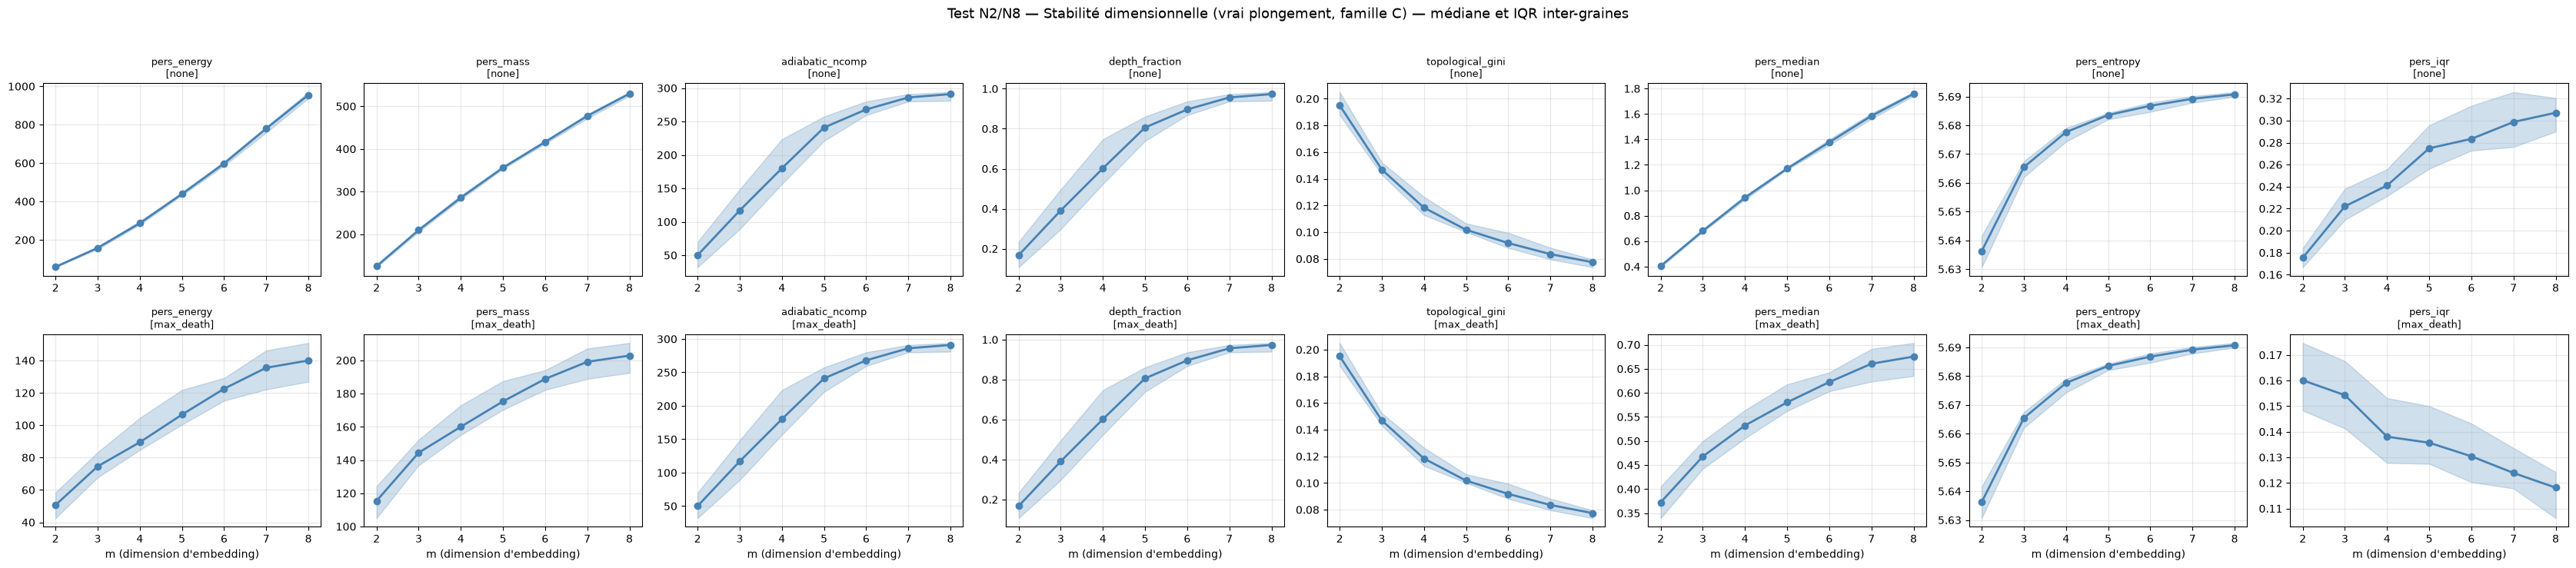

In [11]:
# -----------------------------------------------------------------------------
# N2. PLOT — charges vs m (médiane et bande inter-quartile sur les graines), brut vs normalisé
# -----------------------------------------------------------------------------
def plot_N2(n2):
    if not n2: print("N2 : rien à tracer"); return
    Ms, res = n2["Ms"], n2["res"]
    fig, axes = plt.subplots(len(NORM_MODES), len(CHARGES), figsize=(4.2 * len(CHARGES), 3.6 * len(NORM_MODES)), squeeze=False)
    for r_i, mode in enumerate(NORM_MODES):
        for c_i, cname in enumerate(CHARGES):
            ax = axes[r_i, c_i]; Q = res[(mode, cname)]["Q"]
            med = np.nanmedian(Q, axis=1); q1 = np.nanpercentile(Q, 25, axis=1); q3 = np.nanpercentile(Q, 75, axis=1)
            ax.plot(Ms, med, marker="o", color="steelblue", lw=2); ax.fill_between(Ms, q1, q3, alpha=0.25, color="steelblue")
            ax.set_title(f"{cname}\n[{mode}]", fontsize=9); ax.set_xticks(Ms); ax.grid(True, alpha=0.3)
            if r_i == len(NORM_MODES) - 1: ax.set_xlabel("m (dimension d'embedding)")
    plt.suptitle("Test N2/N8 — Stabilité dimensionnelle (vrai plongement, famille C) — médiane et IQR inter-graines", fontsize=13, y=1.02)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N2_stabilite_dimensionnelle.png"), dpi=150, bbox_inches="tight")
    plt.show()

safe_run("N2 plot", plot_N2, n2)

## Test N3 — Anatomie noetherienne : balayages 1D (T en famille A, g en famille D)
**Question** : quelles charges répondent à T ? à g ? `dQ / dT = sigma_T` et `dQ / dg = sigma_g`.
**Changement** : la grille g×T complète n'existe pas (A = 1 valeur de g, D = 1 valeur de T). On soumet donc **deux grilles 1D** à `analyze_grille_couplage` ; chaque cellule = diagramme **représentatif** (graine à énergie médiane) au lieu de la concaténation de toutes les graines (la concaténation faisait croître `pers_energy` / `pers_mass` avec le nombre de graines).
**Point d'attention** : si le module refuse les grilles 1D, l'erreur est journalisée et les sections N6 / N9 prennent le relais (balayages 1D avec `compute_balance`).

In [12]:
# -----------------------------------------------------------------------------
# N3. BALAYAGES 1D via NoetherPipeline.analyze_grille_couplage
# -----------------------------------------------------------------------------
def representant(dgms, mode=PROXY_MODE):
    if mode == "concat":      # comportement v1 (déconseillé : charges extensives gonflées)
        pairs = np.vstack([_pairs(d) for d in dgms])
        return PersDiagram(pairs=pairs, param=dgms[0].param if dgms else {})
    e = np.array([float(TopologicalCharges.persistence_energy(d)) for d in dgms])
    return dgms[int(np.argmin(np.abs(e - np.median(e))))]

def trouver_cle(results, charge, sweep, val_fixe):
    """Clé de robustesse : exacte (« <charge>_vs_T_g<g> » / « <charge>_vs_g_T<T> »), sinon recherche tolérante."""
    rob = (results or {}).get("robustesse", {}) or {}
    exacte = f"{charge}_vs_{sweep}_{'g' if sweep == 'T' else 'T'}{val_fixe}"
    if exacte in rob: return exacte
    cands = [k for k in rob if k.startswith(f"{charge}_vs_{sweep}")]
    return cands[0] if cands else None
def run_N3():
    Ts = valeurs("A", "T", g=0.35, m=3)
    Gs = valeurs("D", "g", T=0.40, m=3)

    # Balayage 2x2
    grid_2x2 = {(g, T): dgm for g, T, dgm in zip(Gs, Ts, dgms[:len(Gs)*len(Ts)])}
    r22 = essai("analyze_grille_couplage grille 2x2", lambda: NoetherPipeline.analyze_grille_couplage(grid_2x2, Gs, Ts))

    # Balayage 1D en T
    grid_1DT = {(0.35, T): dgm for T, dgm in zip(Ts, dgms[:len(Ts)])}
    r1T = essai("analyze_grille_couplage grille 1D en T", lambda: NoetherPipeline.analyze_grille_couplage(grid_1DT, [0.35], Ts))

    # Balayage 1D en g
    grid_1DG = {(g, 0.40): dgm for g, dgm in zip(Gs, dgms[len(Ts):len(Ts)+len(Gs)])}
    r1G = essai("analyze_grille_couplage grille 1D en g", lambda: NoetherPipeline.analyze_grille_couplage(grid_1DG, Gs, [0.40]))

    # Stocker les résultats
    results = {
        "2x2": r22,
        "1D-T": r1T,
        "1D-g": r1G
    }

    # Vérification des résultats
    for name, res in results.items():
        if res and "robustesse" in res:
            for charge_name in CHARGES.keys():
                if charge_name in res["robustesse"]:
                    print(f"{name} - {charge_name}: {res['robustesse'][charge_name]}")

    return results

In [13]:

def run_N3():
    Ts = valeurs("A", "T", g=0.35, m=3); Gs = valeurs("D", "g", T=0.40, m=3)
    out = {"T": None, "g": None, "Ts": Ts, "Gs": Gs}
    gridT = {(0.35, T): representant(diagrammes("A", 0.35, T)[2]) for T in Ts if diagrammes("A", 0.35, T)[2]}
    gridG = {(g, 0.40): representant(diagrammes("D", g, 0.40)[2]) for g in Gs if diagrammes("D", g, 0.40)[2]}
    out["T"] = safe_run("N3 grille 1D en T", NoetherPipeline.analyze_grille_couplage, gridT, [0.35], sorted({k[1] for k in gridT}))
    out["g"] = safe_run("N3 grille 1D en g", NoetherPipeline.analyze_grille_couplage, gridG, sorted({k[0] for k in gridG}), [0.40])
    for nom, r in (("T (g=0.35)", out["T"]), ("g (T=0.40)", out["g"])):
        print(f"\n--- N3 | balayage en {nom} ---")
        if r is None:
            print("   (grille refusée par le module : voir N6 / N9)"); continue
        print("   clés de robustesse :", sorted((r.get("robustesse") or {}).keys())[:6], "...")
        print(summary_report(r))
        for key, rob in sorted((r.get("robustesse") or {}).items()):
            add_row(test="N3", param=key, copeau_mediane=rob.get("copeau_mediane", ""), copeau_spread=rob.get("copeau_spread", ""),
                    regime=rob.get("regime", ""), n_samples=rob.get("n_samples", ""))
    return out

results_n3 = safe_run("N3", run_N3) if RUN["N3"] else None


--- N3 | balayage en T (g=0.35) ---
   clés de robustesse : ['adiabatic_ncomp_vs_T_g0.35', 'depth_fraction_vs_T_g0.35', 'pers_energy_vs_T_g0.35', 'pers_mass_vs_T_g0.35', 'topological_gini_vs_T_g0.35', 'topological_momentum_vs_T_g0.35'] ...
RAPPORT NOETHER-SURPHIN


pers_energy_vs_T_g0.35
  Copeau mediane : 349.3707
  Copeau spread  : 34.4039
  Regime         : TURBULENT
  N echantillons : 7

pers_mass_vs_T_g0.35
  Copeau mediane : 255.5849
  Copeau spread  : 67.4167
  Regime         : TURBULENT
  N echantillons : 7

adiabatic_ncomp_vs_T_g0.35
  Copeau mediane : 500.0000
  Copeau spread  : 519.5445
  Regime         : TURBULENT
  N echantillons : 7

depth_fraction_vs_T_g0.35
  Copeau mediane : 1.6722
  Copeau spread  : 1.7376
  Regime         : TURBULENT
  N echantillons : 7

topological_momentum_vs_T_g0.35
  Copeau mediane : 0.8548
  Copeau spread  : 0.2255
  Regime         : TURBULENT
  N echantillons : 7

topological_gini_vs_T_g0.35
  Copeau mediane : 0.1136
  Copeau spread  : 0.0539

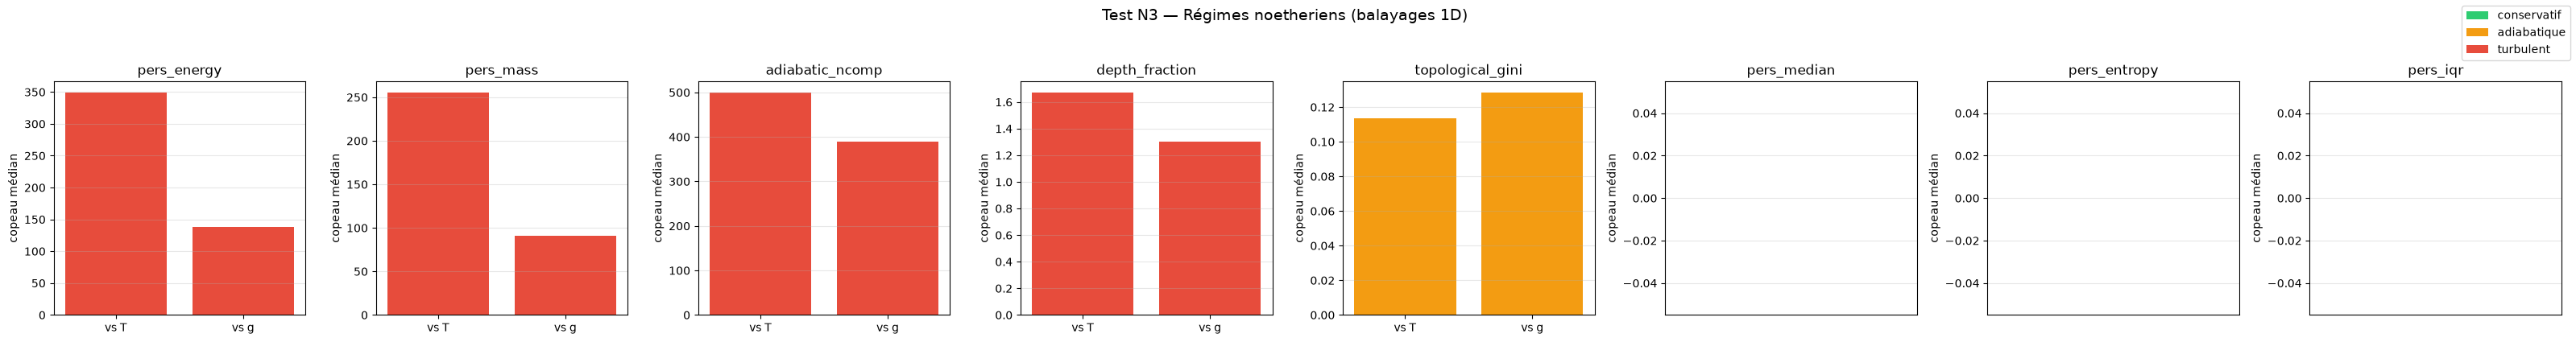

In [14]:
# -----------------------------------------------------------------------------
# N3. PLOT — copeau médian par charge pour les deux balayages, coloré par régime
# -----------------------------------------------------------------------------
def plot_N3(res):
    if not res or (res["T"] is None and res["g"] is None):
        print("N3 : rien à tracer (voir N6 / N9)"); return
    fig, axes = plt.subplots(1, len(CHARGES), figsize=(4 * len(CHARGES), 4)); axes = np.atleast_1d(axes)
    for ax, cname in zip(axes, CHARGES):
        xs, vals, cols, labs = [], [], [], []
        for sweep, fixe, lab in (("T", 0.35, "vs T"), ("g", 0.40, "vs g")):
            r = res[sweep]
            if r is None: continue
            k = trouver_cle(r, cname, sweep, fixe)
            rob = (r.get("robustesse") or {}).get(k) if k else None
            if rob:
                xs.append(len(xs)); vals.append(rob.get("copeau_mediane", np.nan))
                cols.append(REGIME_COLOR.get(rob.get("regime"), "#999999")); labs.append(lab)
        ax.bar(xs, vals, color=cols); ax.set_xticks(xs); ax.set_xticklabels(labs)
        ax.set_title(cname); ax.set_ylabel("copeau médian"); ax.grid(True, alpha=0.3, axis="y")
    fig.legend(handles=[Patch(facecolor=c, label=l) for l, c in REGIME_COLOR.items()], loc="upper right")
    plt.suptitle("Test N3 — Régimes noetheriens (balayages 1D)", fontsize=14, y=1.05)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N3_regimes_grille.png"), dpi=150, bbox_inches="tight")
    plt.show()

safe_run("N3 plot", plot_N3, results_n3)

## Test N4 — Courant de persistance
**Question** : quel est le flux naissance/mort le long de epsilon ? `dN/depsilon = J_birth - J_death = sigma(epsilon)`.
**Correction v1** : le titre disait seed=0 alors que le code chargeait la seed 7 ; la graine est maintenant `REF_SEED` partout. Le MST vient du helper partagé `mst_merges`.
**Ajout** : source intégrée en fonction de T (famille A) pour la graine de référence.

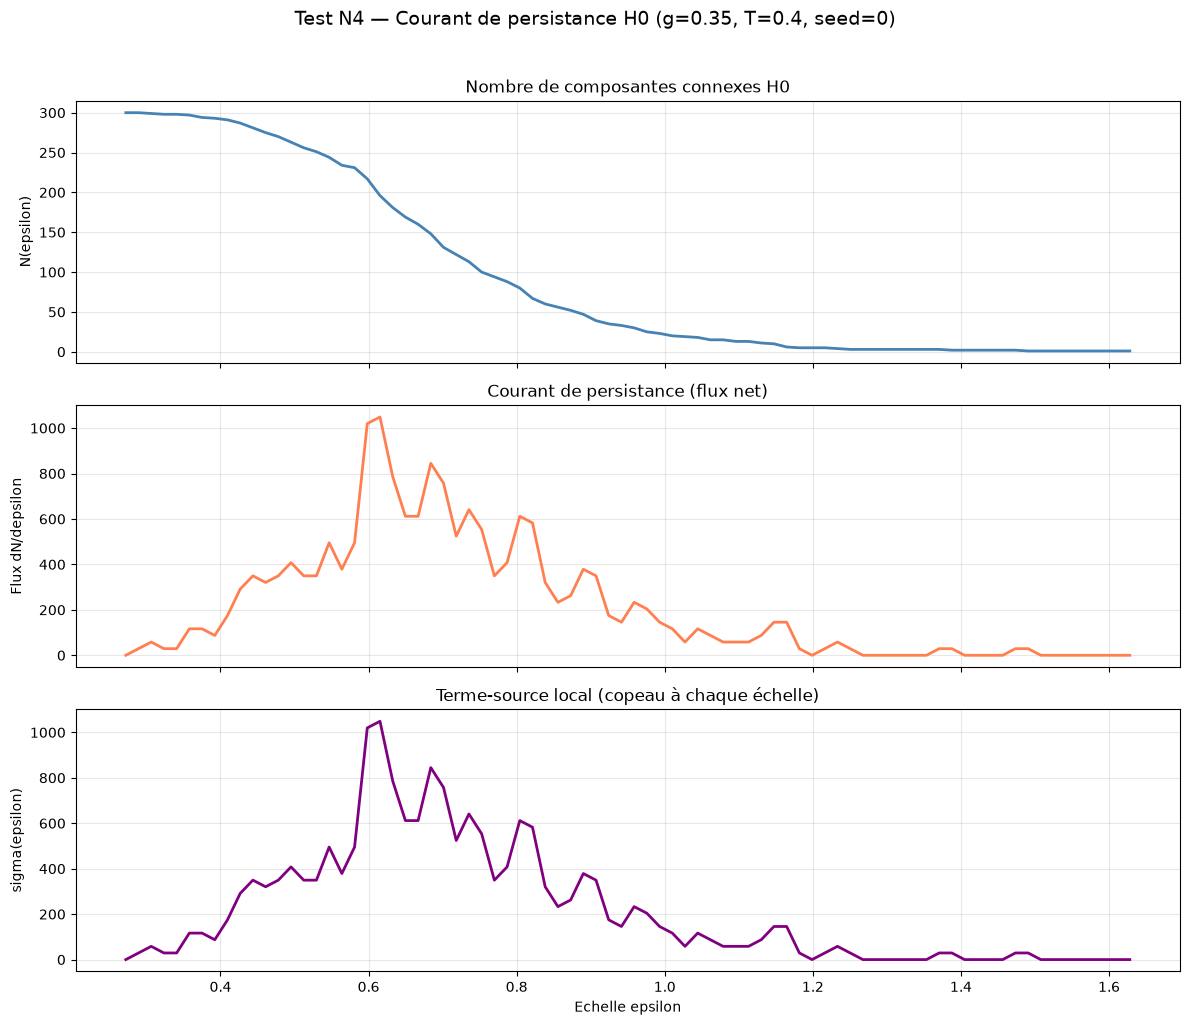

Source intégrée (g=0.35, T=0.4, seed=0) : 299.0000

Source intégrée vs T (seed de référence, famille A) :
   T=0.10 -> 299.0000
   T=0.20 -> 299.0000
   T=0.30 -> 299.0000
   T=0.40 -> 299.0000
   T=0.50 -> 299.0000
   T=0.60 -> 299.0000
   T=0.70 -> 299.0000
   T=0.80 -> 299.0000


299.0000000000001

In [15]:
# -----------------------------------------------------------------------------
# N4. COURANT DE PERSISTANCE
# -----------------------------------------------------------------------------
def courant(X):
    merges = mst_merges(X)
    return PersistenceCurrent.from_mst(merges, n_points=X.shape[0], n_bins=N_BINS_CURRENT)

def run_N4():
    g, T = 0.35, 0.40
    X_ref, _ = load_nuage(g, T, REF_SEED, "A")
    cur = courant(X_ref)
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    axes[0].plot(cur.epsilon_grid, cur.ncomp, color="steelblue", lw=2); axes[0].set_ylabel("N(epsilon)")
    axes[0].set_title("Nombre de composantes connexes H0"); axes[0].grid(True, alpha=0.3)
    axes[1].plot(cur.epsilon_grid, cur.flux, color="coral", lw=2); axes[1].set_ylabel("Flux dN/depsilon")
    axes[1].set_title("Courant de persistance (flux net)"); axes[1].grid(True, alpha=0.3)
    axes[2].plot(cur.epsilon_grid, cur.source, color="purple", lw=2); axes[2].set_ylabel("sigma(epsilon)")
    axes[2].set_xlabel("Echelle epsilon"); axes[2].set_title("Terme-source local (copeau à chaque échelle)"); axes[2].grid(True, alpha=0.3)
    plt.suptitle(f"Test N4 — Courant de persistance H0 (g={g}, T={T}, seed={REF_SEED})", fontsize=14, y=1.02)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N4_courant_persistance.png"), dpi=150, bbox_inches="tight"); plt.show()
    src = PersistenceCurrent.integrated_source(cur)
    print(f"Source intégrée (g={g}, T={T}, seed={REF_SEED}) : {src:.4f}")
    add_row(test="N4", famille="A", param="eps", charge="source_integree", g=g, T=T, m=3, seed=REF_SEED, valeur_mediane=src)
    # source intégrée vs T
    print("\nSource intégrée vs T (seed de référence, famille A) :")
    for Tk in valeurs("A", "T", g=0.35, m=3):
        try:
            Xk, _ = load_nuage(0.35, Tk, REF_SEED, "A")
            sk = PersistenceCurrent.integrated_source(courant(Xk))
            print(f"   T={Tk:.2f} -> {sk:.4f}")
            add_row(test="N4", famille="A", param="T", param_value=Tk, charge="source_integree", g=0.35, T=Tk, m=3, seed=REF_SEED, valeur_mediane=sk)
        except Exception as e:
            print(f"   T={Tk:.2f} -> ❌ {e}"); ERRORS.append((f"N4 T={Tk}", str(e)))
    return src

safe_run("N4", run_N4) if RUN["N4"] else None

## Test N5 — Identités de Ward (copeau comme commutateur)
**Question** : le copeau est-il la norme du commutateur `[partial_g, H^0]` ? `|| [partial_g, H^0] || = Copeau(g)`.
**Changement** : famille D complète (11 valeurs de g, T=0.40) au lieu de 2 valeurs. Le bottleneck est passé via `bottleneck_distance_fn=BOTTLENECK_FN` (adaptateur : `bottleneck_H0` reçoit des tableaux de morts, pas des `PersDiagram`). Le message « _approx_bottleneck used » affiché par le module est un libellé trompeur : il s'imprime dès qu'une fonction est fournie.

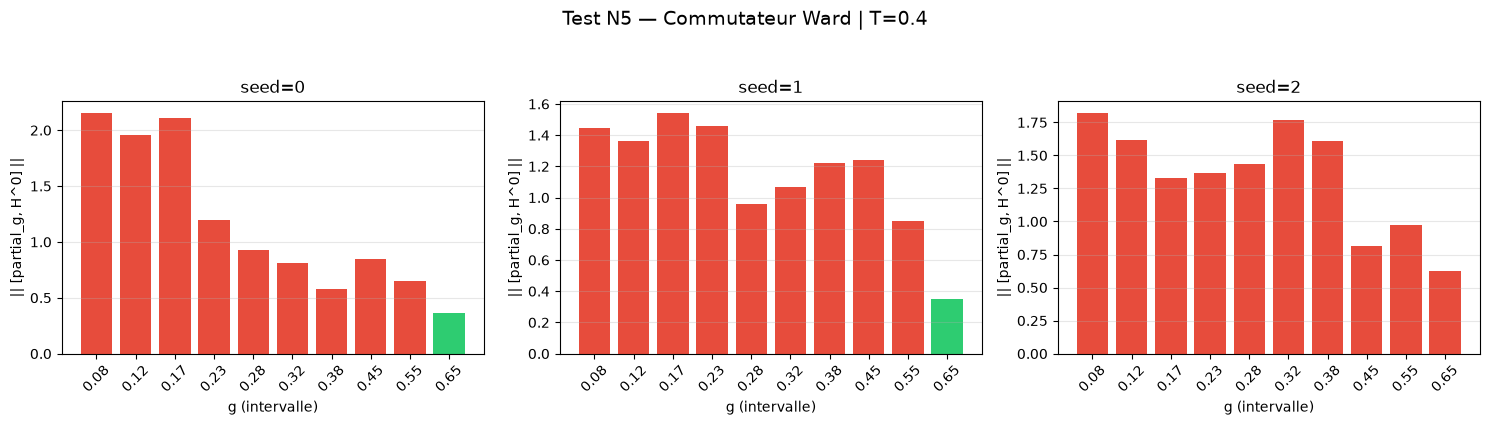

In [16]:
# -----------------------------------------------------------------------------
# N5. IDENTITÉS DE WARD — commutateur le long de g (famille D)
# -----------------------------------------------------------------------------
def run_N5(T_fix=0.40, seeds_ward=(0, 1, 2)):
    Gs = valeurs("D", "g", T=T_fix, m=3)
    if len(Gs) < 2:
        raise RuntimeError(f"Famille D incomplète (g disponibles : {Gs}) -> relancer la cellule D de 04b")
    fig, axes = plt.subplots(1, len(seeds_ward), figsize=(5 * len(seeds_ward), 4), squeeze=False); axes = axes[0]
    out = {}
    for ax, seed in zip(axes, seeds_ward):
        dg = []
        for g in Gs:
            _, _, d = diagrammes("D", g, T_fix, seeds=[seed])
            if d: dg.append((g, d[0]))
        if len(dg) < 2:
            ax.text(0.5, 0.5, "Données insuffisantes", ha="center", transform=ax.transAxes); continue
        g_vals = np.array([g for g, _ in dg]); copeaux = []
        for i in range(len(dg) - 1):
            c = WardIdentities.commutator_copeau(dg[i][1], dg[i + 1][1], g_vals[i], g_vals[i + 1],
                                                  bottleneck_distance_fn=BOTTLENECK_FN)
            copeaux.append(c)
            add_row(test="N5", famille="D", param="g", param_value=round(float((g_vals[i] + g_vals[i + 1]) / 2), 4),
                    charge="ward_copeau", g=round(float(g_vals[i]), 2), T=T_fix, m=3, seed=seed, valeur_mediane=c)
        g_mid = (g_vals[:-1] + g_vals[1:]) / 2
        ax.bar(range(len(copeaux)), copeaux, color=["#2ecc71" if c < 0.5 else "#e74c3c" for c in copeaux])
        ax.set_xticks(range(len(copeaux))); ax.set_xticklabels([f"{x:.2f}" for x in g_mid], rotation=45)
        ax.set_xlabel("g (intervalle)"); ax.set_ylabel("|| [partial_g, H^0] ||"); ax.set_title(f"seed={seed}")
        ax.grid(True, alpha=0.3, axis="y"); out[seed] = copeaux
    plt.suptitle(f"Test N5 — Commutateur Ward | T={T_fix}", fontsize=14, y=1.05)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N5_ward_commutator.png"), dpi=150, bbox_inches="tight"); plt.show()
    return out

ward = safe_run("N5", run_N5) if RUN["N5"] else None

## Test N6 — Famille A : `depth_fraction` devient-il turbulent au-delà d'un T_crit ?
Balayage fin en T (0.10…0.80, g=0.35, 12 graines). Pour chaque charge : médiane, écart-type inter-graines, CV (brut et normalisé), régime par graine le long de T (`compute_balance`, paramètre `T`), et **ARI / VI entre partitions H0 consécutives en T, à graine fixe**. `T_crit` est estimé comme l'intervalle de plus forte variation (indicatif, pas un test) avec la fraction de graines d'accord.

N6 : 8 valeurs de T, 35 graines
   T_crit [none     ] pers_energy        intervalle modal [0.30, 0.40] ; 54% des graines d'accord
   T_crit [none     ] pers_mass          intervalle modal [0.10, 0.20] ; 77% des graines d'accord
   T_crit [none     ] adiabatic_ncomp    intervalle modal [0.10, 0.20] ; 46% des graines d'accord
   T_crit [none     ] depth_fraction     intervalle modal [0.10, 0.20] ; 46% des graines d'accord
   T_crit [none     ] topological_gini   intervalle modal [0.10, 0.20] ; 94% des graines d'accord
   T_crit [none     ] pers_median        intervalle modal [0.10, 0.20] ; 66% des graines d'accord
   T_crit [none     ] pers_entropy       intervalle modal [0.10, 0.20] ; 97% des graines d'accord
   T_crit [none     ] pers_iqr           intervalle modal [0.40, 0.50] ; 29% des graines d'accord
   T_crit [max_death] pers_energy        intervalle modal [0.10, 0.20] ; 63% des graines d'accord
   T_crit [max_death] pers_mass          intervalle modal [0.10, 0.20] ; 69% des grain

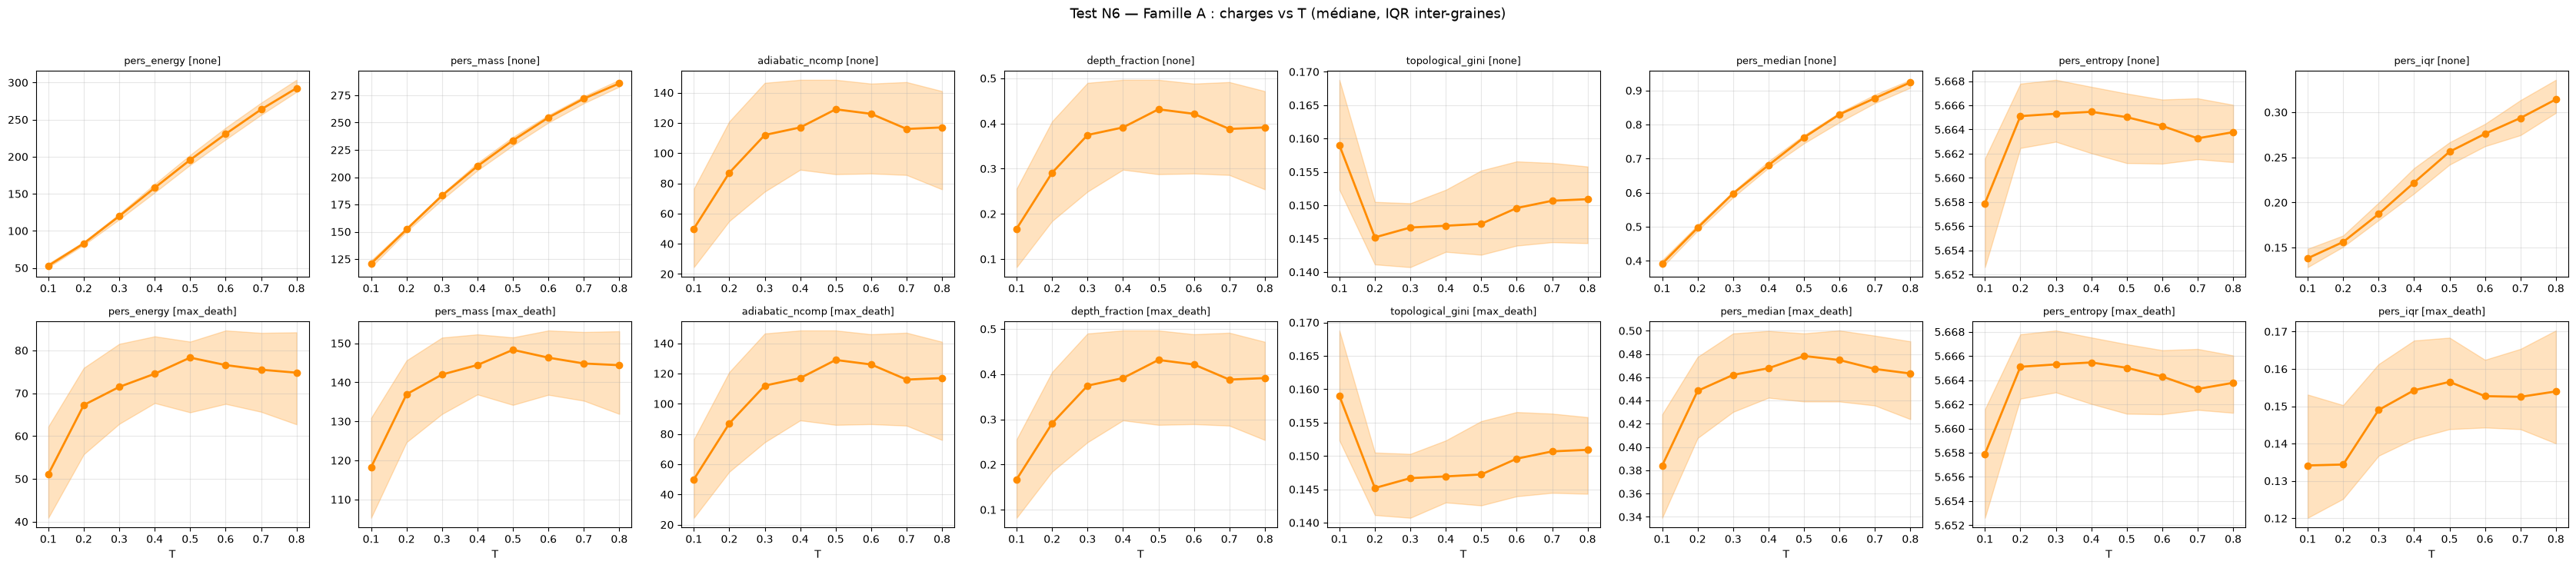

In [17]:
# -----------------------------------------------------------------------------
# N6. FAMILLE A — balayage fin en T
# -----------------------------------------------------------------------------
def run_N6():
    Ts = valeurs("A", "T", g=0.35, m=3)
    if len(Ts) < 3: raise RuntimeError(f"Famille A incomplète (T disponibles : {Ts})")
    per_T = {T: diagrammes("A", 0.35, T) for T in Ts}
    seeds = sorted(set.intersection(*[set(v[0]) for v in per_T.values()]))
    idx = {T: {s: per_T[T][0].index(s) for s in seeds} for T in Ts}
    out = {"Ts": Ts, "seeds": seeds, "Q": {}}
    print(f"N6 : {len(Ts)} valeurs de T, {len(seeds)} graines")
    for mode in NORM_MODES:
        for cname, cfn in CHARGES.items():
            Q = np.full((len(Ts), len(seeds)), np.nan)
            for a, T in enumerate(Ts):
                _, Xs, dg = per_T[T]
                for b, s in enumerate(seeds):
                    i = idx[T][s]
                    try: Q[a, b] = float(cfn(normaliser_dgm(dg[i], mode, dim=Xs[i].shape[1])))
                    except Exception: pass
                med, sd, cv = stats_inter(Q[a])
                add_row(test="N6", famille="A", param="T", param_value=T, charge=cname, norm=mode, g=0.35, T=T, m=3,
                        seed="ALL", valeur_mediane=med, std_inter_graines=sd, cv=cv)
            out["Q"][(mode, cname)] = Q
            try:
                ci, modal, frac = crit_param(Q, Ts)
                print(f"   T_crit [{mode:9s}] {cname:18s} intervalle modal [{Ts[modal]:.2f}, {Ts[modal+1]:.2f}] ; {100*frac:.0f}% des graines d'accord")
                add_row(test="N6", famille="A", param="T_crit", param_value=f"{Ts[modal]}-{Ts[modal+1]}", charge=cname, norm=mode,
                        g=0.35, valeur_mediane=frac, note="fraction de graines d'accord (indicatif)")
            except Exception as e:
                print(f"   T_crit {cname}: n/a ({e})")
    # régime par graine le long de T (module)
    print("\n--- N6 | régime le long de T, par graine (régime majoritaire ; copeau médian) ---")
    for cname, cfn in CHARGES.items():
        robs = []
        for s in seeds:
            dg_T = [per_T[T][2][idx[T][s]] for T in Ts]
            r = bilan(dg_T, np.array(Ts), "T", cfn, cname, tol=0.05, label=f"N6 seed{s}")
            if r: robs.append(r)
        if robs:
            reg = Counter(r.get("regime") for r in robs).most_common(1)[0]
            cop = float(np.nanmedian([r.get("copeau_mediane", np.nan) for r in robs]))
            print(f"{cname:18s} | {reg[0]} ({reg[1]}/{len(robs)} graines) | copeau_med={cop:.4f}")
            add_row(test="N6", famille="A", param="T", charge=cname, norm="none", g=0.35, seed="ALL",
                    copeau_mediane=cop, regime=reg[0], n_samples=len(robs))
    # ARI / VI entre T consécutifs (graine fixe)
    ari_m, vi_m = np.zeros(len(Ts) - 1), np.zeros(len(Ts) - 1)
    for a in range(len(Ts) - 1):
        A_, V_ = [], []
        for s in seeds:
            la = partition_labels(per_T[Ts[a]][1][idx[Ts[a]][s]]); lb = partition_labels(per_T[Ts[a+1]][1][idx[Ts[a+1]][s]])
            A_.append(ari(la, lb)); V_.append(vi(la, lb))
        ari_m[a], vi_m[a] = np.mean(A_), np.mean(V_)
        add_row(test="N6", famille="A", param="T", param_value=f"{Ts[a]}-{Ts[a+1]}", charge=f"ARI_k{K_PART}", g=0.35,
                seed="ALL", valeur_mediane=ari_m[a], note="ARI moyen entre T consécutifs, graine fixe")
        add_row(test="N6", famille="A", param="T", param_value=f"{Ts[a]}-{Ts[a+1]}", charge=f"VI_k{K_PART}", g=0.35,
                seed="ALL", valeur_mediane=vi_m[a], note="VI moyen entre T consécutifs, graine fixe")
    out["ari"], out["vi"] = ari_m, vi_m
    print("\nARI moyen entre T consécutifs :", np.round(ari_m, 3))
    return out

n6 = safe_run("N6", run_N6) if RUN["N6"] else None

def plot_N6(n6):
    if not n6: print("N6 : rien à tracer"); return
    Ts = n6["Ts"]
    fig, axes = plt.subplots(len(NORM_MODES), len(CHARGES), figsize=(4.2 * len(CHARGES), 3.6 * len(NORM_MODES)), squeeze=False)
    for r_i, mode in enumerate(NORM_MODES):
        for c_i, cname in enumerate(CHARGES):
            ax = axes[r_i, c_i]; Q = n6["Q"][(mode, cname)]
            med = np.nanmedian(Q, axis=1); q1 = np.nanpercentile(Q, 25, axis=1); q3 = np.nanpercentile(Q, 75, axis=1)
            ax.plot(Ts, med, marker="o", color="darkorange", lw=2); ax.fill_between(Ts, q1, q3, alpha=0.25, color="darkorange")
            ax.set_title(f"{cname} [{mode}]", fontsize=9); ax.grid(True, alpha=0.3)
            if r_i == len(NORM_MODES) - 1: ax.set_xlabel("T")
    plt.suptitle("Test N6 — Famille A : charges vs T (médiane, IQR inter-graines)", fontsize=13, y=1.02)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N6_famille_A_T.png"), dpi=150, bbox_inches="tight"); plt.show()

safe_run("N6 plot", plot_N6, n6)

## Test N7 — Famille B : les témoins purs sont-ils conservatifs ?
Témoins sans couplage ni bruit (g=0, T=0), 12 graines chacun : `rossler_pur`, `double_puits`, `sinus`. Le **copeau médian** (dérivée par rapport à la graine) est remplacé par la **dispersion inter-graines** : écart-type et CV des charges, brutes et normalisées. Un témoin « conservatif » doit avoir un CV faible sur les charges normalisées.
**Rappel** : les nuages B ont 1 canal (m colonnes) et non 2 : comparer les CV (sans dimension), pas les valeurs absolues, avec les autres familles.
**Point scientifique** : les trois témoins ne sont pas déterministes d'une graine à l'autre (fréquence aléatoire du sinus, conditions initiales, bruit du double-puits) : une dispersion non nulle n'est donc pas, en soi, un défaut du module.

N7 : témoins = ['double_puits', 'rossler_pur', 'sinus']

--- N7 | CV inter-graines [none] ---
témoin               pers_energy         pers_mass   adiabatic_ncomp    depth_fraction  topological_gini       pers_median      pers_entropy          pers_iqr
double_puits               0.553             0.233             0.575             0.575             0.165             0.280             0.019             0.235
rossler_pur                0.160             0.073             0.494             0.494             0.141             0.080             0.011             0.213
sinus                      0.368             0.209             0.310             0.310             0.300             0.273             0.018             0.228

--- N7 | CV inter-graines [max_death] ---
témoin               pers_energy         pers_mass   adiabatic_ncomp    depth_fraction  topological_gini       pers_median      pers_entropy          pers_iqr
double_puits               0.406             0.267             0.575

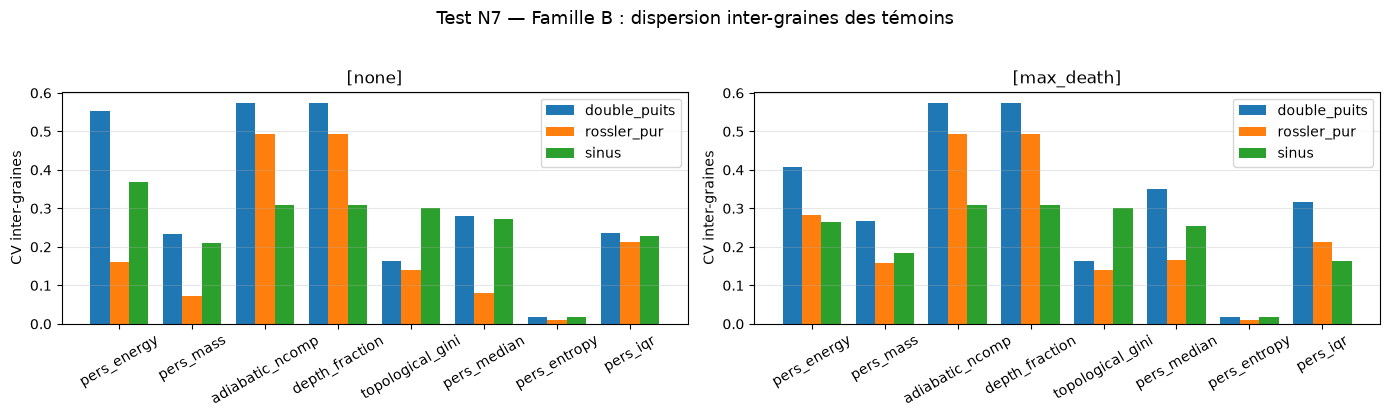

In [18]:
# -----------------------------------------------------------------------------
# N7. FAMILLE B — témoins topologiques
# -----------------------------------------------------------------------------
def run_N7():
    variantes = sorted({r["variante"] for r in INDEX if r["famille"] == "B"})
    if not variantes: raise RuntimeError("Famille B absente -> relancer la cellule B de 04b")
    print(f"N7 : témoins = {variantes}")
    out = {}
    for v in variantes:
        seeds, Xs, dg = diagrammes("B", 0.0, 0.0, m=3, variante=v)
        for mode in NORM_MODES:
            for cname, cfn in CHARGES.items():
                q = charge_array(dg, Xs, cfn, mode)
                med, sd, cv = stats_inter(q)
                out[(v, mode, cname)] = (med, sd, cv)
                add_row(test="N7", famille="B", variante=v, param="seed", charge=cname, norm=mode, g=0.0, T=0.0, m=3,
                        seed="ALL", n_samples=len(seeds), valeur_mediane=med, std_inter_graines=sd, cv=cv)
    for mode in NORM_MODES:
        print(f"\n--- N7 | CV inter-graines [{mode}] ---")
        print(f"{'témoin':14s} " + " ".join(f"{c:>17s}" for c in CHARGES))
        for v in variantes:
            print(f"{v:14s} " + " ".join(f"{out[(v, mode, c)][2]:17.3f}" for c in CHARGES))
    fig, axes = plt.subplots(1, len(NORM_MODES), figsize=(7 * len(NORM_MODES), 4), squeeze=False); axes = axes[0]
    w = 0.8 / max(1, len(variantes)); xs = np.arange(len(CHARGES))
    for ax, mode in zip(axes, NORM_MODES):
        for k, v in enumerate(variantes):
            ax.bar(xs + k * w, [out[(v, mode, c)][2] for c in CHARGES], width=w, label=v)
        ax.set_xticks(xs + w * (len(variantes) - 1) / 2); ax.set_xticklabels(list(CHARGES), rotation=30)
        ax.set_ylabel("CV inter-graines"); ax.set_title(f"[{mode}]"); ax.legend(); ax.grid(True, alpha=0.3, axis="y")
    plt.suptitle("Test N7 — Famille B : dispersion inter-graines des témoins", fontsize=13, y=1.03)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N7_temoins.png"), dpi=150, bbox_inches="tight"); plt.show()
    return out

n7 = safe_run("N7", run_N7) if RUN["N7"] else None

## Test N9 — Famille D : où se situe g_crit ?
Balayage en g (0.05…0.70, T=0.40, 12 graines). Même méthode que N6 : charges normalisées le long de g, `g_crit` = intervalle de plus forte variation **par graine**, avec la fraction de graines qui s'accordent (reproductibilité), régime par graine (`compute_balance`, paramètre `g`) et ARI entre g consécutifs à graine fixe.
**Attention** : le bruit étant proportionnel à l'écart-type du signal *couplé*, T n'a pas exactement la même signification absolue quand g varie.

N9 : 11 valeurs de g, 35 graines
   g_crit [none     ] pers_energy        intervalle modal [0.10, 0.15] ; 51% des graines d'accord
   g_crit [none     ] pers_mass          intervalle modal [0.10, 0.15] ; 54% des graines d'accord
   g_crit [none     ] adiabatic_ncomp    intervalle modal [0.05, 0.10] ; 29% des graines d'accord
   g_crit [none     ] depth_fraction     intervalle modal [0.05, 0.10] ; 29% des graines d'accord
   g_crit [none     ] topological_gini   intervalle modal [0.05, 0.10] ; 29% des graines d'accord
   g_crit [none     ] pers_median        intervalle modal [0.10, 0.15] ; 46% des graines d'accord
   g_crit [none     ] pers_entropy       intervalle modal [0.15, 0.20] ; 31% des graines d'accord
   g_crit [none     ] pers_iqr           intervalle modal [0.15, 0.20] ; 26% des graines d'accord
   g_crit [max_death] pers_energy        intervalle modal [0.05, 0.10] ; 37% des graines d'accord
   g_crit [max_death] pers_mass          intervalle modal [0.05, 0.10] ; 37% des grai

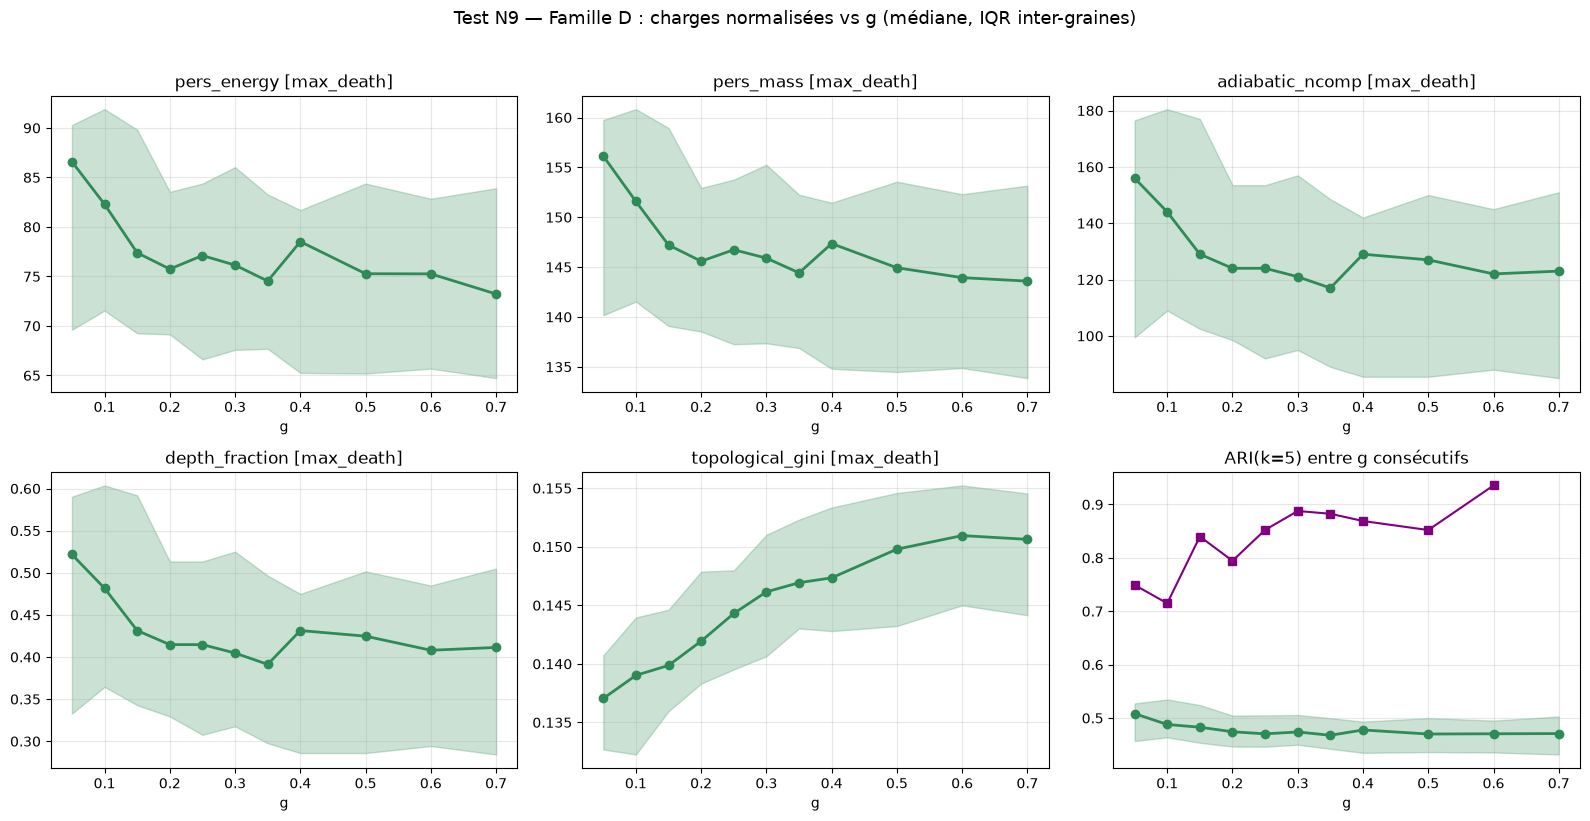

In [19]:
# -----------------------------------------------------------------------------
# N9. FAMILLE D — transition de régime en g
# -----------------------------------------------------------------------------
def run_N9():
    Gs = valeurs("D", "g", T=0.40, m=3)
    if len(Gs) < 3: raise RuntimeError(f"Famille D incomplète (g disponibles : {Gs})")
    per_g = {g: diagrammes("D", g, 0.40) for g in Gs}
    seeds = sorted(set.intersection(*[set(v[0]) for v in per_g.values()]))
    idx = {g: {s: per_g[g][0].index(s) for s in seeds} for g in Gs}
    out = {"Gs": Gs, "seeds": seeds, "Q": {}}
    print(f"N9 : {len(Gs)} valeurs de g, {len(seeds)} graines")
    for mode in NORM_MODES:
        for cname, cfn in CHARGES.items():
            Q = np.full((len(Gs), len(seeds)), np.nan)
            for a, g in enumerate(Gs):
                _, Xs, dg = per_g[g]
                for b, s in enumerate(seeds):
                    i = idx[g][s]
                    try: Q[a, b] = float(cfn(normaliser_dgm(dg[i], mode, dim=Xs[i].shape[1])))
                    except Exception: pass
                med, sd, cv = stats_inter(Q[a])
                add_row(test="N9", famille="D", param="g", param_value=g, charge=cname, norm=mode, g=g, T=0.40, m=3,
                        seed="ALL", valeur_mediane=med, std_inter_graines=sd, cv=cv)
            out["Q"][(mode, cname)] = Q
            try:
                ci, modal, frac = crit_param(Q, Gs)
                print(f"   g_crit [{mode:9s}] {cname:18s} intervalle modal [{Gs[modal]:.2f}, {Gs[modal+1]:.2f}] ; {100*frac:.0f}% des graines d'accord")
                add_row(test="N9", famille="D", param="g_crit", param_value=f"{Gs[modal]}-{Gs[modal+1]}", charge=cname, norm=mode,
                        T=0.40, valeur_mediane=frac, note="fraction de graines d'accord (indicatif)")
            except Exception as e:
                print(f"   g_crit {cname}: n/a ({e})")
    print("\n--- N9 | régime le long de g, par graine ---")
    for cname, cfn in CHARGES.items():
        robs = []
        for s in seeds:
            dg_g = [per_g[g][2][idx[g][s]] for g in Gs]
            r = bilan(dg_g, np.array(Gs), "g", cfn, cname, tol=0.05, label=f"N9 seed{s}")
            if r: robs.append(r)
        if robs:
            reg = Counter(r.get("regime") for r in robs).most_common(1)[0]
            cop = float(np.nanmedian([r.get("copeau_mediane", np.nan) for r in robs]))
            print(f"{cname:18s} | {reg[0]} ({reg[1]}/{len(robs)} graines) | copeau_med={cop:.4f}")
            add_row(test="N9", famille="D", param="g", charge=cname, norm="none", T=0.40, seed="ALL",
                    copeau_mediane=cop, regime=reg[0], n_samples=len(robs))
    ari_m = np.zeros(len(Gs) - 1)
    for a in range(len(Gs) - 1):
        ari_m[a] = np.mean([ari(partition_labels(per_g[Gs[a]][1][idx[Gs[a]][s]]),
                                partition_labels(per_g[Gs[a+1]][1][idx[Gs[a+1]][s]])) for s in seeds])
        add_row(test="N9", famille="D", param="g", param_value=f"{Gs[a]}-{Gs[a+1]}", charge=f"ARI_k{K_PART}", T=0.40,
                seed="ALL", valeur_mediane=ari_m[a], note="ARI moyen entre g consécutifs, graine fixe")
    out["ari"] = ari_m
    print("\nARI moyen entre g consécutifs :", np.round(ari_m, 3))
    return out

n9 = safe_run("N9", run_N9) if RUN["N9"] else None

def plot_N9(n9):
    if not n9: print("N9 : rien à tracer"); return
    Gs = n9["Gs"]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8)); axes = axes.flatten()
    for ax, cname in zip(axes, CHARGES):
        Q = n9["Q"][("max_death", cname)]
        med = np.nanmedian(Q, axis=1); q1 = np.nanpercentile(Q, 25, axis=1); q3 = np.nanpercentile(Q, 75, axis=1)
        ax.plot(Gs, med, marker="o", color="seagreen", lw=2); ax.fill_between(Gs, q1, q3, alpha=0.25, color="seagreen")
        ax.set_title(f"{cname} [max_death]"); ax.set_xlabel("g"); ax.grid(True, alpha=0.3)
    axes[-1].plot(Gs[:-1], n9["ari"], marker="s", color="purple"); axes[-1].set_title(f"ARI(k={K_PART}) entre g consécutifs")
    axes[-1].set_xlabel("g"); axes[-1].grid(True, alpha=0.3)
    plt.suptitle("Test N9 — Famille D : charges normalisées vs g (médiane, IQR inter-graines)", fontsize=13, y=1.02)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "N9_famille_D_g.png"), dpi=150, bbox_inches="tight"); plt.show()

safe_run("N9 plot", plot_N9, n9)

## Test N10 — Famille E : le terme-source sigma reflète-t-il la nature de la perturbation ?
Quatre perturbations non conservatives (`derive`, `multiplicatif`, `rupture`, `periodique`) sur le même signal de base (g=0.35, T=0.40). Le **témoin** est la condition non perturbée (0.35, 0.40) de la famille D : même graine ⇒ mêmes signaux et mêmes tirages de bruit avant la perturbation, d'où des **comparaisons appariées** (Wilcoxon). Pour chaque variante : charges normalisées vs témoin, et **source intégrée** de `PersistenceCurrent` (le sigma de Noether) ; test de Kruskal-Wallis entre variantes. Avec 12 graines, la puissance est limitée : lecture exploratoire.

N10 : variantes = ['derive', 'multiplicatif', 'periodique', 'rupture'] ; témoin = D(0.35, 0.40) avec 35 graines

--- N10 | source intégrée (médiane ± écart-type inter-graines) ---
temoin           299.0000 ± 0.0000
derive           299.0000 ± 0.0000
multiplicatif    299.0000 ± 0.0000
periodique       299.0000 ± 0.0000
rupture          299.0000 ± 0.0000
Kruskal-Wallis entre variantes (source intégrée) : H=1.412, p=0.703

--- N10 | log-ratios appariés par graine (max_death) ---
Un log-ratio positif indique une hausse par rapport au témoin.
variante                      pers_energy                  pers_mass            adiabatic_ncomp             depth_fraction           topological_gini                pers_median               pers_entropy                   pers_iqr
derive           -0.000 (p=0.53, n=35)   -0.000 (p=0.45, n=35)    0.000 (p=0.57, n=35)    0.000 (p=0.55, n=35)    0.001 (p=0.15, n=35)   -0.001 (p=0.28, n=35)   -0.000 (p=0.15, n=35)    0.000 (p=0.68, n=35)
multiplicatif    -

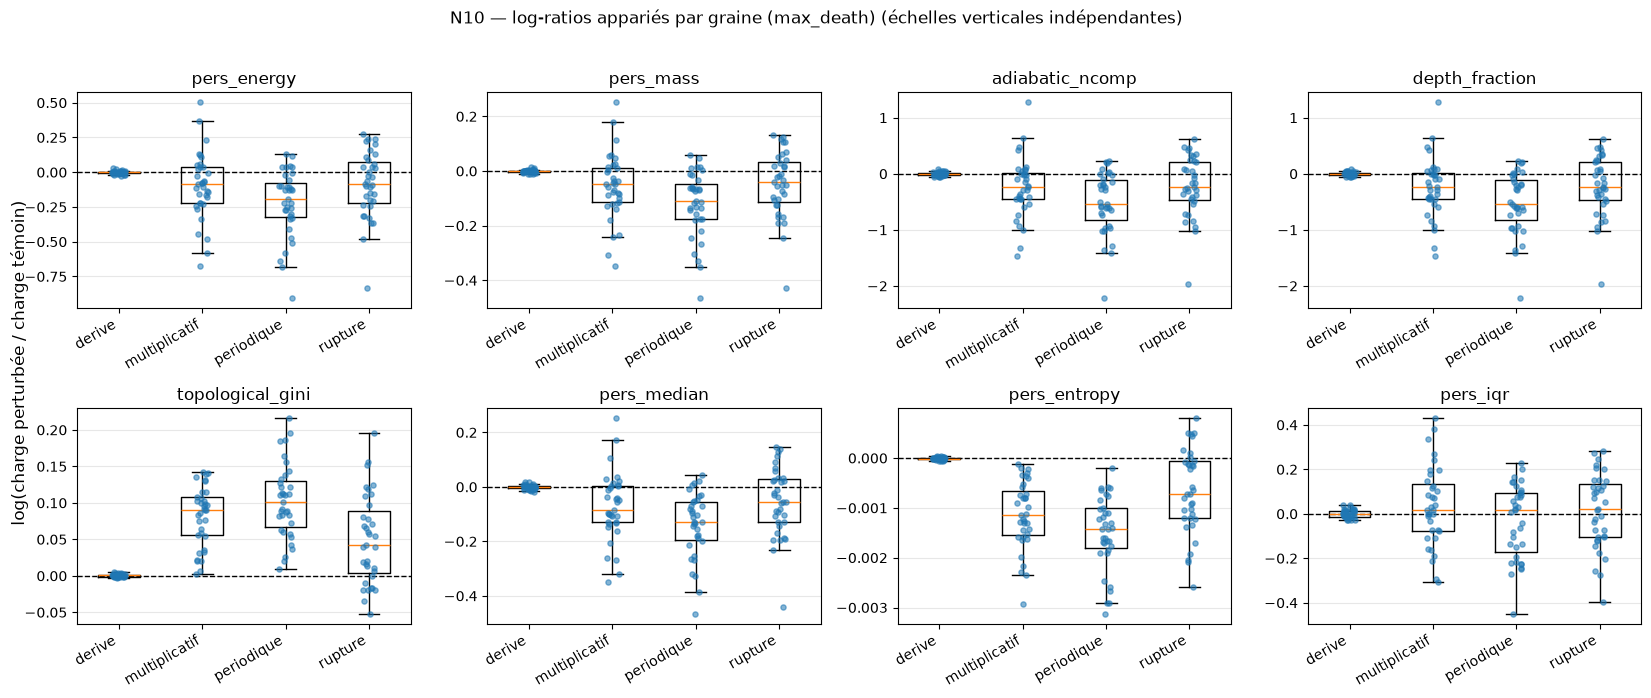

In [20]:
# -----------------------------------------------------------------------------
# N10. FAMILLE E — perturbations non conservatives
# -----------------------------------------------------------------------------
def run_N10():
    variantes = sorted({r["variante"] for r in INDEX if r["famille"] == "E"})
    if not variantes:
        raise RuntimeError("Famille E absente -> relancer la cellule E de 04b")

    s0, X0, d0 = diagrammes("D", 0.35, 0.40)  # témoin
    print(f"N10 : variantes = {variantes} ; témoin = D(0.35, 0.40) avec {len(s0)} graines")

    src = {
        "temoin": np.array(
            [PersistenceCurrent.integrated_source(courant(X)) for X in X0],
            dtype=float,
        )
    }
    Qv = {}
    log_ratios = {}

    i0 = {s: i for i, s in enumerate(s0)}

    for v in variantes:
        ss, Xs, dg = diagrammes("E", 0.35, 0.40, m=3, variante=v)
        iv = {s: i for i, s in enumerate(ss)}
        communs = sorted(set(iv) & set(i0))

        src[v] = np.array(
            [
                PersistenceCurrent.integrated_source(courant(Xs[iv[s]]))
                for s in communs
            ],
            dtype=float,
        )

        for mode in NORM_MODES:
            for cname, cfn in CHARGES.items():
                q = np.array(
                    [
                        charge_array([dg[iv[s]]], [Xs[iv[s]]], cfn, mode)[0]
                        for s in communs
                    ],
                    dtype=float,
                )
                q0 = np.array(
                    [
                        charge_array([d0[i0[s]]], [X0[i0[s]]], cfn, mode)[0]
                        for s in communs
                    ],
                    dtype=float,
                )

                # Wilcoxon apparié sur toutes les paires finies.
                finite_pair = np.isfinite(q) & np.isfinite(q0)
                q_pair, q0_pair = q[finite_pair], q0[finite_pair]
                if q_pair.size == 0:
                    p_w = float("nan")
                elif np.array_equal(q_pair, q0_pair):
                    p_w = 1.0
                else:
                    try:
                        p_w = float(stats.wilcoxon(q_pair, q0_pair).pvalue)
                    except ValueError as e:
                        print(f"Wilcoxon indisponible pour {v}/{mode}/{cname} : {e}")
                        p_w = float("nan")

                med, sd, cv = stats_inter(q)
                med0 = stats_inter(q0)[0]
                Qv[(v, mode, cname)] = (med, med0, p_w)

                # Le log-ratio exige des charges strictement positives.
                positive_pair = finite_pair & (q > 0) & (q0 > 0)
                lr = np.log(q[positive_pair] / q0[positive_pair])
                log_ratios[(v, mode, cname)] = lr

                add_row(
                    test="N10",
                    famille="E",
                    variante=v,
                    param="perturbation",
                    charge=cname,
                    norm=mode,
                    g=0.35,
                    T=0.40,
                    m=3,
                    seed="ALL",
                    n_samples=len(communs),
                    valeur_mediane=med,
                    std_inter_graines=sd,
                    cv=cv,
                    note=(
                        f"Wilcoxon apparié vs témoin D : p={p_w:.3g}; "
                        f"médiane log-ratio={stats_inter(lr)[0]:.4g} "
                        f"(n={lr.size}, paires strictement positives)"
                    ),
                )

                n_exclues = int(finite_pair.sum() - positive_pair.sum())
                if n_exclues:
                    print(
                        f"N10 : {v}/{mode}/{cname} — "
                        f"{n_exclues} paire(s) finie(s) exclue(s) du log-ratio "
                        "car une charge est nulle ou négative."
                    )

        add_row(
            test="N10",
            famille="E",
            variante=v,
            param="perturbation",
            charge="source_integree",
            g=0.35,
            T=0.40,
            m=3,
            seed="ALL",
            n_samples=len(communs),
            valeur_mediane=stats_inter(src[v])[0],
            std_inter_graines=stats_inter(src[v])[1],
        )

    print("\n--- N10 | source intégrée (médiane ± écart-type inter-graines) ---")
    for nom, valeurs in src.items():
        med, sd, _ = stats_inter(valeurs)
        print(f"{nom:14s} {med:10.4f} ± {sd:.4f}")

    try:
        kw = stats.kruskal(*[src[v] for v in variantes])
        print(
            f"Kruskal-Wallis entre variantes (source intégrée) : "
            f"H={kw.statistic:.3f}, p={kw.pvalue:.3g}"
        )
        add_row(
            test="N10",
            famille="E",
            param="kruskal",
            charge="source_integree",
            valeur_mediane=float(kw.pvalue),
            note="p-value Kruskal-Wallis entre variantes",
        )
    except Exception as e:
        print("Kruskal-Wallis impossible :", e)

    mode_plot = "max_death"
    print(f"\n--- N10 | log-ratios appariés par graine ({mode_plot}) ---")
    print("Un log-ratio positif indique une hausse par rapport au témoin.")
    print(f"{'variante':14s} " + " ".join(f"{c:>26s}" for c in CHARGES))
    for v in variantes:
        cellules = []
        for cname in CHARGES:
            lr = log_ratios[(v, mode_plot, cname)]
            med_lr = stats_inter(lr)[0]
            p_w = Qv[(v, mode_plot, cname)][2]
            cellules.append(f"{med_lr:8.3f} (p={p_w:.2g}, n={lr.size})")
        print(f"{v:14s} " + " ".join(cellules))

    # Paramètres d'affichage
    N10_PLOT_MODE = "max_death"  # doit appartenir à NORM_MODES
    N10_PLOT_NCOLS = 4
    N10_PANEL_SIZE = (4.2, 3.4)  # largeur, hauteur par panneau
    
    charges = list(CHARGES)
    ncols = min(N10_PLOT_NCOLS, len(charges))
    nrows = int(np.ceil(len(charges) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(N10_PANEL_SIZE[0] * ncols, N10_PANEL_SIZE[1] * nrows),
        sharey=False, squeeze=False,
    )
    axes = axes.ravel()
    rng = np.random.default_rng(0)  # jitter reproductible
    
    for ax, cname in zip(axes, charges):
        positions, valeurs, medians = [], [], []
    
        for i, v in enumerate(variantes, start=1):
            lr = np.asarray(log_ratios[(v, N10_PLOT_MODE, cname)], dtype=float)
            lr = lr[np.isfinite(lr)]
            if lr.size:
                positions.append(i)
                valeurs.append(lr)
                medians.append(float(np.median(lr)))
                ax.scatter(
                    i + rng.uniform(-0.08, 0.08, lr.size), lr,
                    s=14, alpha=0.55, color="C0", zorder=3,
                )
    
        ax.axhline(0, color="black", linestyle="--", linewidth=1)
        if valeurs:
            ax.boxplot(valeurs, positions=positions, widths=0.5, showfliers=False)
    
        ax.set_title(
            f"{cname}\nAucune paire valide" if not valeurs else cname
        )
        ax.set_xticks(range(1, len(variantes) + 1))
        ax.set_xticklabels(variantes, rotation=30, ha="right")
        ax.grid(True, alpha=0.3, axis="y")
    
    for ax in axes[len(charges):]:
        ax.set_visible(False)
    
    fig.supylabel("log(charge perturbée / charge témoin)")
    fig.suptitle(
        f"N10 — log-ratios appariés par graine ({N10_PLOT_MODE}) "
        "(échelles verticales indépendantes)",
        y=1.02,
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(FIG_DIR, "N10_logratio_charges.png"),
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    return {"src": src, "Qv": Qv, "log_ratios": log_ratios}


n10 = safe_run("N10", run_N10) if RUN["N10"] else None

## Synthèse — Tableau de bord Noether-SurPhiN
Les régimes détectés (conservatif / adiabatique / turbulent) sont des **indicateurs de (non-)conservation** des charges topologiques sous l'action des paramètres externes, à lire avec les écarts-types inter-graines, les normalisations et les limites listées en tête de notebook : le mot « preuve » de la v1 était trop fort.

In [21]:
# -----------------------------------------------------------------------------
# EXPORT CSV UNIQUE + TABLEAU DE BORD + JOURNAL D'ERREURS
# -----------------------------------------------------------------------------
csv_path = os.path.join(BASE_DIR, "noether_surphin_synthese_v2.csv")
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=CSV_FIELDS)
    w.writeheader()
    for row in ROWS:
        w.writerow(row)
print(f"Synthèse exportée : {csv_path}  ({len(ROWS)} lignes)")

print("\n=== TABLEAU DE BORD — régimes par test ===")
par_test = defaultdict(Counter)
for r in ROWS:
    if r["regime"] != "":
        par_test[r["test"]][r["regime"]] += 1
for t in sorted(par_test):
    print(f"{t:4s} : " + ", ".join(f"{k}={v}" for k, v in par_test[t].most_common()))

print("\n=== Fichiers manquants rencontrés ===")
print(f"{len(MANQUANTS)} nuage(s) manquant(s)" + (f", ex. : {sorted(MANQUANTS)[:3]}" if MANQUANTS else ""))
print("\n=== Avertissements du moteur H0 ===")
print(ENGINE_WARNINGS[:5] if ENGINE_WARNINGS else "aucun")
print("\n=== Journal d'erreurs ===")
if ERRORS:
    for lab, msg in ERRORS: print(f" - {lab}: {msg}")
else:
    print("aucune erreur 🎉")

Synthèse exportée : C:\Users\anton\source\Takens_H0_Simondon_in_PHY_noether-surphin-suite_forPUB\noether_surphin_synthese_v2.csv  (864 lignes)

=== TABLEAU DE BORD — régimes par test ===
N1   : turbulent=72, conservatif=72
N2   : turbulent=9, conservatif=6, adiabatique=1
N3   : turbulent=10, adiabatique=2
N6   : turbulent=6, conservatif=2
N9   : turbulent=6, conservatif=2

=== Fichiers manquants rencontrés ===
0 nuage(s) manquant(s)

=== Avertissements du moteur H0 ===
aucun

=== Journal d'erreurs ===
aucune erreur 🎉


## Prochaines étapes _en-cours
1. **Brancher le bottleneck exact** : remplacer `_approx_bottleneck` dans `WardIdentities` par la fonction exacte de `faisceau_couplage.py` (N5). FAIT (?)
2. **Multi-signaux** : étendre les grilles à plus de 2 signaux couplés.
3. **H1** : généraliser les charges à l'homologie persistante H1 (cycles).
4. **Topos** : relier le copeau comme obstruction de recollement (faisceau purifié) au terme-source sigma.
5. **Partitions** : si les ARI restent ≈ 1 à k fixe (effet aberrants de single-linkage), passer à une coupe à ε fixé (fraction de la mort max).
6. **Publication** : ce tableau de bord est une figure.

## Ajout des nouveaux tests 04c
tests N11 à N17

# Noether-SurPhiN — Tests N11 à N17 (protocole « redondance, information, dynamique »)

**À placer à la suite de N10**, dans le même noyau que `noether_surphin_notebook_v2` : ces cellules réutilisent ses objets (`INDEX`, `load_nuage`, `CHARGES`, `add_row`, `safe_run`, `ROWS`, `stats_inter`, `single_linkage_h0_diagram`, `BOTTLENECK_FN`…). Une cellule de prérequis le vérifie. Elles écrivent leur propre CSV (`noether_surphin_synthese_N11_N17.csv`), donc leur position par rapport à la cellule d'export de la v2 n'a pas d'importance.

## Pourquoi ces tests
`coupler()` (04b) est un **mélange linéaire instantané** : `s1 + g·s2`, `s2 + g·s1`, sans mémoire. Sur les familles A et D, `pers_energy` suit la redondance entre canaux (Spearman ≈ 0,97 avec le rapport de participation de la PCA) et la saturation à g élevé est un plafond dû au bruit, ≈ 1/(1+T²). Il faut donc séparer **redondance linéaire**, **information au-delà du linéaire** et **dynamique** avant toute lecture physique (le « seau »).

## Nuages attendus par test (nommage souple : jetons `clé+valeur` séparés par `_`)
| Test | Famille | Fichier attendu | Rôle |
|---|---|---|---|
| N11 | A, D, **F** | `X_famF_g{g:.2f}_T{T:.2f}_m3_seed{s}.npy` | F = couplage **normalisé** (s1, s2 standardisés avant mélange), g = 0…1 par 0,1 × T ∈ {0,1 ; 0,2 ; 0,4 ; 0,8} |
| N12 | F + nuls **H** | `X_famH_{phiJ|phiI|shuf}_g{g:.2f}_T0.40_m3_seed{s}.npy` | surrogats à phases jointes / indépendantes, mélange temporel commun, à T = 0,40. Les nuls « même covariance », « iid » et « paires désappariées » sont générés **dans le notebook** à partir de F |
| N13 | **F** | idem N11 | forme de la réponse en g et en ρ mesuré, 4 niveaux de T |
| N14 | **I** (+ F comme référence) | `X_famI_tau{tau}_N{N:04d}_g{g:.2f}_T0.40_m{m}_seed{s}.npy` | un hyperparamètre à la fois : τ ∈ {3, 15, 30} (7 = référence), N ∈ {150, 600, 1200} (300 = référence), m = 5 ; g ∈ {0,1 ; 0,4 ; 0,7} |
| N15 | **J** | `X_famJ_{uni|bi}_eps{eps:.4f}_T0.10_m3_seed{s}.npy` (+ sidecar optionnel `R_famJ_….npy` = cohérence de phase vraie) | deux Rössler désaccordés, couplage diffusif ε ∈ [0 ; 0,3] (25 valeurs, grille resserrée sur 0–0,05), unidirectionnel / bidirectionnel |
| N16 | F | idem N11 | information mutuelle (KSG) au-delà du linéaire |
| N17 | **K** | `X_famK_tv{tv}_ds{ds}_T{T:.2f}_m3_seed{s}.npy` | « eau » = filtre passe-bas du pilote, τν ∈ {0, 5, 10, 20, 40, 80, 160, 320} (pas ×2), pilote à vitesse ds ∈ {1, 2}, T ∈ {0,1 ; 0,4} |

Un test dont la famille est absente est **ignoré avec un message** (il ne bloque pas les suivants).

## Règles communes (fixées avant les résultats)
Comparaisons **appariées par graine** quand les signaux de base sont communs ; IC bootstrap à 95 % sur les graines ; correction de Holm au sein d'un test. **Indicateurs primaires** : `topological_gini`, énergie normalisée E_p/M^p (`e2m2`), dimension TwoNN, PR. Les charges dégénérées de la v2 (`adiabatic_ncomp`, `depth_fraction`, `source_integree`) ne sont **pas** utilisées. Chaque hypothèse H1…H7 a une règle de décision écrite dans `PREREG` (cellule suivante) ; la dernière cellule imprime les verdicts.

In [22]:
# -----------------------------------------------------------------------------
# 0. PRÉREQUIS, CONFIGURATION, PRÉ-ENREGISTREMENT
# -----------------------------------------------------------------------------
import os, re, csv
from collections import Counter, defaultdict, OrderedDict
from pathlib import Path
from scipy.spatial import cKDTree
from scipy.special import digamma
from scipy.optimize import curve_fit
from scipy.signal import hilbert

_REQUIS = ["np", "plt", "stats", "pdist", "squareform", "INDEX", "CHARGES", "add_row", "safe_run", "ERRORS", "ROWS",
           "CSV_FIELDS", "normaliser_dgm", "mst_merges", "single_linkage_h0_diagram", "lifetimes", "pers_energy_norm",
           "_pairs", "SEEDS", "FIG_DIR", "BASE_DIR", "NUAGE_DIR", "PersDiagram", "_npy"]
_manq = [n for n in _REQUIS if n not in globals()]
if _manq:
    raise RuntimeError(f"Prérequis manquants (cellules de la v2 non exécutées ?) : {_manq}")
assert "topological_gini" in CHARGES, "CHARGES doit contenir 'topological_gini'"

N_BOOT = 1000          # rééchantillonnages bootstrap (IC)
N_BOOT_FIT = 200       # rééchantillonnages pour les ajustements de modèles (N13)
T_NUL = 0.40           # niveau de bruit des nuls structurels (famille H)
ALPHA = 0.05
PRIMAIRES = ("gini", "e2m2")        # indicateurs primaires pour les verdicts (twonn et pr : descriptifs)

PREREG = OrderedDict([
    ("H1", "L'indice lit une information de couplage au-delà de la covariance : d(g) = (vrai − nul covariance)(g) − (vrai − nul covariance)(g=0), "
           "apparié par graine ; SOUTENUE si ≥ 3 valeurs de g>0 ont p de Holm < 0,05 avec un signe constant, sur un indicateur primaire. (N12, appui N16)"),
    ("H2", "Le gini mesure « variété contre bruit » : l'écart (vrai − nul covariance), sans hypothèse de signe, a un IC excluant 0 à T=0,1 et une amplitude au moins deux fois plus faible à T=0,8. (N12)"),
    ("H3", "Il existe un minimum (« obliquité ») : modèle non monotone préféré (ΔAIC > 10), convexe, argmin intérieur (IC dans le domaine, marges 5 %), "
           "reproduit sur ≥ 2 des 4 niveaux de T, indicateur primaire, mêmes coordonnées (g ou ρ). (N13)"),
    ("H4", "L'indice suit une vraie transition de couplage : |ε_c(indice) − ε_c(R)| ≤ 1 intervalle de grille dans ≥ 70 % des rééchantillonnages, "
           "dans les deux directions (soutenue) ou dans une seule (partielle). (N15)"),
    ("H5", "Couche limite visqueuse : extremum intérieur de l'indice en τν, qui se déplace de +1 pas (×2) quand le pilote ralentit ×2, "
           "dans ≥ 60 % des rééchantillonnages. (N17)"),
    ("H6", "À g=0, aucune signature de couplage : vrai − nul « paires désappariées » a un IC contenant 0 pour tous les indicateurs primaires ET au moins un indicateur primaire détecte la dépendance inter-canaux ailleurs (≥ 3 g>0, Holm) ; sinon verdict VIDE. (N12)"),
    ("H7", "Robustesse : le signe de l'effet de g (g=0,7 − g=0,1) est conservé et les IC se recouvrent, dans ≥ 80 % des (variante × indicateur primaire). (N14)"),
])
VERDICT = OrderedDict()
def verdict(h, statut, detail):
    VERDICT[h] = (statut, detail)
    print(f"   ⇒ {h} : {statut} — {detail}")

print("=== PRÉ-ENREGISTREMENT ===")
for h, r in PREREG.items():
    print(f"{h}: {r}\n")

=== PRÉ-ENREGISTREMENT ===
H1: L'indice lit une information de couplage au-delà de la covariance : d(g) = (vrai − nul covariance)(g) − (vrai − nul covariance)(g=0), apparié par graine ; SOUTENUE si ≥ 3 valeurs de g>0 ont p de Holm < 0,05 avec un signe constant, sur un indicateur primaire. (N12, appui N16)

H2: Le gini mesure « variété contre bruit » : l'écart (vrai − nul covariance), sans hypothèse de signe, a un IC excluant 0 à T=0,1 et une amplitude au moins deux fois plus faible à T=0,8. (N12)

H3: Il existe un minimum (« obliquité ») : modèle non monotone préféré (ΔAIC > 10), convexe, argmin intérieur (IC dans le domaine, marges 5 %), reproduit sur ≥ 2 des 4 niveaux de T, indicateur primaire, mêmes coordonnées (g ou ρ). (N13)

H4: L'indice suit une vraie transition de couplage : |ε_c(indice) − ε_c(R)| ≤ 1 intervalle de grille dans ≥ 70 % des rééchantillonnages, dans les deux directions (soutenue) ou dans une seule (partielle). (N15)

H5: Couche limite visqueuse : extremum intérieur

In [23]:
# -----------------------------------------------------------------------------
# 1. INDEX ÉTENDU (familles A–K), indicateurs, nuls et outils statistiques
# -----------------------------------------------------------------------------
INDEX2 = INDEX

def _key_number(value):
    if value is None or (isinstance(value, (float, np.floating)) and np.isnan(value)):
        return -1.0
    return round(float(value), 5)

def _key2(row):
    return (
        row["famille"], row["variante"], _key_number(row["g"]), _key_number(row["T"]),
        int(row["m"]), int(row["tau"]), int(row["N"]), _key_number(row["eps"]),
        _key_number(row["tv"]), int(row["ds"]), int(row["seed"]),
    )

KEY2 = {}
for row in INDEX2:
    key = _key2(row)
    if key in KEY2:
        raise ValueError(f"Clé de nuage dupliquée : {key} ({KEY2[key]} et {row['path']})")
    KEY2[key] = row["path"]
print(f"INDEX2 : {len(INDEX2)} nuages ; par famille :", dict(sorted(Counter(row["famille"] for row in INDEX2).items())))

def meta2(fam, seed, var="", g=0.0, T=0.0, m=3, tau=7, N=300, eps=float("nan"), tv=float("nan"), ds=1):
    return dict(famille=fam, variante=var, g=g, T=T, m=m, tau=tau, N=N, eps=eps, tv=tv, ds=ds, seed=seed)

def get_cloud(**kw):
    p = KEY2.get(_key2(meta2(**kw)))
    return None if p is None else _npy(str(p))

def grille(fam, champ, var=None, **fixes):
    out = set()
    for d in INDEX2:
        if d["famille"] != fam or (var is not None and d["variante"] != var): continue
        value = d[champ]
        if value is None or (isinstance(value, (float, np.floating)) and not np.isfinite(value)): continue
        if all(np.isclose(d[k], v) for k, v in fixes.items()): out.add(value)
    return sorted(out)

def seeds_communes(fam, **kw):
    return [s for s in SEEDS if get_cloud(fam=fam, seed=s, **kw) is not None]

# ---- indicateurs ----
def participation_ratio(X):
    ev = np.clip(np.linalg.eigvalsh(np.cov(X.T)), 0, None)
    return float(ev.sum() ** 2 / (ev ** 2).sum())

def twonn_dim(X, discard=0.1):
    """TwoNN (Facco et al. 2017), régression passant par l'origine sur 90 % des points (approximation)."""
    D = squareform(pdist(X)); np.fill_diagonal(D, np.inf); D.sort(axis=1)
    r1, r2 = D[:, 0], D[:, 1]; ok = r1 > 0
    mu = np.sort(r2[ok] / r1[ok]); n = len(mu); k = int(np.floor(n * (1 - discard)))
    x = np.log(mu[:k]); y = -np.log(1 - (np.arange(1, k + 1) / n))
    return float((x * y).sum() / (x * x).sum())

def rho_canaux(X, m):
    return abs(float(np.corrcoef(X[:, 0], X[:, m])[0, 1])) if X.shape[1] >= 2 * m else float("nan")

def ind_array(X, m=3):
    """Indicateurs d'un nuage (tableau). gini = charge du module ; e2m2 = E_p/M^p ; energie = pers_energy du module."""
    dgm = single_linkage_h0_diagram(np.asarray(X))
    return dict(gini=float(CHARGES["topological_gini"](dgm)), e2m2=float(pers_energy_norm(dgm)),
                energie=float(CHARGES["pers_energy"](dgm)), pr=participation_ratio(X),
                twonn=twonn_dim(X), rho=rho_canaux(X, m))

_IND_CACHE = {}
def ind_meta(**kw):
    k = _key2(meta2(**kw))
    if k not in _IND_CACHE:
        X = get_cloud(**kw)
        _IND_CACHE[k] = None if X is None else ind_array(X, kw.get("m", 3))
    return _IND_CACHE[k]

# ---- nuls fabriqués dans le notebook à partir d'un nuage F ----
def nul_cov(X, seed):
    r = np.random.default_rng(10_000 + seed)
    return r.multivariate_normal(X.mean(0), np.cov(X.T), size=len(X))

def nul_iid(X, seed):
    r = np.random.default_rng(20_000 + seed); Z = r.normal(size=X.shape)
    return (Z - Z.mean(0)) / Z.std(0)

def nul_paires(X, X_autre, m):
    """Canal 1 de X + canal 2 d'une autre graine : détruit toute dépendance inter-canaux, garde les marginales."""
    return np.hstack([X[:, :m], X_autre[:, m:2 * m]])

# ---- statistiques ----
def boot_ci(v, stat=np.median, n=None, seed=0):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    if len(v) < 3: return (float("nan"), float("nan"))
    r = np.random.default_rng(seed); n = n or N_BOOT
    b = [stat(v[r.integers(0, len(v), len(v))]) for _ in range(n)]
    return (float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5)))

def wilcoxon_p(d):
    d = np.asarray(d, float); d = d[np.isfinite(d)]
    if len(d) < 6 or np.allclose(d, 0): return float("nan")
    try: return float(stats.wilcoxon(d).pvalue)
    except Exception: return float("nan")

def holm(pvals):
    p = np.asarray(pvals, float); out = np.full(len(p), np.nan)
    ok = np.where(np.isfinite(p))[0]
    if len(ok) == 0: return out
    order = ok[np.argsort(p[ok])]; m = len(order); run = 0.0
    for rank, idx in enumerate(order):
        run = max(run, (m - rank) * p[idx]); out[idx] = min(1.0, run)
    return out

def fmt_ci(ci): return f"[{ci[0]:.4g}; {ci[1]:.4g}]"

def ols(Xd, y):
    A = np.column_stack([np.ones(len(y)), Xd]); beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    rss = float(((y - A @ beta) ** 2).sum()); return beta, rss, A.shape[1]

def r2_adj(y, rss, k):
    n = len(y); tss = float(((y - y.mean()) ** 2).sum()); r2 = 1 - rss / tss
    return r2, 1 - (1 - r2) * (n - 1) / (n - k)

def nested_F(y, X0, X1):
    _, r0, k0 = ols(X0, y); _, r1, k1 = ols(X1, y); n = len(y)
    F = ((r0 - r1) / (k1 - k0)) / (r1 / (n - k1)); p = float(1 - stats.f.cdf(F, k1 - k0, n - k1))
    return r2_adj(y, r0, k0), r2_adj(y, r1, k1), float(F), p

def ksg_mi(x, y, k=4):
    """Information mutuelle de Kraskov-Stögbauer-Grassberger (algorithme 1), en nats."""
    x = np.asarray(x, float).reshape(-1, 1); y = np.asarray(y, float).reshape(-1, 1); n = len(x)
    xy = np.hstack([x, y]); d, _ = cKDTree(xy).query(xy, k=k + 1, p=np.inf); eps = d[:, -1] - 1e-12
    nx = cKDTree(x).query_ball_point(x, eps, p=np.inf, return_length=True) - 1
    ny = cKDTree(y).query_ball_point(y, eps, p=np.inf, return_length=True) - 1
    return float(digamma(k) + digamma(n) - np.mean(digamma(nx + 1) + digamma(ny + 1)))

def dep_nonlineaire(X, m):
    """MI(KSG) − MI gaussienne(ρ) entre les deux canaux : dépendance au-delà du linéaire."""
    x, y = X[:, 0], X[:, m]; r = np.corrcoef(x, y)[0, 1]
    return ksg_mi(x, y) + 0.5 * np.log(max(1e-12, 1 - r * r))

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

print("Outils N11–N17 prêts.")

INDEX2 : 7455 nuages ; par famille : {'A': 280, 'B': 105, 'C': 245, 'D': 385, 'E': 140, 'F': 1540, 'H': 1155, 'I': 735, 'J': 1750, 'K': 1120}
Outils N11–N17 prêts.


## N11 — Réduction à la redondance
**Nuages attendus** : familles **A, D** (couplage brut, `g=0.35` / `T=0.40`) et **F** (couplage normalisé, grille g × T), m = 3, τ = 7, N = 300.
**Question** : g et T ajoutent-ils quelque chose à ce que dit déjà la redondance entre canaux (PR, ρ) ? Pour chaque indicateur : R² ajusté du modèle « PR seul » (degré 2) contre « PR + g + T + g·T », test F emboîté (par groupe de construction : A+D brut, F normalisé), corrélations de rang avec PR et ρ, et courbe d'effondrement en ρ. Les nuages d'une même condition partagent leurs signaux de base : les p-values sont **indicatives** (pseudo-réplication).

N11 : 2205 nuages

--- A+D (brut) (665 nuages) ---
indicateur   Sp(PR)  Sp(rho)  R²adj PR  R²adj +g,T        F         p
gini         -0.280    0.330     0.095       0.173    21.80   1.8e-13
e2m2         -0.300    0.343     0.123       0.173    14.19   5.7e-09
twonn         0.271   -0.236     0.191       0.251    18.70   1.2e-11
energie       0.971   -0.933     0.882       0.986  1620.27         0

--- F (normalisé) (1540 nuages) ---
indicateur   Sp(PR)  Sp(rho)  R²adj PR  R²adj +g,T        F         p
gini         -0.249    0.224     0.069       0.168    62.32         0
e2m2         -0.263    0.257     0.098       0.176    49.60         0
twonn         0.426   -0.190     0.154       0.497   350.70         0
energie       0.879   -0.644     0.754       0.987  9280.25         0


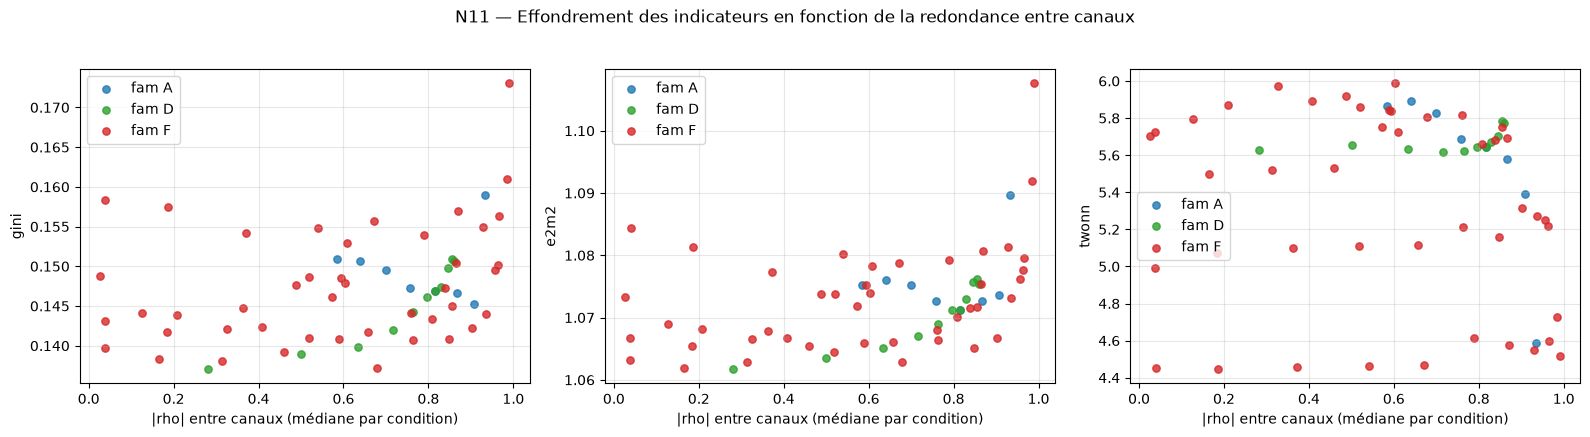

In [24]:
# -----------------------------------------------------------------------------
# N11. RÉDUCTION À LA REDONDANCE  (nuages : A, D, F)
# -----------------------------------------------------------------------------
IND_NAMES = ("gini", "e2m2", "twonn", "energie")

def collecter_clouds(fams):
    rows = []
    for d in INDEX2:
        if d["famille"] in fams and d["variante"] == "" and d["m"] == 3 and d["tau"] == 7 and d["N"] == 300:
            r = ind_meta(fam=d["famille"], seed=d["seed"], g=d["g"], T=d["T"])
            if r is not None: rows.append(dict(r, fam=d["famille"], g=d["g"], T=d["T"], seed=d["seed"]))
    return rows

def run_N11():
    data = collecter_clouds(("A", "D", "F"))
    if not any(r["fam"] == "F" for r in data): print("⚠️ N11 : famille F absente -> seuls A et D analysés")
    print(f"N11 : {len(data)} nuages")
    groupes = {"A+D (brut)": [r for r in data if r["fam"] in ("A", "D")], "F (normalisé)": [r for r in data if r["fam"] == "F"]}
    out = {}
    for gname, rows in groupes.items():
        if len(rows) < 30: continue
        pr = np.array([r["pr"] for r in rows]); g = np.array([r["g"] for r in rows]); T = np.array([r["T"] for r in rows])
        rho = np.array([r["rho"] for r in rows])
        X0 = np.column_stack([pr, pr ** 2]); X1 = np.column_stack([pr, pr ** 2, g, T, g * T])
        print(f"\n--- {gname} ({len(rows)} nuages) ---")
        print(f"{'indicateur':10s} {'Sp(PR)':>8s} {'Sp(rho)':>8s} {'R²adj PR':>9s} {'R²adj +g,T':>11s} {'F':>8s} {'p':>9s}")
        for ind in IND_NAMES:
            y = np.array([r[ind] for r in rows]); ok = np.isfinite(y) & np.isfinite(pr) & np.isfinite(rho)
            if ok.sum() < 30: continue
            sp_pr = stats.spearmanr(y[ok], pr[ok])[0]; sp_rho = stats.spearmanr(y[ok], rho[ok])[0]
            (r20, a0), (r21, a1), F, p = nested_F(y[ok], X0[ok], X1[ok])
            print(f"{ind:10s} {sp_pr:8.3f} {sp_rho:8.3f} {a0:9.3f} {a1:11.3f} {F:8.2f} {p:9.2g}")
            add_row(test="N11", famille=gname, param="PR", charge=ind, seed="ALL", valeur_mediane=sp_pr, n_samples=int(ok.sum()),
                    note=f"Spearman(PR)={sp_pr:.3f} ; Spearman(rho)={sp_rho:.3f} ; R2adj PR={a0:.3f} ; R2adj +g,T={a1:.3f} ; F={F:.2f} ; p={p:.2g}")
            out[(gname, ind)] = dict(sp_pr=sp_pr, sp_rho=sp_rho, r2_pr=a0, r2_full=a1, p=p)
    # ---- courbes d'effondrement en rho (médianes par condition)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    couleurs = {"A": "tab:blue", "D": "tab:green", "F": "tab:red"}
    for ax, ind in zip(axes, ("gini", "e2m2", "twonn")):
        for fam in ("A", "D", "F"):
            cond = defaultdict(list)
            for r in data:
                if r["fam"] == fam and np.isfinite(r[ind]) and np.isfinite(r["rho"]): cond[(r["g"], r["T"])].append((r["rho"], r[ind]))
            if not cond: continue
            xs = [np.median([a for a, _ in v]) for v in cond.values()]; ys = [np.median([b for _, b in v]) for v in cond.values()]
            ax.scatter(xs, ys, s=28, c=couleurs[fam], label=f"fam {fam}", alpha=0.8)
        ax.set_xlabel("|rho| entre canaux (médiane par condition)"); ax.set_ylabel(ind); ax.grid(True, alpha=0.3); ax.legend()
    plt.suptitle("N11 — Effondrement des indicateurs en fonction de la redondance entre canaux", y=1.03)
    plt.tight_layout(); savefig("N11_effondrement_rho.png"); plt.show()
    return out

n11 = safe_run("N11", run_N11)

## N12 — Nuls structurels, excès sur le bruit (H1, H2, H6)
**Nuages attendus** : famille **F** (vrais nuages, toutes (g, T)) ; famille **H** (`phiJ`, `phiI`, `shuf`) à T = 0,40. Les nuls **« covariance »** (gaussien de même covariance 6×6), **« iid »** et **« paires désappariées »** (canal 1 de la graine k, canal 2 de la graine k+1) sont fabriqués ici à partir de F.
**Lecture** : `phiJ` garde le spectre croisé (linéaire), détruit la non-linéarité ; `phiI` détruit aussi le couplage ; `shuf` (permutation commune) garde la loi jointe instantanée mais détruit la dynamique ; « paires » garde les marginales et détruit toute dépendance inter-canaux.
**H1** : double différence d(g) = (vrai − nul cov)(g) − (vrai − nul cov)(0), apparié par graine. **H2** (sans hypothèse de signe) : écart au nul cov net à T = 0,1 et d'amplitude ≥ 2× plus faible à T = 0,8. **H6** : à g = 0, vrai − nul « paires » ≈ 0, **à condition que l'indice soit sensible ailleurs** (≥ 3 valeurs de g>0 détectées) ; sinon le verdict est « VIDE (indice aveugle) ». `pr` et `twonn` servent de contrôles positifs du nul « paires ».

N12 : 11 g × 4 T × 35 graines

--- médiane de (vrai − nul) à T=0.4, indicateur gini ---
g          cov      iid   paires     phiJ     phiI     shuf
 0.0   -0.0237  -0.0154   0.0025  -0.0029  -0.0010   0.0088
 0.1   -0.0246  -0.0174   0.0000  -0.0101  -0.0070   0.0086
 0.2   -0.0247  -0.0197  -0.0015  -0.0064  -0.0028   0.0060
 0.3   -0.0218  -0.0137  -0.0023  -0.0022  -0.0005   0.0057
 0.4   -0.0185  -0.0146   0.0005  -0.0021  -0.0052   0.0088
 0.5   -0.0215  -0.0159  -0.0042  -0.0072  -0.0070   0.0037
 0.6   -0.0137  -0.0082  -0.0014  -0.0052  -0.0070   0.0018
 0.7   -0.0175  -0.0118  -0.0011  -0.0047  -0.0016   0.0005
 0.8   -0.0113  -0.0093   0.0013  -0.0049  -0.0025  -0.0009
 0.9   -0.0127  -0.0057   0.0008  -0.0018   0.0004  -0.0024
 1.0   -0.0107  -0.0063   0.0043   0.0045   0.0026  -0.0025

Sensibilité à la dépendance inter-canaux (vrai vs « paires », T=0.4) : nombre de g>0 détectés (Holm) = {'gini': 0, 'e2m2': 1, 'pr': 10, 'twonn': 1}
   (pr et twonn = contrôles positifs ; s'il

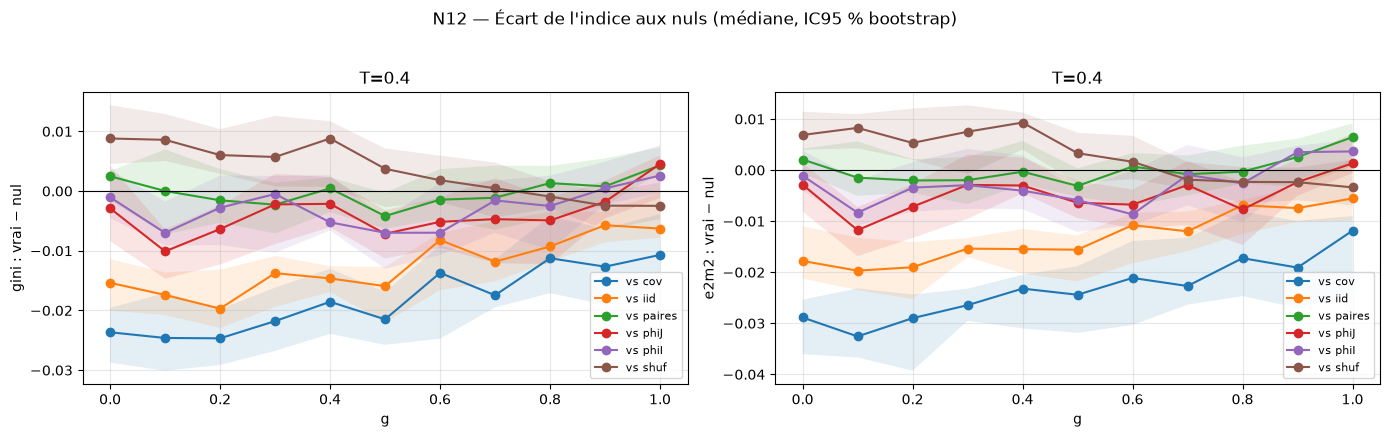

In [25]:
# -----------------------------------------------------------------------------
# N12. NULS ET EXCÈS  (nuages : F ; H pour phiJ/phiI/shuf)
# -----------------------------------------------------------------------------
_NUL_CACHE = {}
def ind_nul(nul, g, T, k, seeds):
    """Indicateurs (dict) du nul fabriqué à partir du nuage F de la graine seeds[k] ; None si indisponible."""
    key = (nul, round(g, 3), round(T, 3), seeds[k])
    if key not in _NUL_CACHE:
        X = get_cloud(fam="F", seed=seeds[k], g=g, T=T); res = None
        if X is not None:
            if nul == "cov": res = ind_array(nul_cov(X, seeds[k]), 3)
            elif nul == "iid": res = ind_array(nul_iid(X, seeds[k]), 3)
            elif nul == "paires":
                Xo = get_cloud(fam="F", seed=seeds[(k + 1) % len(seeds)], g=g, T=T)
                res = None if Xo is None else ind_array(nul_paires(X, Xo, 3), 3)
        _NUL_CACHE[key] = res
    return _NUL_CACHE[key]

def paire_nul_vs_vrai(g, T, indic, nul, seeds):
    """Vecteurs appariés (vrai, nul) sur les graines pour un nul fabriqué à partir de F."""
    v, n = [], []
    for k, s in enumerate(seeds):
        r = ind_meta(fam="F", seed=s, g=g, T=T); rn = ind_nul(nul, g, T, k, seeds)
        if r is None or rn is None: continue
        v.append(r[indic]); n.append(rn[indic])
    return np.array(v), np.array(n)

def run_N12():
    Gs = grille("F", "g"); Ts = grille("F", "T")
    if len(Gs) < 3: raise RuntimeError("Famille F absente -> générer F (04c)")
    seeds = seeds_communes("F", g=Gs[0], T=Ts[0])
    print(f"N12 : {len(Gs)} g × {len(Ts)} T × {len(seeds)} graines")
    CTRL = ("pr", "twonn")      # contrôles positifs : doivent détecter la perte de dépendance inter-canaux (nul « paires »)
    res = {}
    # ---- (a) nuls fabriqués : cov, iid, paires — toutes (g, T)
    for nul in ("cov", "iid", "paires"):
        for indic in PRIMAIRES + (CTRL if nul == "paires" else ()):
            for T in Ts:
                for g in Gs:
                    v, n = paire_nul_vs_vrai(g, T, indic, nul, seeds)
                    d = v - n; res[(indic, nul, g, T)] = d
                    add_row(test="N12", famille="F", variante=nul, param="g", param_value=g, charge=indic, g=g, T=T, m=3, seed="ALL",
                            n_samples=len(d), valeur_mediane=float(np.nanmedian(d)), std_inter_graines=float(np.nanstd(d, ddof=1)),
                            note=f"vrai−nul {nul} ; IC95={fmt_ci(boot_ci(d))} ; p_wilcoxon={wilcoxon_p(d):.3g}")
    # ---- (b) nuls structurels H à T_NUL (phiJ, phiI, shuf)
    for indic in PRIMAIRES:
        for var in ("phiJ", "phiI", "shuf"):
            for g in Gs:
                v, n = [], []
                for s in seeds:
                    r1 = ind_meta(fam="F", seed=s, g=g, T=T_NUL); r2 = ind_meta(fam="H", var=var, seed=s, g=g, T=T_NUL)
                    if r1 is None or r2 is None: continue
                    v.append(r1[indic]); n.append(r2[indic])
                if len(v) < 6: continue
                d = np.array(v) - np.array(n); res[(indic, var, g, T_NUL)] = d
                add_row(test="N12", famille="F/H", variante=var, param="g", param_value=g, charge=indic, g=g, T=T_NUL, m=3, seed="ALL",
                        n_samples=len(d), valeur_mediane=float(np.nanmedian(d)),
                        note=f"vrai−nul {var} ; IC95={fmt_ci(boot_ci(d))} ; p_wilcoxon={wilcoxon_p(d):.3g}")
    # ---- (c) tableau synthétique à T_NUL
    T0 = min(Ts, key=lambda t: abs(t - T_NUL))
    print(f"\n--- médiane de (vrai − nul) à T={T0}, indicateur gini ---")
    nuls = [n for n in ("cov", "iid", "paires", "phiJ", "phiI", "shuf") if any((("gini", n, g, T0) in res) for g in Gs)]
    print("g     " + " ".join(f"{n:>8s}" for n in nuls))
    for g in Gs:
        print(f"{g:4.1f}  " + " ".join(f"{np.nanmedian(res[('gini', n, g, T0)]):8.4f}" if ('gini', n, g, T0) in res else f"{'—':>8s}" for n in nuls))
    # ---- (d) sensibilité au nul « paires » : combien de g>0 le détectent (Holm) ?
    sens = {}
    for indic in PRIMAIRES + CTRL:
        ps = [wilcoxon_p(res[(indic, "paires", g, T0)]) for g in Gs if g > 0 and (indic, "paires", g, T0) in res]
        ph = holm(ps); sens[indic] = int(np.sum(ph < ALPHA)); 
    print("\nSensibilité à la dépendance inter-canaux (vrai vs « paires », T=%s) : nombre de g>0 détectés (Holm) = %s" % (T0, sens))
    print("   (pr et twonn = contrôles positifs ; s'ils ne détectent rien, le nul « paires » est suspect)")
    add_row(test="N12", famille="F", param="sensibilite_paires", valeur_mediane=float(max(sens[i] for i in PRIMAIRES)), note=str(sens))
    # ---- (e) verdicts H1, H2, H6
    h1_ok = []
    for indic in PRIMAIRES:
        ps, signes = [], []
        for g in Gs:
            if g == 0 or (indic, "cov", g, T0) not in res or (indic, "cov", 0.0, T0) not in res: continue
            dd = res[(indic, "cov", g, T0)] - res[(indic, "cov", 0.0, T0)]
            ps.append(wilcoxon_p(dd)); signes.append(np.sign(np.nanmedian(dd)))
        ph = holm(ps); sig = [i for i, p in enumerate(ph) if np.isfinite(p) and p < ALPHA]
        const = len(sig) >= 3 and len({signes[i] for i in sig}) == 1
        h1_ok.append((indic, len(sig), const))
    ok1 = any(c for _, _, c in h1_ok)
    verdict("H1", "SOUTENUE" if ok1 else "NON DÉMONTRÉE", "; ".join(f"{i}: {n} g significatifs (Holm), signe constant={c}" for i, n, c in h1_ok))
    # H2 (sans hypothèse de signe) : écart au nul covariance net à T bas et d'amplitude au moins deux fois plus faible à T haut
    Tlo, Thi = min(Ts), max(Ts)
    def diff_pool(indic, T): return np.concatenate([res[(indic, "cov", g, T)] for g in Gs if g > 0 and (indic, "cov", g, T) in res])
    dlo, dhi = diff_pool("gini", Tlo), diff_pool("gini", Thi)
    ci_lo, ci_hi = boot_ci(dlo), boot_ci(dhi); mlo, mhi = float(np.nanmedian(dlo)), float(np.nanmedian(dhi))
    h2 = (not (ci_lo[0] <= 0 <= ci_lo[1])) and abs(mlo) >= 2 * abs(mhi)
    verdict("H2", "SOUTENUE" if h2 else "NON SOUTENUE", f"écart gini vrai−cov : T={Tlo} médiane={mlo:.4f} IC={fmt_ci(ci_lo)} ; T={Thi} médiane={mhi:.4f} IC={fmt_ci(ci_hi)} ; rapport |T bas|/|T haut|={abs(mlo)/max(abs(mhi),1e-12):.1f}")
    # H6 : à g=0 vrai ≈ paires, ET l'indice doit être sensible à la dépendance ailleurs, sinon le verdict est vide
    h6 = []
    for indic in PRIMAIRES:
        for T in Ts:
            if (indic, "paires", 0.0, T) in res:
                ci = boot_ci(res[(indic, "paires", 0.0, T)]); h6.append((indic, T, ci[0] <= 0 <= ci[1]))
    zero_ok = bool(h6) and all(c for *_, c in h6); sensible = [i for i in PRIMAIRES if sens.get(i, 0) >= 3]
    if not zero_ok: st6 = "NON SOUTENUE"
    elif not sensible: st6 = "VIDE (indice aveugle au couplage)"
    else: st6 = "SOUTENUE"
    verdict("H6", st6, f"IC contenant 0 pour {sum(c for *_, c in h6)}/{len(h6)} cas à g=0 ; indicateurs sensibles (≥3 g>0 détectés) : {sensible or 'aucun'} ; contrôles positifs {({i: sens[i] for i in CTRL})}")
    # ---- figure : excès vs g par nul à T0
    fig, axes = plt.subplots(1, len(PRIMAIRES), figsize=(7 * len(PRIMAIRES), 4.2), squeeze=False)
    for ax, indic in zip(axes[0], PRIMAIRES):
        for n in nuls:
            xs = [g for g in Gs if (indic, n, g, T0) in res]
            if not xs: continue
            med = [np.nanmedian(res[(indic, n, g, T0)]) for g in xs]
            lo, hi = zip(*[boot_ci(res[(indic, n, g, T0)], n=300) for g in xs])
            ax.plot(xs, med, marker="o", label=f"vs {n}"); ax.fill_between(xs, lo, hi, alpha=0.12)
        ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("g"); ax.set_ylabel(f"{indic} : vrai − nul"); ax.set_title(f"T={T0}"); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    plt.suptitle("N12 — Écart de l'indice aux nuls (médiane, IC95 % bootstrap)", y=1.03); plt.tight_layout(); savefig("N12_exces_nuls.png"); plt.show()
    return res

n12 = safe_run("N12", run_N12)

## N13 — Forme de la réponse : monotone saturant ou non monotone ? (H3)
**Nuages attendus** : famille **F** (4 niveaux de T × 11 valeurs de g), m = 3, τ = 7, N = 300.
Pour chaque (indicateur primaire ou TwoNN) × niveau de T × coordonnée (g ou ρ mesuré par nuage) : modèle **M0** monotone saturant `y = a + b(1 − e^(−x/c))` contre **M1** quadratique `y = a + bx + cx²` (le seul à admettre un minimum). AIC sur les nuages individuels, bootstrap **sur les graines** (même graine = mêmes signaux pour tous les g). Un minimum n'est retenu que si : ΔAIC (M0 − M1) médian > 10, M1 convexe, argmin dans le domaine (marge 5 %) dans ≥ 95 % des rééchantillonnages. **H3** exige cela pour un indicateur primaire sur ≥ 2 niveaux de T, avec la même coordonnée.

N13 : 4 niveaux de T
indic   coord    T   ΔAIC(M0−M1)                 IC95   argmin  P(int)  minimum ?
gini    g      0.1          30.5       [19.98; 47.03]    0.410    1.00  OUI
gini    g      0.2          14.5       [5.502; 28.68]    0.338    1.00  OUI
gini    g      0.4          10.9       [2.366; 23.58]    0.158    0.84  non
gini    g      0.8          10.6       [2.509; 24.95]    0.266    0.94  non
gini    rho    0.1          10.4       [4.746; 19.62]    0.488    1.00  OUI
gini    rho    0.2           6.9       [1.625; 16.25]    0.407    1.00  non
gini    rho    0.4          24.1       [12.37; 41.71]    0.341    1.00  OUI
gini    rho    0.8          25.1       [11.34; 43.27]    0.273    1.00  OUI
e2m2    g      0.1          35.5       [22.66; 61.63]    0.346    1.00  OUI
e2m2    g      0.2          15.6        [6.06; 33.49]    0.284    1.00  OUI
e2m2    g      0.4          10.3       [2.323; 22.45]    0.113    0.77  non
e2m2    g      0.8           6.6      [0.5414; 20.12]    0.21

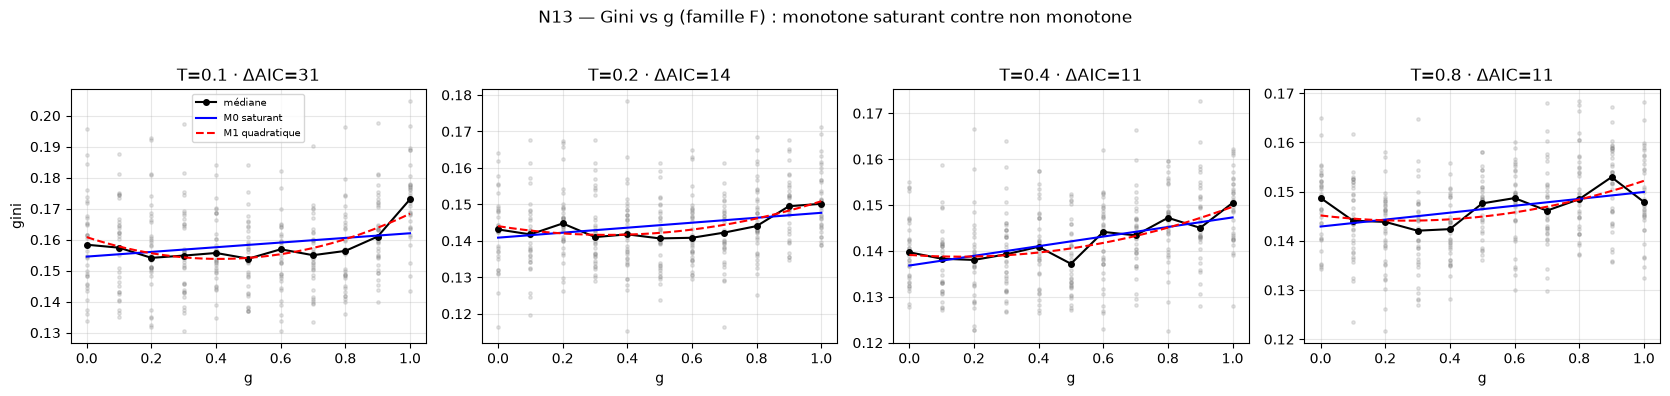

In [26]:
# -----------------------------------------------------------------------------
# N13. FORME DE LA RÉPONSE  (nuages : F)
# -----------------------------------------------------------------------------
def fit_M0(x, y):
    rng_x = max(x.max() - x.min(), 1e-9)
    p0 = [y.mean(), y.max() - y.min() or 1e-6, 0.3 * rng_x]
    try:
        f = lambda xx, a, b, c: a + b * (1 - np.exp(-(xx - x.min()) / c))
        popt, _ = curve_fit(
            f,
            x,
            y,
            p0=p0,
            bounds=(
                [-np.inf, -np.inf, 1e-3 * rng_x],
                [np.inf, np.inf, 50 * rng_x],
            ),
            maxfev=4000,
        )
        rss = float(((y - f(x, *popt)) ** 2).sum())
        return rss, 3, (lambda xx, p=popt: f(xx, *p))
    except Exception:
        b, rss, k = ols(x[:, None], y)
        return rss, k + 1, (lambda xx, b=b: b[0] + b[1] * xx)
    
def fit_M1(x, y):
    c = np.polyfit(x, y, 2); rss = float(((y - np.polyval(c, x)) ** 2).sum())
    argmin = -c[1] / (2 * c[0]) if c[0] != 0 else np.nan
    return rss, 3, c, argmin

def aic(rss, n, k): return n * np.log(max(rss, 1e-300) / n) + 2 * k

def donnees_F(indic, T, coord):
    xs, ys, ss = [], [], []
    for s in SEEDS:
        for g in grille("F", "g"):
            r = ind_meta(fam="F", seed=s, g=g, T=T)
            if r is None: continue
            xs.append(g if coord == "g" else r["rho"]); ys.append(r[indic]); ss.append(s)
    return np.array(xs), np.array(ys), np.array(ss)

def analyse_forme(indic, T, coord, n_boot=None):
    x, y, ss = donnees_F(indic, T, coord)
    ok = np.isfinite(x) & np.isfinite(y); x, y, ss = x[ok], y[ok], ss[ok]
    if len(y) < 40: return None
    rss0, k0, f0 = fit_M0(x, y); rss1, k1, c1, am = fit_M1(x, y)
    lo, hi = x.min(), x.max(); marge = 0.05 * (hi - lo)
    r = np.random.default_rng(3); seeds_u = np.unique(ss); dA, interior, convex = [], [], []
    for _ in range(n_boot or N_BOOT_FIT):
        pick = r.choice(seeds_u, len(seeds_u)); idx = np.concatenate([np.where(ss == s)[0] for s in pick])
        xb, yb = x[idx], y[idx]
        a0, kk0, _ = fit_M0(xb, yb); a1, kk1, cb, amb = fit_M1(xb, yb)
        dA.append(aic(a0, len(yb), kk0) - aic(a1, len(yb), kk1)); convex.append(cb[0] > 0)
        interior.append(bool(cb[0] > 0 and np.isfinite(amb) and lo + marge < amb < hi - marge))
    dA = np.array(dA)
    minimum = (np.median(dA) > 10) and np.mean(convex) > 0.95 and np.mean(interior) >= 0.95
    return dict(dAIC=float(np.median(dA)), dAIC_ci=(float(np.percentile(dA, 2.5)), float(np.percentile(dA, 97.5))),
                argmin=float(am), p_int=float(np.mean(interior)), minimum=bool(minimum), x=x, y=y, f0=f0, c1=c1)

def run_N13():
    Gs = grille("F", "g"); Ts = grille("F", "T")
    if len(Gs) < 5: raise RuntimeError("Famille F absente -> générer F (04c)")
    res = {}; print(f"N13 : {len(Ts)} niveaux de T")
    print(f"{'indic':7s} {'coord':5s} {'T':>4s} {'ΔAIC(M0−M1)':>13s} {'IC95':>20s} {'argmin':>8s} {'P(int)':>7s}  minimum ?")
    for indic in PRIMAIRES + ("twonn",):
        for coord in ("g", "rho"):
            for T in Ts:
                a = analyse_forme(indic, T, coord)
                if a is None: continue
                res[(indic, coord, T)] = a
                print(f"{indic:7s} {coord:5s} {T:4.1f} {a['dAIC']:13.1f} {fmt_ci(a['dAIC_ci']):>20s} {a['argmin']:8.3f} {a['p_int']:7.2f}  {'OUI' if a['minimum'] else 'non'}")
                add_row(test="N13", famille="F", param=coord, charge=indic, T=T, m=3, seed="ALL", valeur_mediane=a["dAIC"],
                        note=f"dAIC(M0-M1) IC95={fmt_ci(a['dAIC_ci'])} ; argmin={a['argmin']:.3f} ; P(interieur)={a['p_int']:.2f} ; minimum={a['minimum']}")
    # ---- H3 : indicateur primaire, mêmes coordonnées, >= 2 niveaux de T
    h3 = {(i, c): sum(res[(i, c, T)]["minimum"] for T in Ts if (i, c, T) in res) for i in PRIMAIRES for c in ("g", "rho")}
    ok = any(n >= 2 for n in h3.values())
    verdict("H3", "SOUTENUE" if ok else "NON SOUTENUE", "niveaux de T avec minimum accepté : " + "; ".join(f"{i}/{c}: {n}" for (i, c), n in h3.items()))
    # ---- figure : gini vs g pour les 4 T, ajustements M0 / M1
    fig, axes = plt.subplots(1, len(Ts), figsize=(4.2 * len(Ts), 3.8), squeeze=False)
    for ax, T in zip(axes[0], Ts):
        a = res.get(("gini", "g", T))
        if a is None: continue
        gs = np.unique(a["x"]); med = [np.median(a["y"][a["x"] == g]) for g in gs]
        ax.scatter(a["x"], a["y"], s=6, alpha=0.2, color="gray"); ax.plot(gs, med, "ko-", ms=4, label="médiane")
        xx = np.linspace(gs.min(), gs.max(), 200); ax.plot(xx, a["f0"](xx), "b-", label="M0 saturant"); ax.plot(xx, np.polyval(a["c1"], xx), "r--", label="M1 quadratique")
        ax.set_title(f"T={T} · ΔAIC={a['dAIC']:.0f}"); ax.set_xlabel("g"); ax.grid(True, alpha=0.3)
        if T == Ts[0]: ax.set_ylabel("gini"); ax.legend(fontsize=7)
    plt.suptitle("N13 — Gini vs g (famille F) : monotone saturant contre non monotone", y=1.03); plt.tight_layout(); savefig("N13_forme_reponse.png"); plt.show()
    return res

n13 = safe_run("N13", run_N13)

## N14 — Robustesse aux hyperparamètres (H7)
**Nuages attendus** : famille **I** (`tau`, `N`, `m` variés **un à la fois**, g ∈ {0,1 ; 0,4 ; 0,7}, T = 0,40) ; référence = famille **F** aux mêmes (g, T) avec τ = 7, N = 300, m = 3.
Pour chaque variante et indicateur : effet de g, Δ = indicateur(g=0,7) − indicateur(g=0,1), apparié par graine, avec IC bootstrap ; comparé au Δ de référence. **Robuste** si même signe et IC qui se recouvrent. Ajout : niveau du **nul iid** (gaussien, d = 6) en fonction de N, pour dissocier effet de taille finie et effet de g. **H7** : ≥ 80 % de cas robustes.

variante   indic     Δ variante                   IC95  Δ référence                   IC95  robuste ?
tau=3      gini         0.00614    [0.001643; 0.01068]     0.004337   [0.001103; 0.009639]  oui
tau=15     gini         0.00929    [0.004965; 0.01133]     0.004337   [0.001103; 0.009639]  oui
tau=30     gini        0.009134    [0.003893; 0.01379]     0.004337   [0.001103; 0.009639]  oui
N=150      gini         0.00676   [-0.002787; 0.01128]     0.004337   [0.001103; 0.009639]  oui
N=600      gini        0.006802  [0.0006735; 0.009828]     0.004337   [0.001103; 0.009639]  oui
N=1200     gini         0.00544   [0.003848; 0.008229]     0.004337   [0.001103; 0.009639]  oui
m=5        gini      -0.0003599  [-0.002926; 0.004266]     0.004337   [0.001103; 0.009639]  NON
tau=3      e2m2        0.007721     [0.0035; 0.009903]     0.006856      [0.002; 0.009945]  oui
tau=15     e2m2        0.007676    [0.004023; 0.01006]     0.006856      [0.002; 0.009945]  oui
tau=30     e2m2        0.008398   

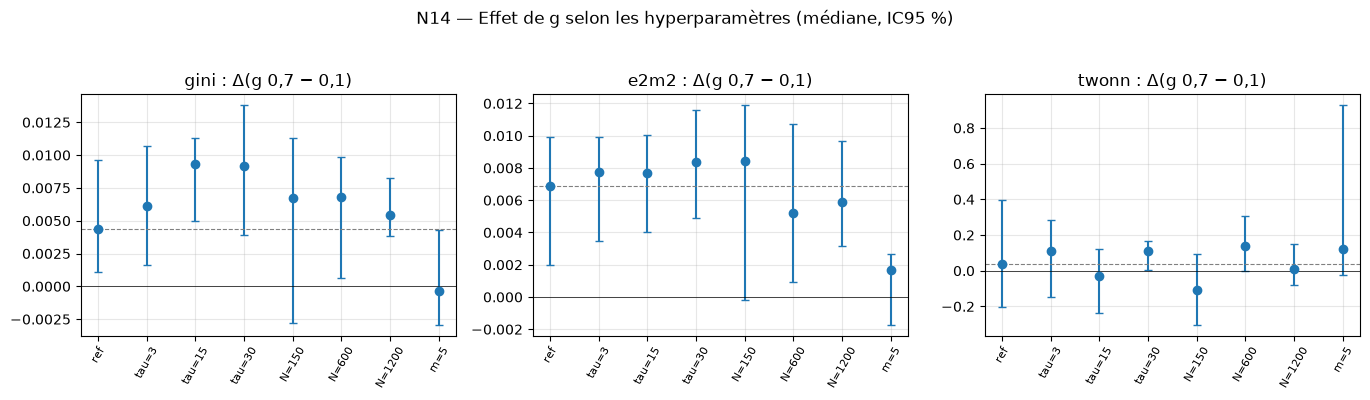

In [27]:
# -----------------------------------------------------------------------------
# N14. ROBUSTESSE AUX HYPERPARAMÈTRES  (nuages : I ; F en référence)
# -----------------------------------------------------------------------------
def run_N14():
    GI = (0.1, 0.7); T = 0.40
    variantes = [("tau", 3), ("tau", 15), ("tau", 30), ("N", 150), ("N", 600), ("N", 1200), ("m", 5)]
    if not any(d["famille"] == "I" for d in INDEX2): raise RuntimeError("Famille I absente -> générer I (04c)")
    incompletes = []
    for nom, val in variantes:
        params = dict(tau=val if nom == "tau" else 7, N=val if nom == "N" else 300, m=val if nom == "m" else 3)
        n_communes = sum(all(get_cloud(fam="I", seed=s, g=g, T=T, **params) is not None for g in GI) for s in SEEDS)
        if n_communes < 6: incompletes.append(f"{nom}={val} ({n_communes}/{len(SEEDS)} graines communes)")
    if incompletes: raise RuntimeError("Famille I incomplète pour N14 : " + ", ".join(incompletes))
    indics = PRIMAIRES + ("twonn",)
    def delta(getter, indic):
        out = []
        for s in SEEDS:
            lo, hi = getter(s, GI[0]), getter(s, GI[1])
            if lo is not None and hi is not None: out.append(hi[indic] - lo[indic])
        return np.array(out)
    base = lambda s, g: ind_meta(fam="F", seed=s, g=g, T=T)
    res = {}; robustes = []
    print(f"{'variante':10s} {'indic':7s} {'Δ variante':>12s} {'IC95':>22s} {'Δ référence':>12s} {'IC95':>22s}  robuste ?")
    for indic in indics:
        db = delta(base, indic); cb = boot_ci(db); res[("ref", indic)] = (float(np.median(db)), cb)
        for nom, val in variantes:
            kw = dict(tau=val if nom == "tau" else 7, N=val if nom == "N" else 300, m=val if nom == "m" else 3)
            getter = lambda s, g, kw=kw: ind_meta(fam="I", seed=s, g=g, T=T, **kw)
            dv = delta(getter, indic)
            if len(dv) < 6: continue
            cv = boot_ci(dv); mv = float(np.median(dv)); mb = float(np.median(db))
            ok = (np.sign(mv) == np.sign(mb)) and not (cv[1] < cb[0] or cb[1] < cv[0])
            res[(f"{nom}={val}", indic)] = (mv, cv, ok)
            if indic in PRIMAIRES: robustes.append(ok)
            print(f"{nom+'='+str(val):10s} {indic:7s} {mv:12.4g} {fmt_ci(cv):>22s} {mb:12.4g} {fmt_ci(cb):>22s}  {'oui' if ok else 'NON'}")
            add_row(test="N14", famille="I", variante=f"{nom}={val}", param="g(0.7-0.1)", charge=indic, T=T, seed="ALL", n_samples=len(dv),
                    valeur_mediane=mv, note=f"IC95={fmt_ci(cv)} ; reference={mb:.4f} IC95={fmt_ci(cb)} ; robuste={ok}")
    frac = float(np.mean(robustes)) if robustes else float("nan")
    verdict("H7", "SOUTENUE" if frac >= 0.8 else "NON SOUTENUE", f"{sum(robustes)}/{len(robustes)} cas robustes ({100*frac:.0f} %)")
    # ---- niveau du nul iid selon N (effet de taille finie)
    print("\n--- Nul iid gaussien (d=6) selon N : médiane (IQR) sur 30 tirages ---")
    nul_N = {}
    for N in (150, 300, 600, 1200):
        r = np.random.default_rng(N); vals = [ind_array((lambda Z: (Z - Z.mean(0)) / Z.std(0))(r.normal(size=(N, 6))), 3) for _ in range(30)]
        for k in ("gini", "e2m2"):
            v = np.array([x[k] for x in vals]); nul_N[(N, k)] = float(np.median(v))
            add_row(test="N14", famille="nul_iid", variante=f"N={N}", param="N", param_value=N, charge=k, valeur_mediane=float(np.median(v)),
                    std_inter_graines=float(v.std(ddof=1)), n_samples=30, note="nul gaussien iid d=6")
        print(f"N={N:5d}  gini={nul_N[(N,'gini')]:.4f}  e2m2={nul_N[(N,'e2m2')]:.5f}")
    fig, axes = plt.subplots(1, len(indics), figsize=(4.6 * len(indics), 3.8), squeeze=False)
    for ax, indic in zip(axes[0], indics):
        labs, meds, los, his = ["ref"], [res[("ref", indic)][0]], [res[("ref", indic)][1][0]], [res[("ref", indic)][1][1]]
        for nom, val in variantes:
            if (f"{nom}={val}", indic) in res:
                m_, c_, _ = res[(f"{nom}={val}", indic)]; labs.append(f"{nom}={val}"); meds.append(m_); los.append(c_[0]); his.append(c_[1])
        ax.errorbar(range(len(labs)), meds, yerr=[np.array(meds) - np.array(los), np.array(his) - np.array(meds)], fmt="o", capsize=3)
        ax.axhline(meds[0], color="gray", ls="--", lw=0.8); ax.axhline(0, color="k", lw=0.5)
        ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=60, fontsize=8); ax.set_title(f"{indic} : Δ(g 0,7 − 0,1)"); ax.grid(True, alpha=0.3)
    plt.suptitle("N14 — Effet de g selon les hyperparamètres (médiane, IC95 %)", y=1.04); plt.tight_layout(); savefig("N14_robustesse.png"); plt.show()
    return res

n14 = safe_run("N14", run_N14)

## N15 — Benchmark à vérité terrain : synchronisation de deux Rössler (H4)
**Nuages attendus** : famille **J** (`uni` = pilote → répondant, `bi` = couplage mutuel ; ε ∈ [0 ; 0,3] en 25 valeurs, grille resserrée sur 0–0,05 ; T = 0,10 ; m = 3). Sidecar optionnel `R_famJ_…npy` (cohérence de phase de Hilbert sur les signaux bruts) ; à défaut, la phase est estimée **depuis le nuage** (u = x(t+τ), v = différence centrée x(t+2τ) − x(t), phase = atan2) : approximation, comparée au sidecar quand il existe.
**Règle fixée à l'avance** : ε_c = milieu de l'intervalle où la courbe médiane franchit, pour la dernière fois, le niveau médian entre ses plateaux bas (3 premiers points) et haut (3 derniers) ; comparaison en **indices d'intervalle**, la grille n'étant pas uniforme. **H4** : |ε_c(indice) − ε_c(R)| ≤ 1 intervalle de grille dans ≥ 70 % des rééchantillonnages bootstrap (graines), dans les deux directions (soutenue) ou une seule (partielle). Transition de référence : Rosenblum, Pikovsky & Kurths (1996).

[uni] écart moyen |R_proxy − R_vrai| = 0.022 (R vrai utilisé)
[uni] ε_c(R)=0.2026 (Hilbert (sidecar)) ; ε_c(gini)=0.1497 P(≤1 intervalle)=0.14 ; ε_c(e2m2)=0.1497 P(≤1 intervalle)=0.14 ; ε_c(pr)=0.2380 P(≤1 intervalle)=0.23 ; ε_c(twonn)=0.2558 P(≤1 intervalle)=0.14
[bi] écart moyen |R_proxy − R_vrai| = 0.050 (R vrai utilisé)
[bi] ε_c(R)=0.0375 (Hilbert (sidecar)) ; ε_c(gini)=0.2380 P(≤1 intervalle)=0.00 ; ε_c(e2m2)=0.0789 P(≤1 intervalle)=0.00 ; ε_c(pr)=0.0600 P(≤1 intervalle)=0.00 ; ε_c(twonn)=0.2026 P(≤1 intervalle)=0.00


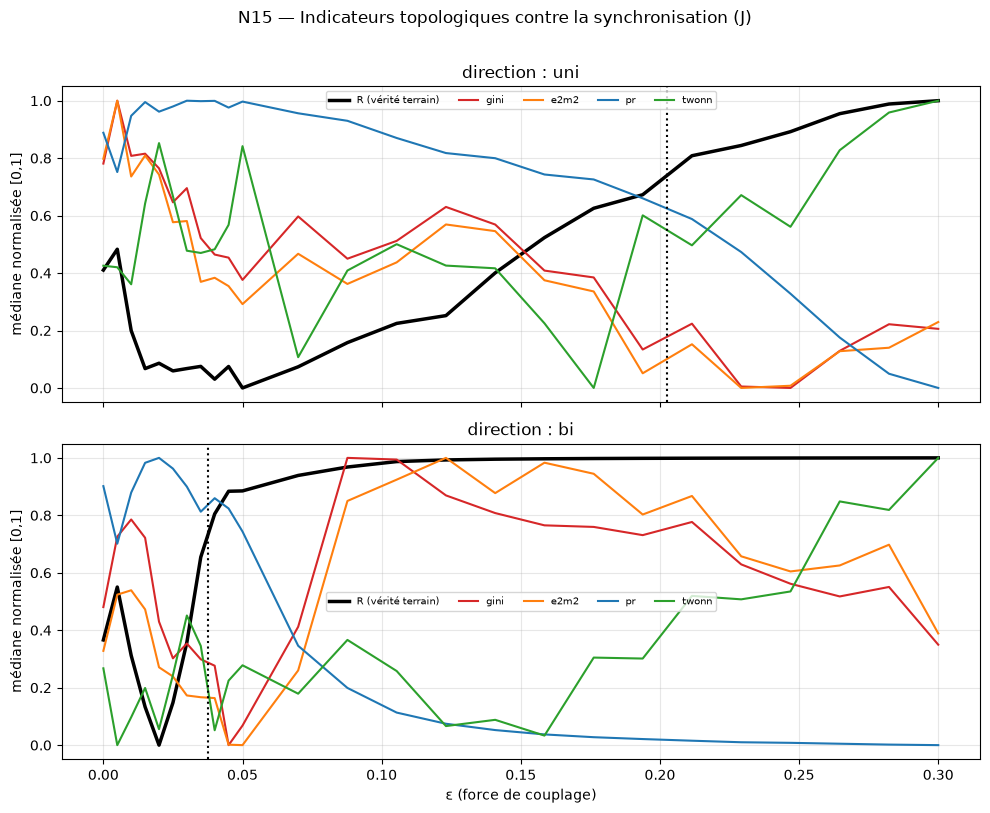

uni vs bi (gini) : 13/25 valeurs de ε avec p de Holm < 0.05
   ⇒ H4 : NON SOUTENUE — gini: directions ok=[]; e2m2: directions ok=[] ; P(≤1 intervalle)={'uni': {'gini': 0.14, 'e2m2': 0.135, 'pr': 0.23, 'twonn': 0.145}, 'bi': {'gini': 0.0, 'e2m2': 0.0, 'pr': 0.0, 'twonn': 0.0}}


In [28]:
# -----------------------------------------------------------------------------
# N15. SYNCHRONISATION — vérité terrain  (nuages : J)
# -----------------------------------------------------------------------------
def phase_proxy_R(X, m=3):
    def phase(c):
        u = X[:, c * m + 1] - X[:, c * m + 1].mean(); v = X[:, c * m + 2] - X[:, c * m]
        return np.arctan2(v / (v.std() or 1.0), u / (u.std() or 1.0))
    return float(abs(np.mean(np.exp(1j * (phase(0) - phase(1))))))

def R_vrai(direction, eps, seed):
    p = Path(NUAGE_DIR) / f"R_famJ_{direction}_eps{eps:.4f}_T0.10_m3_seed{seed}.npy"
    return float(np.load(p)) if p.exists() else None

def eps_c_idx(grid, y, signed=False):
    """Indice de l'intervalle où la courbe médiane franchit (dernière traversée) le niveau médian entre ses plateaux bas
    (moyenne des 3 premiers points) et haut (3 derniers) : robuste au bruit et aux grilles non uniformes. Repli : plus forte variation.
    (`signed` est conservé pour compatibilité ; le sens de la transition est déduit des plateaux.)"""
    y = np.asarray(y, float); lo, hi = np.nanmean(y[:3]), np.nanmean(y[-3:]); sgn = 1.0 if hi >= lo else -1.0
    z = sgn * (y - 0.5 * (lo + hi)); below = np.where(z < 0)[0]
    if len(below) and below.max() < len(y) - 1: return int(below.max())
    return int(np.nanargmax(np.abs(np.diff(y))))

def eps_c(grid, y, signed=False):
    i = eps_c_idx(grid, y, signed); return 0.5 * (grid[i] + grid[i + 1])

def run_N15():
    eps_g = grille("J", "eps", var="uni")
    if len(eps_g) < 5: raise RuntimeError("Famille J absente -> générer J (04c)")
    out = {}; crit = {}
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    for ax, direction in zip(axes, ("uni", "bi")):
        seeds = seeds_communes("J", var=direction, eps=eps_g[0], T=0.10)
        M = {k: np.full((len(eps_g), len(seeds)), np.nan) for k in ("R", "gini", "e2m2", "pr", "twonn")}; proxy_err = []
        for a, e in enumerate(eps_g):
            for b, s in enumerate(seeds):
                X = get_cloud(fam="J", seed=s, var=direction, eps=e, T=0.10); r = ind_meta(fam="J", seed=s, var=direction, eps=e, T=0.10)
                if X is None or r is None: continue
                rp = phase_proxy_R(X); rv = R_vrai(direction, e, s)
                M["R"][a, b] = rv if rv is not None else rp
                if rv is not None: proxy_err.append(abs(rp - rv))
                for k in ("gini", "e2m2", "pr", "twonn"): M[k][a, b] = r[k]
        src = "Hilbert (sidecar)" if proxy_err else "proxy depuis le nuage"
        if proxy_err: print(f"[{direction}] écart moyen |R_proxy − R_vrai| = {np.mean(proxy_err):.3f} (R vrai utilisé)")
        out[direction] = (eps_g, M)
        for k in M:
            med = np.nanmedian(M[k], axis=1)
            for a, e in enumerate(eps_g):
                add_row(test="N15", famille="J", variante=direction, param="eps", param_value=round(e, 4), charge=k, T=0.10, m=3, seed="ALL",
                        valeur_mediane=float(med[a]), n_samples=len(seeds))
        # ε_c et bootstrap sur les graines
        rng = np.random.default_rng(15); ec0 = {k: eps_c(eps_g, np.nanmedian(M[k], axis=1), signed=(k == "R")) for k in M}
        hits = {k: [] for k in M if k != "R"}
        for _ in range(N_BOOT_FIT):
            pick = rng.integers(0, len(seeds), len(seeds)); iR = eps_c_idx(eps_g, np.nanmedian(M["R"][:, pick], axis=1), signed=True)
            for k in hits: hits[k].append(abs(eps_c_idx(eps_g, np.nanmedian(M[k][:, pick], axis=1)) - iR) <= 1)
        crit[direction] = {k: float(np.mean(v)) for k, v in hits.items()}
        print(f"[{direction}] ε_c(R)={ec0['R']:.4f} ({src}) ; " + " ; ".join(f"ε_c({k})={ec0[k]:.4f} P(≤1 intervalle)={crit[direction][k]:.2f}" for k in hits))
        for k in hits:
            add_row(test="N15", famille="J", variante=direction, param="eps_c", charge=k, valeur_mediane=ec0[k], seed="ALL",
                    note=f"eps_c(R)={ec0['R']:.4f} ; P(|d_intervalle|<=1)={crit[direction][k]:.2f}")
        def sc(v): v = np.asarray(v, float); lo, hi = np.nanmin(v), np.nanmax(v); return (v - lo) / ((hi - lo) or 1.0)
        ax.plot(eps_g, sc(np.nanmedian(M["R"], axis=1)), "k-", lw=2.5, label="R (vérité terrain)")
        for k, c in (("gini", "tab:red"), ("e2m2", "tab:orange"), ("pr", "tab:blue"), ("twonn", "tab:green")):
            ax.plot(eps_g, sc(np.nanmedian(M[k], axis=1)), color=c, label=k)
        ax.axvline(ec0["R"], color="k", ls=":"); ax.set_title(f"direction : {direction}"); ax.set_ylabel("médiane normalisée [0,1]"); ax.grid(True, alpha=0.3); ax.legend(fontsize=7, ncol=5)
    axes[-1].set_xlabel("ε (force de couplage)")
    plt.suptitle("N15 — Indicateurs topologiques contre la synchronisation (J)", y=1.01); plt.tight_layout(); savefig("N15_synchronisation.png"); plt.show()
    # ---- comparaison uni / bi (indépendants), gini
    (eg, Mu), (_, Mb) = out["uni"], out["bi"]; ps = [float(stats.mannwhitneyu(Mu["gini"][a][np.isfinite(Mu["gini"][a])], Mb["gini"][a][np.isfinite(Mb["gini"][a])]).pvalue) for a in range(len(eg))]
    ph = holm(ps); print(f"uni vs bi (gini) : {int(np.sum(ph < ALPHA))}/{len(eg)} valeurs de ε avec p de Holm < {ALPHA}")
    add_row(test="N15", famille="J", param="uni_vs_bi", charge="gini", valeur_mediane=float(np.sum(ph < ALPHA)), n_samples=len(eg), note="nombre de eps avec p Holm<0.05")
    # ---- verdict H4
    ok_dirs = {k: [d for d in ("uni", "bi") if crit[d][k] >= 0.70] for k in PRIMAIRES}
    both = [k for k, v in ok_dirs.items() if len(v) == 2]; one = [k for k, v in ok_dirs.items() if len(v) == 1]
    st = "SOUTENUE" if both else ("PARTIELLE" if one else "NON SOUTENUE")
    verdict("H4", st, "; ".join(f"{k}: directions ok={v}" for k, v in ok_dirs.items()) + f" ; P(≤1 intervalle)={crit}")
    return out

n15 = safe_run("N15", run_N15)

dir réf indic  |   s_hat     IC95 % bootstrap  P(s>0) |  r(s=0) r(s_hat) | p_surrogate
bi  R   gini   | +0.0325 [+0.0275 ; +0.0375]    1.00 |   +0.07    +0.93 |       0.130
bi  R   e2m2   | +0.0375 [+0.0325 ; +0.0800]    1.00 |   +0.16    +0.93 |       0.242 ⚠ bord de S_GRID
bi  R   pr     | +0.0275 [+0.0200 ; +0.0275]    1.00 |   -0.80    -0.92 |       0.208
bi  R   twonn  | +0.0700 [+0.0150 ; +0.0800]    1.00 |   +0.36    -0.91 |       0.186 ⚠ bord de S_GRID
bi  Cx  gini   | +0.0200 [+0.0150 ; +0.0250]    1.00 |   +0.60    +0.93 |       0.427
bi  Cx  e2m2   | +0.0200 [+0.0150 ; +0.0275]    1.00 |   +0.67    +0.97 |       0.343
bi  Cx  pr     | -0.0000 [-0.0000 ; -0.0000]    0.00 |   -1.00    -1.00 |       0.002
bi  Cx  twonn  | +0.0625 [-0.0188 ; +0.0750]    0.96 |   +0.40    -0.91 |       0.242
uni R   gini   | +0.0225 [-0.0000 ; +0.0380]    0.97 |   +0.60    +0.73 |       0.553
uni R   e2m2   | +0.0150 [-0.0000 ; +0.0500]    0.97 |   +0.62    +0.84 |       0.214
uni R   pr     | -0

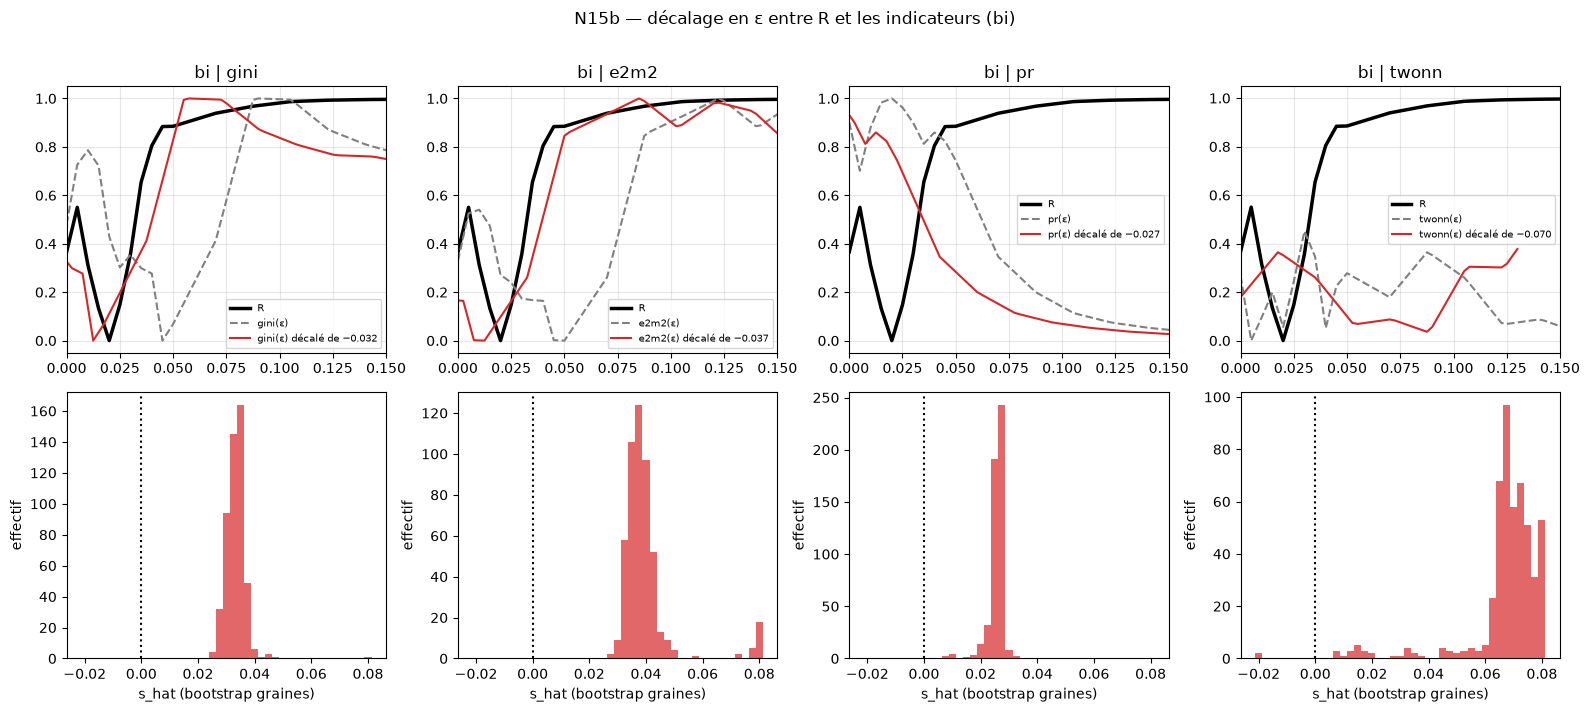

In [29]:
# -----------------------------------------------------------------------------
# N15b. DÉCALAGE OPTIMAL EN ε  (référence ↔ indicateurs topologiques, famille J)
# À placer APRÈS la cellule N15 : utilise `n15` (= sortie de run_N15, donc les matrices par graine).
#
# Question : Y(ε) ≈ f( Ref(ε − s) ) avec s > 0 ?  -> s_hat, IC95 % bootstrap sur les graines,
#            et comparaison à un nul « courbe lisse aléatoire » (surrogates à phases aléatoires).
# Deux références : R (Hilbert, vérité terrain de phase) et Cx = |corr(x1, x2)| lue dans le nuage
# (proxy d'un couplage d'amplitude / d'état, sans sidecar).
# -----------------------------------------------------------------------------
EPS_MAX_FIT = 0.10                          # fenêtre de la référence : ε ∈ [0 ; 0,10]
S_GRID = np.arange(-0.02, 0.0801, 0.0025)   # décalages testés (s > 0 : l'indicateur RÉAGIT PLUS TARD que la référence)
B_SHIFT, N_SURR = 500, 500
IND = ("gini", "e2m2", "pr", "twonn")
DIRS = ("bi", "uni")

def _corr_shift(fine, ref, y):
    """r(s) = corr( ref(e) , y(e+s) ) pour e ≤ EPS_MAX_FIT ; NaN si trop peu de points ou courbe plate."""
    rs = np.full(len(S_GRID), np.nan); win = fine <= EPS_MAX_FIT
    for i, s in enumerate(S_GRID):
        m = win & (fine + s >= 0) & (fine + s <= fine[-1])
        if m.sum() < 12: continue
        a = ref[m]; b = np.interp(fine[m] + s, fine, y)
        if a.std() < 1e-12 or b.std() < 1e-12: continue
        rs[i] = np.corrcoef(a, b)[0, 1]
    return rs

def _best(rs, sign=None):
    if sign is None: sign = 1.0 if np.nanmax(rs) >= -np.nanmin(rs) else -1.0
    j = int(np.nanargmax(sign * rs)); return S_GRID[j], rs[j], sign

def _phase_surrogate(y, rng):
    f = np.fft.rfft(y - y.mean()); ph = rng.uniform(0, 2 * np.pi, len(f)); ph[0] = 0.0
    if len(y) % 2 == 0: ph[-1] = 0.0
    return np.fft.irfft(np.abs(f) * np.exp(1j * ph), n=len(y)) + y.mean()

def _cx_matrix(direction, eps_g, m=3):
    """|corr(x1(t), x2(t))| par (ε, graine), lue dans le nuage (colonnes 0 et m = x(t) des deux canaux)."""
    seeds = seeds_communes("J", var=direction, eps=eps_g[0], T=0.10)
    C = np.full((len(eps_g), len(seeds)), np.nan)
    for a, e in enumerate(eps_g):
        for b, s in enumerate(seeds):
            X = get_cloud(fam="J", seed=s, var=direction, eps=e, T=0.10)
            if X is not None: C[a, b] = abs(np.corrcoef(X[:, 0], X[:, m])[0, 1])
    return C

def _sc(v): v = np.asarray(v, float); lo, hi = np.nanmin(v), np.nanmax(v); return (v - lo) / ((hi - lo) or 1.0)

def run_N15b():
    rng = np.random.default_rng(1515); res = {}; plot_cache = {}
    print(f"{'dir':3s} {'réf':3s} {'indic':6s} | {'s_hat':>7s} {'IC95 % bootstrap':>20s} {'P(s>0)':>7s} | {'r(s=0)':>7s} {'r(s_hat)':>8s} | {'p_surrogate':>11s}")
    for direction in DIRS:
        eps_g, M = n15[direction]; fine = np.linspace(eps_g[0], eps_g[-1], 121)
        REF = {"R": M["R"], "Cx": _cx_matrix(direction, eps_g)}
        n_seed = M["R"].shape[1]
        for rname, RM in REF.items():
            if RM.shape[1] != n_seed: RM = RM[:, :n_seed]
            for k in IND:
                R0 = np.interp(fine, eps_g, np.nanmedian(RM, axis=1)); Y0 = np.interp(fine, eps_g, np.nanmedian(M[k], axis=1))
                rs0 = _corr_shift(fine, R0, Y0); s0, r0, sg = _best(rs0); rzero = rs0[int(np.argmin(np.abs(S_GRID)))]
                sh = []
                for _ in range(B_SHIFT):
                    pick = rng.integers(0, n_seed, n_seed)
                    Rb = np.interp(fine, eps_g, np.nanmedian(RM[:, pick], axis=1)); Yb = np.interp(fine, eps_g, np.nanmedian(M[k][:, pick], axis=1))
                    rsb = _corr_shift(fine, Rb, Yb)
                    if np.isfinite(rsb).any(): sh.append(_best(rsb, sign=sg)[0])
                sh = np.array(sh); lo, hi = np.percentile(sh, [2.5, 97.5]); p_pos = float(np.mean(sh > 0))
                # nul : |r| maximal sur s pour une courbe lisse aléatoire de même spectre que Y
                obs = np.nanmax(np.abs(rs0)); null = []
                for _ in range(N_SURR):
                    rsn = _corr_shift(fine, R0, _phase_surrogate(Y0, rng))
                    if np.isfinite(rsn).any(): null.append(np.nanmax(np.abs(rsn)))
                p_sur = (1 + np.sum(np.array(null) >= obs)) / (1 + len(null))
                edge = " ⚠ bord de S_GRID" if (s0 in (S_GRID[0], S_GRID[-1]) or lo <= S_GRID[0] or hi >= S_GRID[-1]) else ""
                print(f"{direction:3s} {rname:3s} {k:6s} | {s0:+7.4f} [{lo:+.4f} ; {hi:+.4f}] {p_pos:7.2f} | {rzero:+7.2f} {r0:+8.2f} | {p_sur:11.3f}{edge}")
                add_row(test="N15b", famille="J", variante=direction, param="shift_opt", charge=f"{k}|ref={rname}", T=0.10, m=3, seed="ALL",
                        valeur_mediane=float(s0), n_samples=len(sh),
                        note=f"IC95=[{lo:.4f}; {hi:.4f}] ; P(s>0)={p_pos:.2f} ; r(0)={rzero:.2f} ; r(s_hat)={r0:.2f} ; p_surrogate={p_sur:.3f}")
                res[(direction, rname, k)] = dict(s_hat=s0, ci=(lo, hi), p_pos=p_pos, r0=rzero, r_best=r0, p_sur=p_sur, boots=sh)
                plot_cache[(direction, rname, k)] = (R0, Y0, s0)
    # ---- figure (bi, référence R) : courbes recalées + histogrammes du décalage
    fig, axes = plt.subplots(2, len(IND), figsize=(4 * len(IND), 7))
    for c, k in enumerate(IND):
        eps_g, M = n15["bi"]; fine = np.linspace(eps_g[0], eps_g[-1], 121); R0, Y0, s0 = plot_cache[("bi", "R", k)]
        ax = axes[0, c]; msk = fine <= 0.20
        ax.plot(fine[msk], _sc(R0)[msk], "k-", lw=2.5, label="R")
        ax.plot(fine[msk], _sc(Y0)[msk], "--", color="gray", label=f"{k}(ε)")
        ax.plot(fine[msk] - s0, _sc(Y0)[msk], color="tab:red", label=f"{k}(ε) décalé de −{s0:.3f}")
        ax.set_xlim(0, 0.15); ax.set_title(f"bi | {k}"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
        ax = axes[1, c]; ax.hist(res[("bi", "R", k)]["boots"], bins=np.append(S_GRID - 0.00125, S_GRID[-1] + 0.00125), color="tab:red", alpha=0.7)
        ax.axvline(0, color="k", ls=":"); ax.set_xlabel("s_hat (bootstrap graines)"); ax.set_ylabel("effectif")
    plt.suptitle("N15b — décalage en ε entre R et les indicateurs (bi)", y=1.01); plt.tight_layout(); savefig("N15b_decalage.png"); plt.show()
    return res

n15b = safe_run("N15b", run_N15b)


=== N15c [bi] — fenêtre de pente 0.02 ; résolution effective ≈ 0.020 en ε ===
courbe |                 montée max (ε) |               descente max (ε)
R      |  0.0300 [0.0300 ; 0.0350]* |  0.0150 [0.0100 ; 0.0150] 
Cx     |  0.0550 [0.0500 ; 0.0600]* |  0.0150 [0.0100 ; 0.0150] 
pr     |  0.0150 [0.0150 ; 0.0150]  |  0.0600 [0.0549 ; 0.0600]*
gini   |  0.0775 [0.0550 ; 0.0800]* |  0.0200 [0.0150 ; 0.0350] 
e2m2   |  0.0775 [0.0600 ; 0.1125]* |  0.0200 [0.0150 ; 0.2200] 
(* = landmark attendu pour la courbe ; bornes C_GRID : 0.010–0.280, un IC qui les touche signale un landmark non borné)

  écarts de seuil à R (montée), bootstrap apparié :
   ε(Cx,up) − ε(R,up) = +0.0250 [+0.0150 ; +0.0300]   P(>0) = 1.00
   ε(pr,down) − ε(R,up) = +0.0250 [+0.0200 ; +0.0300]   P(>0) = 1.00
   ε(gini,up) − ε(R,up) = +0.0475 [+0.0250 ; +0.0475]   P(>0) = 1.00
   ε(e2m2,up) − ε(R,up) = +0.0475 [+0.0300 ; +0.0825]   P(>0) = 1.00
   P(R < pr < gini) = 0.89
   P(R < pr < e2m2) = 0.98
   P(R < Cx < gini) = 

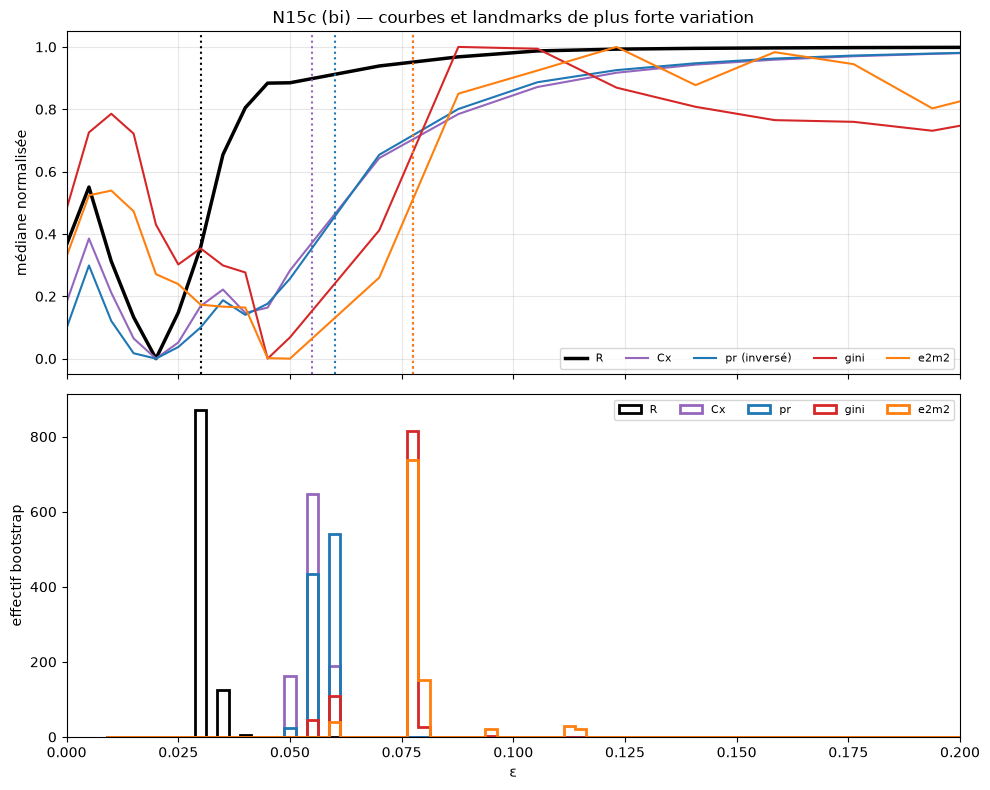

In [30]:
# -----------------------------------------------------------------------------
# N15c. LANDMARKS DE PLUS FORTE VARIATION ET ORDRE DES SEUILS  (famille J)
# À placer APRÈS la cellule N15 : utilise `n15` (matrices par graine). Aucune nouvelle génération.
#
# Idée : au lieu de recaler des courbes par corrélation (N15b), on localise pour chaque courbe médiane
# l'ε de plus forte montée (« up ») et de plus forte descente (« down »), avec IC bootstrap sur les graines,
# puis on teste l'ORDRE des seuils :  ε(R) < ε(pr) < ε(gini), ε(e2m2)   (hypothèse H4′, exploratoire).
# Pente = différence centrée sur une fenêtre FIXE de largeur W_SLOPE (la grille de ε n'est pas uniforme :
# une pente par intervalle favoriserait les intervalles étroits, donc le bruit).
# Cx = |corr(x1, x2)| lue dans le nuage : sans objet pour juger pr (circularité), utile pour gini/e2m2.
# -----------------------------------------------------------------------------
W_SLOPE = 0.02                                   # largeur de la fenêtre de pente (≈ pas de grille de la zone 0,05–0,3)
C_GRID = np.arange(0.010, 0.2801, 0.0025)        # centres candidats du landmark (jusqu'à 0,28 pour couvrir la montée lente de R en uni)
B_LM = 1000
CURVES15C = ("R", "Cx", "pr", "gini", "e2m2")    # twonn écarté (pas de décalage stable en N15b)
EXPECTED = {"R": "up", "Cx": "up", "pr": "down", "gini": "up", "e2m2": "up"}
DIRS15C = ("bi", "uni")

def _cx_mat15c(direction, eps_g, m=3):
    seeds = seeds_communes("J", var=direction, eps=eps_g[0], T=0.10)
    C = np.full((len(eps_g), len(seeds)), np.nan)
    for a, e in enumerate(eps_g):
        for b, s in enumerate(seeds):
            X = get_cloud(fam="J", seed=s, var=direction, eps=e, T=0.10)
            if X is not None: C[a, b] = abs(np.corrcoef(X[:, 0], X[:, m])[0, 1])
    return C

def _slope15c(eps_g, y):
    h = W_SLOPE / 2
    return (np.interp(C_GRID + h, eps_g, y) - np.interp(C_GRID - h, eps_g, y)) / W_SLOPE

def _landmarks(eps_g, y):
    sl = _slope15c(eps_g, y); return C_GRID[int(np.argmax(sl))], C_GRID[int(np.argmin(sl))]

def _sc15c(v): v = np.asarray(v, float); lo, hi = np.nanmin(v), np.nanmax(v); return (v - lo) / ((hi - lo) or 1.0)

def run_N15c():
    rng = np.random.default_rng(1516); res = {}
    for direction in DIRS15C:
        eps_g, M = n15[direction]; n_seed = M["R"].shape[1]
        MAT = {"R": M["R"], "Cx": _cx_mat15c(direction, eps_g)[:, :n_seed], "pr": M["pr"], "gini": M["gini"], "e2m2": M["e2m2"]}
        med = {k: np.nanmedian(MAT[k], axis=1) for k in CURVES15C}
        lm0 = {k: _landmarks(eps_g, med[k]) for k in CURVES15C}
        boots = {k: {"up": [], "down": []} for k in CURVES15C}
        for _ in range(B_LM):
            pick = rng.integers(0, n_seed, n_seed)      # mêmes graines pour toutes les courbes (bootstrap apparié)
            for k in CURVES15C:
                u, d = _landmarks(eps_g, np.nanmedian(MAT[k][:, pick], axis=1)); boots[k]["up"].append(u); boots[k]["down"].append(d)
        B = {k: {t: np.array(v) for t, v in boots[k].items()} for k in CURVES15C}
        print(f"\n=== N15c [{direction}] — fenêtre de pente {W_SLOPE} ; résolution effective ≈ {W_SLOPE:.3f} en ε ===")
        print(f"{'courbe':6s} | {'montée max (ε)':>30s} | {'descente max (ε)':>30s}")
        for k in CURVES15C:
            ci = {t: np.percentile(B[k][t], [2.5, 97.5]) for t in ("up", "down")}
            print(f"{k:6s} | {lm0[k][0]:7.4f} [{ci['up'][0]:.4f} ; {ci['up'][1]:.4f}]{'*' if EXPECTED[k]=='up' else ' '}"
                  f" | {lm0[k][1]:7.4f} [{ci['down'][0]:.4f} ; {ci['down'][1]:.4f}]{'*' if EXPECTED[k]=='down' else ' '}")
            for t, i in (("up", 0), ("down", 1)):
                add_row(test="N15c", famille="J", variante=direction, param=f"landmark_{t}", charge=k, T=0.10, m=3, seed="ALL",
                        valeur_mediane=float(lm0[k][i]), n_samples=B_LM, note=f"IC95=[{ci[t][0]:.4f}; {ci[t][1]:.4f}] ; fenetre={W_SLOPE}")
        print("(* = landmark attendu pour la courbe ; bornes C_GRID : "
              f"{C_GRID[0]:.3f}–{C_GRID[-1]:.3f}, un IC qui les touche signale un landmark non borné)")
        # ---- écarts à R (montée) et ordre des seuils
        LM = lambda k: B[k][EXPECTED[k]]
        print(f"\n  écarts de seuil à R (montée), bootstrap apparié :")
        for k in ("Cx", "pr", "gini", "e2m2"):
            dlt = LM(k) - B["R"]["up"]; lo, hi = np.percentile(dlt, [2.5, 97.5])
            print(f"   ε({k},{EXPECTED[k]}) − ε(R,up) = {np.median(dlt):+.4f} [{lo:+.4f} ; {hi:+.4f}]   P(>0) = {np.mean(dlt > 0):.2f}")
            add_row(test="N15c", famille="J", variante=direction, param="delta_vs_R", charge=k, T=0.10, m=3, seed="ALL",
                    valeur_mediane=float(np.median(dlt)), n_samples=B_LM, note=f"IC95=[{lo:.4f}; {hi:.4f}] ; P(>0)={np.mean(dlt > 0):.2f}")
        for name, chain in (("R < pr < gini", ("R", "pr", "gini")), ("R < pr < e2m2", ("R", "pr", "e2m2")),
                            ("R < Cx < gini", ("R", "Cx", "gini")), ("R < Cx < e2m2", ("R", "Cx", "e2m2"))):
            a, b, c = (LM(x) if x != "R" else B["R"]["up"] for x in chain)
            p = float(np.mean((a < b) & (b < c))); print(f"   P({name}) = {p:.2f}")
            add_row(test="N15c", famille="J", variante=direction, param="ordre", charge=name, T=0.10, m=3, seed="ALL",
                    valeur_mediane=p, n_samples=B_LM, note="proportion de rééchantillonnages respectant l'ordre strict")
        res[direction] = dict(lm0=lm0, boots=B, med=med, eps_g=eps_g)
    # ---- figure (bi) : courbes normalisées + distributions bootstrap des landmarks
    eps_g, med, B, lm0 = res["bi"]["eps_g"], res["bi"]["med"], res["bi"]["boots"], res["bi"]["lm0"]
    col = {"R": "k", "Cx": "tab:purple", "pr": "tab:blue", "gini": "tab:red", "e2m2": "tab:orange"}
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    for k in CURVES15C:
        y = _sc15c(med[k]); y = 1 - y if EXPECTED[k] == "down" else y
        axes[0].plot(eps_g, y, color=col[k], lw=2.5 if k == "R" else 1.5, label=k + (" (inversé)" if EXPECTED[k] == "down" else ""))
        axes[0].axvline(lm0[k][0 if EXPECTED[k] == "up" else 1], color=col[k], ls=":")
        axes[1].hist(B[k][EXPECTED[k]], bins=np.append(C_GRID - 0.00125, C_GRID[-1] + 0.00125), histtype="step", color=col[k], lw=2, label=k)
    axes[0].set_xlim(0, 0.2); axes[0].set_ylabel("médiane normalisée"); axes[0].legend(fontsize=8, ncol=5); axes[0].grid(alpha=0.3)
    axes[0].set_title("N15c (bi) — courbes et landmarks de plus forte variation")
    axes[1].set_xlabel("ε"); axes[1].set_ylabel("effectif bootstrap"); axes[1].legend(fontsize=8, ncol=5)
    plt.tight_layout(); savefig("N15c_landmarks.png"); plt.show()
    return res

n15c = safe_run("N15c", run_N15c)

[contrôle] autocorrélation de x1 au lag 1 de ligne : 0.87, 0.87, 0.88 (≥ 0,5 attendu si les lignes suivent le temps)
[contrôle] écart max |_j2_mesurer(nuage) − ind_meta| = 0.00e+00

J2 v2 [bi] : 25 epsilon, 35 graines, N=300, lags=[60, 96, 132, 168, 204, 240]
dispersion du nul entre lags (médiane sur ε, graines) : gini=0.009977 ; e2m2=0.01528   (à comparer au saut réel ci-dessous)

=== Contrôle de manipulation : réel / nul (médianes sur graines) ===
point             ε |          R_proxy |    |corr(x1,x2)| |               PR
ε min        0.0000 |     0.489/ 0.596 |     0.235/ 0.317 |     2.062/ 1.977
saut (bas)   0.0700 |     0.945/ 0.744 |     0.654/ 0.463 |     1.479/ 1.773
saut (haut)  0.0877 |     0.962/ 0.557 |     0.782/ 0.315 |     1.326/ 1.971
ε max        0.3000 |     0.990/ 0.499 |     0.977/ 0.159 |     1.117/ 2.087
R_proxy(réel) − R_proxy(nul) à ε max = +0.491  ->  NUL VALIDE pour la phase

=== Saut (0.045–0.070) → (0.088–0.125) ; fenêtres choisies après N15c : exploratoire

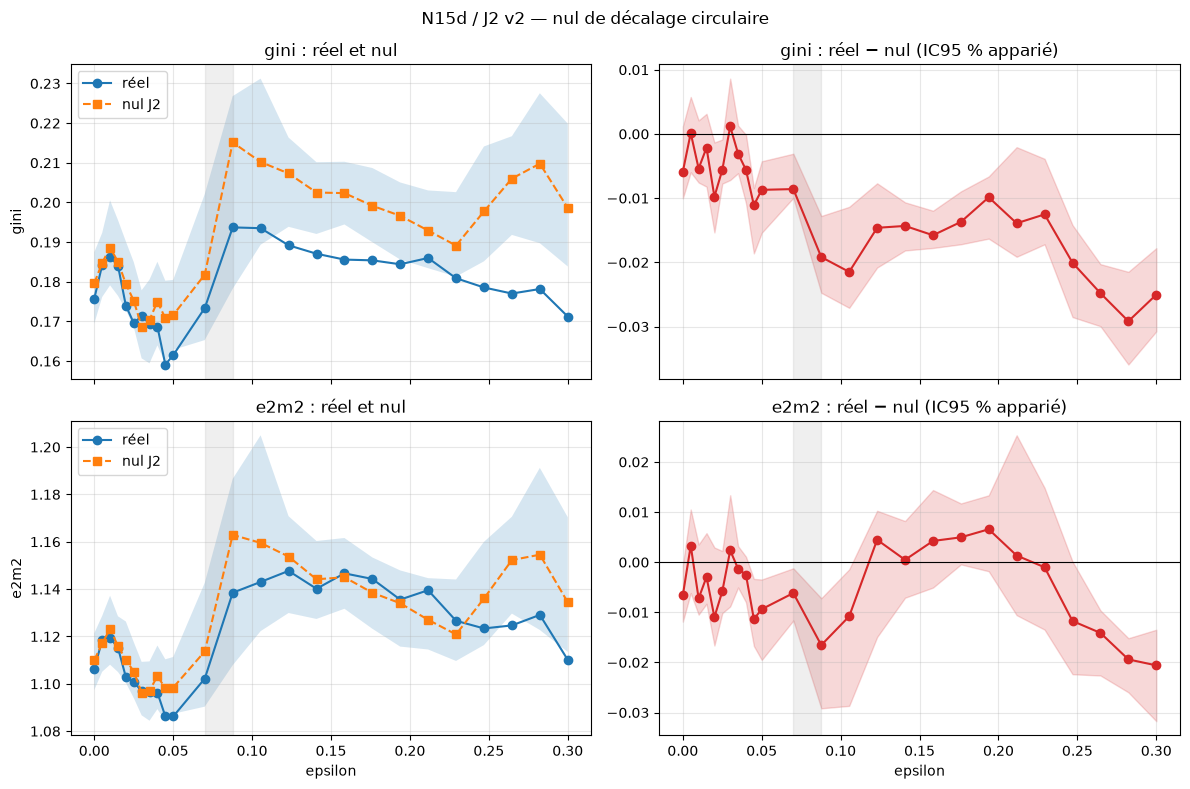

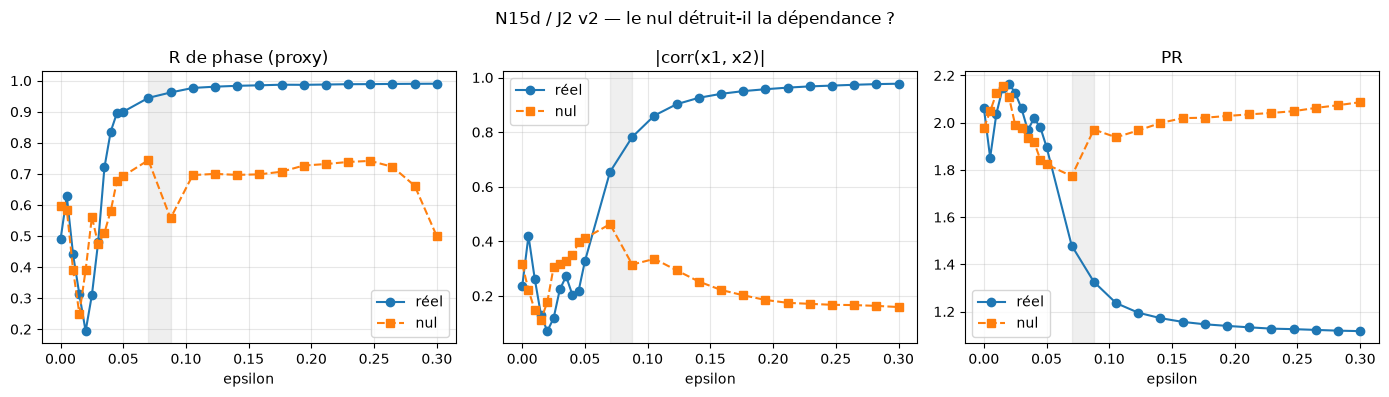

In [31]:
# -----------------------------------------------------------------------------
# N15d / J2 (v2). NUL DE DÉPENDANCE PAR DÉCALAGE CIRCULAIRE DU CANAL 2  -- avec contrôles du nul
# À placer après N15c. Aucun nouveau nuage. Remplace la version précédente.
#
# Ce qui change par rapport à la v1 :
#  1. constantes manquantes / dupliquées corrigées, fonction de lag morte supprimée ;
#  2. AUTO-CONTRÔLE : _j2_mesurer(X) sur le nuage non décalé doit reproduire ind_meta (sinon arrêt) ;
#  3. CONTRÔLE DE MANIPULATION : le nul détruit-il vraiment la dépendance ? (R de phase proxy, |corr(x1,x2)|, PR,
#     réel contre nul, à ε faible / au saut / à ε fort). Sans ça, « nul = réel » n'est pas interprétable :
#     deux oscillateurs verrouillés en fréquence gardent un déphasage quasi constant même après décalage temporel ;
#  4. plusieurs lags (J2_LAG_FRACS) au lieu d'un seul ; médiane sur les lags + dispersion entre lags ;
#  5. saut mesuré par fenêtres (moyenne après − moyenne avant), plus robuste que 2 points de grille ;
#  6. critère : PART DU SAUT attribuable à la dépendance = (réel − nul)/réel avec IC bootstrap, et décision
#     « nul explique le saut / dépendance contribue / non tranché » (à la place de |diff|/SD entre graines,
#     quasi inatteignable puisque SD et non erreur-type) ;
#  7. lignes N15d dans le CSV.
# -----------------------------------------------------------------------------
from scipy.signal import hilbert as _hilbert

J2_DIRECTION = "bi"
J2_T_REFERENCE = 0.10
J2_LAG_FRACS = np.linspace(0.20, 0.80, 6)       # lags en fraction de N (6 lags = ~5000 diagrammes ; monter à 12 si le temps le permet)
J2_BOOT = 1000
J2_WIN_BEFORE = (0.045, 0.0701)                 # fenêtres du saut (choisies APRÈS N15c, donc exploratoires)
J2_WIN_AFTER = (0.0877, 0.1250)
J2_JUMP_INTERVAL = (0.0700, 0.0877)             # saut sur 2 points, conservé en secondaire
J2_EQUIV = 0.30                                 # |part du saut attribuable à la dépendance| ≤ 30 % = « nul explique le saut »
J2_VALID_R_GAP = 0.30                           # R_proxy(réel) − R_proxy(nul) à ε fort : en dessous, nul jugé insuffisant
J2_TOL_SELFCHECK = 1e-6

def _j2_phase(x):
    return np.unwrap(np.angle(_hilbert(x - np.mean(x))))

def _j2_pr(Z):
    w = np.clip(np.linalg.eigvalsh(np.cov(Z.T)), 0, None)
    return float(w.sum() ** 2 / (w ** 2).sum())

def _j2_dep(X, m, shifts):
    """Dépendance (proxys lus dans le nuage) du réel et des nuls : R de phase, |corr(x1,x2)|, PR.
    Les colonnes 0 et m sont x(t) des deux canaux, lignes dans l'ordre du temps (vérifié par _j2_ordre)."""
    x1, x2 = X[:, 0], X[:, m]; p1, p2 = _j2_phase(x1), _j2_phase(x2)
    real = dict(R=float(abs(np.mean(np.exp(1j * (p1 - p2))))), Cx=float(abs(np.corrcoef(x1, x2)[0, 1])), pr=_j2_pr(X))
    nul = {"R": [], "Cx": [], "pr": []}
    for s in shifts:
        nul["R"].append(abs(np.mean(np.exp(1j * (p1 - np.roll(p2, int(s)))))))
        nul["Cx"].append(abs(np.corrcoef(x1, np.roll(x2, int(s)))[0, 1]))
        nul["pr"].append(_j2_pr(np.hstack((X[:, :m], np.roll(X[:, m:], int(s), axis=0)))))
    return real, {k: float(np.median(v)) for k, v in nul.items()}

def _j2_mesurer(X):
    dgm = single_linkage_h0_diagram(X)
    return {"gini": float(CHARGES["topological_gini"](dgm)), "e2m2": float(pers_energy_norm(dgm))}

def _j2_ordre(X):
    """Les lignes sont-elles dans l'ordre du temps ? (autocorrélation de x1 au lag 1 de ligne)."""
    x = X[:, 0] - X[:, 0].mean(); return float(np.dot(x[:-1], x[1:]) / np.dot(x, x))

def _j2_win(eps_g, lo_hi):
    msk = (eps_g >= lo_hi[0]) & (eps_g <= lo_hi[1])
    if msk.sum() < 2: raise RuntimeError(f"J2 : moins de 2 valeurs d'epsilon dans la fenêtre {lo_hi}.")
    return msk

def _j2_fraction_ci(real_j, diff_j, rng):
    n = len(real_j); fr = []
    for _ in range(J2_BOOT):
        p = rng.integers(0, n, n); den = np.nanmedian(real_j[p])
        if abs(den) > 1e-12: fr.append(np.nanmedian(diff_j[p]) / den)
    return np.percentile(fr, [2.5, 97.5])

def _j2_decide(ci):
    if ci[0] >= -J2_EQUIV and ci[1] <= J2_EQUIV: return "NUL EXPLIQUE LE SAUT (IC dans ±%.0f %%)" % (100 * J2_EQUIV)
    if ci[0] > 0: return "LA DÉPENDANCE CONTRIBUE (IC > 0)"
    if ci[1] < 0: return "NUL > RÉEL (IC < 0) : à examiner"
    return "NON TRANCHÉ (IC trop large)"

def run_N15d():
    eps_g = np.asarray(grille("J", "eps", var=J2_DIRECTION)); m = 3
    seeds = seeds_communes("J", var=J2_DIRECTION, eps=eps_g[0], T=J2_T_REFERENCE)
    if len(eps_g) < 3 or len(seeds) < 6: raise RuntimeError(f"J2 : grille ou graines insuffisantes (eps={len(eps_g)}, graines={len(seeds)}).")
    clouds = {}
    for a, eps in enumerate(eps_g):
        for b, seed in enumerate(seeds):
            X = get_cloud(fam="J", seed=seed, var=J2_DIRECTION, eps=eps, T=J2_T_REFERENCE, m=m)
            if X is None or X.ndim != 2 or X.shape[1] != 2 * m: raise RuntimeError(f"J2 : nuage absent ou forme inattendue (eps={eps}, seed={seed}).")
            clouds[(a, b)] = X
    N = next(iter(clouds.values())).shape[0]
    lags = np.unique(np.clip(np.round(np.asarray(J2_LAG_FRACS) * N).astype(int), 1, N - 1))

    # ---- (A) auto-contrôles : ordre temporel et reproduction de ind_meta
    ordre = [_j2_ordre(clouds[(a, 0)]) for a in (0, len(eps_g) // 2, len(eps_g) - 1)]
    print(f"[contrôle] autocorrélation de x1 au lag 1 de ligne : {', '.join(f'{o:.2f}' for o in ordre)} (≥ 0,5 attendu si les lignes suivent le temps)")
    if min(ordre) < 0.5: print("  ⚠ lignes possiblement non ordonnées dans le temps : le décalage de lignes n'est alors PAS un décalage temporel.")
    bad = 0.0
    for a in (0, len(eps_g) // 2, len(eps_g) - 1):
        for b in range(min(3, len(seeds))):
            obs = ind_meta(fam="J", seed=seeds[b], var=J2_DIRECTION, eps=eps_g[a], T=J2_T_REFERENCE, m=m)
            if obs is None: raise RuntimeError("J2 : ind_meta indisponible pour l'auto-contrôle.")
            mes = _j2_mesurer(clouds[(a, b)]); bad = max(bad, max(abs(mes[k] - obs[k]) for k in mes))
    print(f"[contrôle] écart max |_j2_mesurer(nuage) − ind_meta| = {bad:.2e}")
    if bad > J2_TOL_SELFCHECK: raise RuntimeError("J2 : _j2_mesurer ne reproduit pas ind_meta ; réel − nul serait biaisé (prétraitement différent ?).")

    # ---- (B) mesures
    keys = ("gini", "e2m2"); dkeys = ("R", "Cx", "pr")
    real = {k: np.full((len(eps_g), len(seeds)), np.nan) for k in keys}
    null = {k: np.full((len(eps_g), len(seeds), len(lags)), np.nan) for k in keys}
    dreal = {k: np.full((len(eps_g), len(seeds)), np.nan) for k in dkeys}
    dnull = {k: np.full((len(eps_g), len(seeds)), np.nan) for k in dkeys}
    for a, eps in enumerate(eps_g):
        for b, seed in enumerate(seeds):
            X = clouds[(a, b)]
            obs = ind_meta(fam="J", seed=seed, var=J2_DIRECTION, eps=eps, T=J2_T_REFERENCE, m=m)
            if obs is None: raise RuntimeError(f"J2 : indicateurs réels indisponibles (eps={eps}, seed={seed}).")
            for k in keys: real[k][a, b] = obs[k]
            for c, lag in enumerate(lags):
                mes = _j2_mesurer(np.hstack((X[:, :m], np.roll(X[:, m:], int(lag), axis=0))))
                for k in keys: null[k][a, b, c] = mes[k]
            r, n_ = _j2_dep(X, m, lags)
            for k in dkeys: dreal[k][a, b] = r[k]; dnull[k][a, b] = n_[k]
    null_seed = {k: np.nanmedian(null[k], axis=2) for k in keys}
    paired = {k: real[k] - null_seed[k] for k in keys}
    print(f"\nJ2 v2 [{J2_DIRECTION}] : {len(eps_g)} epsilon, {len(seeds)} graines, N={N}, lags={[int(l) for l in lags]}")
    spread = {k: float(np.nanmedian(np.nanstd(null[k], axis=2, ddof=1))) for k in keys}
    print("dispersion du nul entre lags (médiane sur ε, graines) : " + " ; ".join(f"{k}={spread[k]:.4g}" for k in keys)
          + "   (à comparer au saut réel ci-dessous)")

    # ---- (C) le nul détruit-il la dépendance ? (manipulation check)
    print("\n=== Contrôle de manipulation : réel / nul (médianes sur graines) ===")
    idx = {"ε min": 0, "saut (bas)": int(np.argmin(abs(eps_g - J2_JUMP_INTERVAL[0]))), "saut (haut)": int(np.argmin(abs(eps_g - J2_JUMP_INTERVAL[1]))), "ε max": len(eps_g) - 1}
    print(f"{'point':11s} {'ε':>7s} | " + " | ".join(f"{k:>16s}" for k in ("R_proxy", "|corr(x1,x2)|", "PR")))
    for name, a in idx.items():
        cells = [f"{np.nanmedian(dreal[k][a]):6.3f}/{np.nanmedian(dnull[k][a]):6.3f}" for k in dkeys]
        print(f"{name:11s} {eps_g[a]:7.4f} | " + " | ".join(f"{c:>16s}" for c in cells))
    gap_R = float(np.nanmedian(dreal["R"][-1]) - np.nanmedian(dnull["R"][-1]))
    valid = gap_R >= J2_VALID_R_GAP
    print(f"R_proxy(réel) − R_proxy(nul) à ε max = {gap_R:+.3f}  ->  NUL {'VALIDE pour la phase' if valid else 'INSUFFISANT : le décalage conserve le verrouillage de phase, J2 ne peut pas conclure'}")

    # ---- (D) saut réel contre nul
    mb, ma = _j2_win(eps_g, J2_WIN_BEFORE), _j2_win(eps_g, J2_WIN_AFTER)
    i0 = idx["saut (bas)"]; i1 = idx["saut (haut)"]
    rng = np.random.default_rng(1517); res = {}
    print(f"\n=== Saut ({J2_WIN_BEFORE[0]:.3f}–{J2_WIN_BEFORE[1]:.3f}) → ({J2_WIN_AFTER[0]:.3f}–{J2_WIN_AFTER[1]:.3f}) ; fenêtres choisies après N15c : exploratoire ===")
    for k in keys:
        jr = np.nanmean(real[k][ma], axis=0) - np.nanmean(real[k][mb], axis=0)
        jn = np.nanmean(null_seed[k][ma], axis=0) - np.nanmean(null_seed[k][mb], axis=0)
        jd = jr - jn; ci_d = np.nanpercentile([np.nanmedian(jd[rng.integers(0, len(jd), len(jd))]) for _ in range(J2_BOOT)], [2.5, 97.5])
        ci_r = np.nanpercentile([np.nanmedian(jr[rng.integers(0, len(jr), len(jr))]) for _ in range(J2_BOOT)], [2.5, 97.5])
        ci_f = _j2_fraction_ci(jr, jd, rng)
        verdict = _j2_decide(ci_f) if not (ci_r[0] <= 0 <= ci_r[1]) else "SAUT RÉEL NON DISTINGUABLE DE 0 : part non définie"
        print(f"{k:5s} : IC95 du saut réel [{ci_r[0]:+.4g} ; {ci_r[1]:+.4g}]")
        j2r = np.nanmedian(real[k][i1] - real[k][i0]); j2n = np.nanmedian(null_seed[k][i1] - null_seed[k][i0])
        print(f"{k:5s} : saut réel {np.nanmedian(jr):+.4g} ; saut nul {np.nanmedian(jn):+.4g} ; réel − nul {np.nanmedian(jd):+.4g} IC95 [{ci_d[0]:+.4g} ; {ci_d[1]:+.4g}]")
        print(f"        part attribuable à la dépendance = {np.nanmedian(jd) / np.nanmedian(jr):+.2f} IC95 [{ci_f[0]:+.2f} ; {ci_f[1]:+.2f}]  ->  {verdict}")
        print(f"        (secondaire, 2 points [{eps_g[i0]:.4f}, {eps_g[i1]:.4f}] : réel {j2r:+.4g} ; nul {j2n:+.4g})")
        add_row(test="N15d", famille="J", variante=J2_DIRECTION, param="J2_saut_fenetres", charge=k, T=J2_T_REFERENCE, m=m, seed="ALL",
                valeur_mediane=float(np.nanmedian(jd)), n_samples=len(seeds),
                note=f"IC95=[{ci_d[0]:.4g}; {ci_d[1]:.4g}] ; part={np.nanmedian(jd)/np.nanmedian(jr):.2f} IC95=[{ci_f[0]:.2f}; {ci_f[1]:.2f}] ; {verdict} ; nul_valide_phase={valid}")
        res[k] = dict(saut_reel=float(np.nanmedian(jr)), saut_nul=float(np.nanmedian(jn)), diff=float(np.nanmedian(jd)), ci_diff=tuple(ci_d), part_ci=tuple(ci_f), verdict=verdict)
    print("\nLecture : si le nul est VALIDE et que « nul explique le saut », le saut H0 vient des marginales (chaque Rössler change avec ε), pas de la dépendance. "
          "Si le nul est INSUFFISANT, ce résultat ne dit rien. « NON TRANCHÉ » : l'IC autorise les deux lectures.")

    # ---- (E) figures
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex="col")
    for row, k in enumerate(keys):
        flat = null[k].reshape(len(eps_g), -1); lo, hi = np.nanpercentile(flat, [25, 75], axis=1)
        ax = axes[row, 0]; ax.plot(eps_g, np.nanmedian(real[k], axis=1), "o-", label="réel"); ax.plot(eps_g, np.nanmedian(flat, axis=1), "s--", label="nul J2")
        ax.fill_between(eps_g, lo, hi, alpha=0.18); ax.axvspan(*J2_JUMP_INTERVAL, color="gray", alpha=0.12); ax.set_title(f"{k} : réel et nul"); ax.set_ylabel(k); ax.grid(alpha=0.3); ax.legend()
        ax = axes[row, 1]; ci = np.array([np.nanpercentile([np.nanmedian(paired[k][a][rng.integers(0, len(seeds), len(seeds))]) for _ in range(300)], [2.5, 97.5]) for a in range(len(eps_g))])
        ax.plot(eps_g, np.nanmedian(paired[k], axis=1), "o-", color="tab:red"); ax.fill_between(eps_g, ci[:, 0], ci[:, 1], alpha=0.18, color="tab:red")
        ax.axhline(0, color="k", lw=0.8); ax.axvspan(*J2_JUMP_INTERVAL, color="gray", alpha=0.12); ax.set_title(f"{k} : réel − nul (IC95 % apparié)"); ax.grid(alpha=0.3)
    axes[-1, 0].set_xlabel("epsilon"); axes[-1, 1].set_xlabel("epsilon"); plt.suptitle("N15d / J2 v2 — nul de décalage circulaire"); plt.tight_layout(); savefig("N15d_J2_decalage_circulaire.png"); plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, k, ttl in zip(axes, dkeys, ("R de phase (proxy)", "|corr(x1, x2)|", "PR")):
        ax.plot(eps_g, np.nanmedian(dreal[k], axis=1), "o-", label="réel"); ax.plot(eps_g, np.nanmedian(dnull[k], axis=1), "s--", label="nul")
        ax.axvspan(*J2_JUMP_INTERVAL, color="gray", alpha=0.12); ax.set_title(ttl); ax.set_xlabel("epsilon"); ax.grid(alpha=0.3); ax.legend()
    plt.suptitle("N15d / J2 v2 — le nul détruit-il la dépendance ?"); plt.tight_layout(); savefig("N15d_J2_controle_nul.png"); plt.show()
    return dict(eps=eps_g, seeds=seeds, lags=lags, real=real, null=null, paired=paired, dreal=dreal, dnull=dnull, nul_valide_phase=valid, saut=res)

n15d = safe_run("N15d / J2 v2", run_N15d)


=== N15e [bi] : saut relatif (0.045–0.070) → (0.088–0.125) et landmark de montée max ===
indic courbe     |         saut relatif médian [IC95] |     landmark montée [IC95]
gini  6D réel    |   +0.137 [+0.098 ; +0.192]         |  0.0775 [0.0550 ; 0.0800]
gini  canal 1    |   +0.082 [+0.045 ; +0.089]         |  0.0775 [0.0400 ; 0.0800]
gini  canal 2    |   +0.109 [+0.086 ; +0.137]         |  0.0775 [0.0550 ; 0.0975]
gini  6D nul J2  |   +0.186 [+0.130 ; +0.244]         |  0.0775 [0.0683 ; 0.0800]
      gini : saut(canal 1) / saut(6D réel) = +0.60 [+0.35 ; +0.87] ; saut présent sur le canal seul : oui
      gini : saut(canal 2) / saut(6D réel) = +0.80 [+0.61 ; +1.08] ; saut présent sur le canal seul : oui
      -> gini : saut présent sur chaque canal seul : effet de marginales (couplage → chaque oscillateur), non spécifique à l'appariement

e2m2  6D réel    |   +0.046 [+0.027 ; +0.056]         |  0.0775 [0.0600 ; 0.1150]
e2m2  canal 1    |   +0.051 [+0.042 ; +0.063]         |  0.0800 [0.

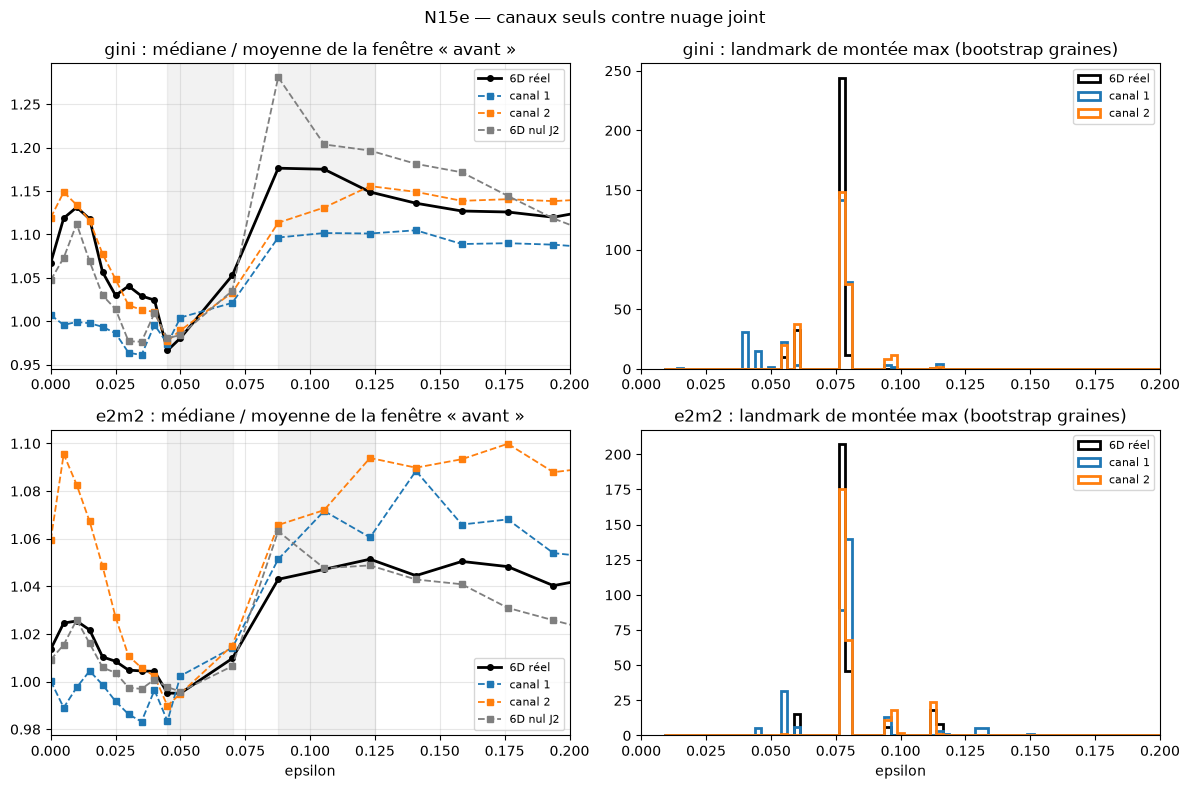

In [32]:
# -----------------------------------------------------------------------------
# N15e. CANAUX SEULS : le saut H0 de gini / e2m2 (ε ≈ 0,07 à 0,0877, bi) existe-t-il déjà dans chaque oscillateur ?
# À placer après N15d (utilise n15d["real"] et n15d["null"] s'il existe). Aucun nouveau nuage.
#
# On mesure gini et e2m2 sur  X[:, :m] (canal 1)  et  X[:, m:2m] (canal 2),  puis on compare, sans nuage joint :
#   saut RELATIF (après − avant)/avant sur les mêmes fenêtres que J2, et position du landmark de plus forte montée.
# Les niveaux ne sont pas comparables entre 3D et 6D (gini dépend de la dimension) : on compare des sauts relatifs
# et des positions, jamais des valeurs absolues.
# Lecture : un saut présent sur chaque canal seul, de taille comparable au 6D, = effet des marginales
# (induit par le couplage sur chaque oscillateur, mais non spécifique à l'appariement entre canaux).
# -----------------------------------------------------------------------------
E_DIRECTION = "bi"
E_T = 0.10
E_BOOT = 1000
E_WIN_BEFORE = (0.045, 0.0701)          # mêmes fenêtres que J2 (choisies après N15c : exploratoire)
E_WIN_AFTER = (0.0877, 0.1250)
E_W_SLOPE = 0.02                        # fenêtre de pente du landmark, comme N15c
E_C_GRID = np.arange(0.010, 0.2001, 0.0025)

def _e_mesurer(X):
    dgm = single_linkage_h0_diagram(X)
    return {"gini": float(CHARGES["topological_gini"](dgm)), "e2m2": float(pers_energy_norm(dgm))}

def _e_win(eps_g, lo_hi):
    msk = (eps_g >= lo_hi[0]) & (eps_g <= lo_hi[1])
    if msk.sum() < 2: raise RuntimeError(f"N15e : moins de 2 valeurs d'epsilon dans la fenêtre {lo_hi}.")
    return msk

def _e_rel_jump(M, mb, ma):
    """Saut relatif par graine : (moyenne après − moyenne avant) / moyenne avant."""
    before = np.nanmean(M[mb], axis=0); after = np.nanmean(M[ma], axis=0)
    return (after - before) / before

def _e_landmark(eps_g, y):
    h = E_W_SLOPE / 2
    sl = (np.interp(E_C_GRID + h, eps_g, y) - np.interp(E_C_GRID - h, eps_g, y)) / E_W_SLOPE
    return float(E_C_GRID[int(np.argmax(sl))])

def _e_ci(x, rng, stat=np.nanmedian):
    x = np.asarray(x, float); n = len(x)
    return np.nanpercentile([stat(x[rng.integers(0, n, n)]) for _ in range(E_BOOT)], [2.5, 97.5])

def run_N15e():
    eps_g = np.asarray(grille("J", "eps", var=E_DIRECTION)); m = 3
    seeds = seeds_communes("J", var=E_DIRECTION, eps=eps_g[0], T=E_T)
    if len(eps_g) < 3 or len(seeds) < 6: raise RuntimeError(f"N15e : grille ou graines insuffisantes (eps={len(eps_g)}, graines={len(seeds)}).")
    keys = ("gini", "e2m2")
    curves = {c: {k: np.full((len(eps_g), len(seeds)), np.nan) for k in keys} for c in ("6D réel", "canal 1", "canal 2")}
    for a, eps in enumerate(eps_g):
        for b, seed in enumerate(seeds):
            X = get_cloud(fam="J", seed=seed, var=E_DIRECTION, eps=eps, T=E_T, m=m)
            if X is None or X.ndim != 2 or X.shape[1] != 2 * m: raise RuntimeError(f"N15e : nuage absent ou forme inattendue (eps={eps}, seed={seed}).")
            obs = ind_meta(fam="J", seed=seed, var=E_DIRECTION, eps=eps, T=E_T, m=m)
            if obs is None: raise RuntimeError(f"N15e : indicateurs réels indisponibles (eps={eps}, seed={seed}).")
            m1, m2 = _e_mesurer(X[:, :m]), _e_mesurer(X[:, m:2 * m])
            for k in keys:
                curves["6D réel"][k][a, b] = obs[k]; curves["canal 1"][k][a, b] = m1[k]; curves["canal 2"][k][a, b] = m2[k]
    j2 = globals().get("n15d")
    if isinstance(j2, dict) and "null" in j2 and np.shape(j2["null"]["gini"])[:2] == (len(eps_g), len(seeds)):
        curves["6D nul J2"] = {k: np.nanmedian(j2["null"][k], axis=2) for k in keys}
    else:
        print("[info] n15d absent ou de forme différente : la courbe « 6D nul J2 » est omise.")
    mb, ma = _e_win(eps_g, E_WIN_BEFORE), _e_win(eps_g, E_WIN_AFTER)
    rng = np.random.default_rng(1518); res = {}
    print(f"\n=== N15e [{E_DIRECTION}] : saut relatif ({E_WIN_BEFORE[0]:.3f}–{E_WIN_BEFORE[1]:.3f}) → ({E_WIN_AFTER[0]:.3f}–{E_WIN_AFTER[1]:.3f}) et landmark de montée max ===")
    print(f"{'indic':5s} {'courbe':10s} | {'saut relatif médian [IC95]':>34s} | {'landmark montée [IC95]':>26s}")
    for k in keys:
        ref_rel = _e_rel_jump(curves["6D réel"][k], mb, ma)
        for c, D in curves.items():
            rel = _e_rel_jump(D[k], mb, ma); ci = _e_ci(rel, rng)
            med = np.nanmedian(D[k], axis=1); lm = _e_landmark(eps_g, med)
            lms = [_e_landmark(eps_g, np.nanmedian(D[k][:, rng.integers(0, D[k].shape[1], D[k].shape[1])], axis=1)) for _ in range(min(E_BOOT, 500))]
            lci = np.percentile(lms, [2.5, 97.5])
            print(f"{k:5s} {c:10s} | {np.nanmedian(rel):+8.3f} [{ci[0]:+.3f} ; {ci[1]:+.3f}]{'':8s} | {lm:7.4f} [{lci[0]:.4f} ; {lci[1]:.4f}]")
            add_row(test="N15e", famille="J", variante=E_DIRECTION, param="J_canal_saut_rel", charge=f"{k}|{c}", T=E_T, m=m, seed="ALL",
                    valeur_mediane=float(np.nanmedian(rel)), n_samples=len(seeds),
                    note=f"IC95=[{ci[0]:.4f}; {ci[1]:.4f}] ; landmark={lm:.4f} IC95=[{lci[0]:.4f}; {lci[1]:.4f}]")
            res[(k, c)] = dict(rel=float(np.nanmedian(rel)), ci=tuple(ci), landmark=lm, landmark_ci=tuple(lci))
        # rapport saut canal / saut 6D réel (bootstrap apparié sur les graines)
        for c in ("canal 1", "canal 2"):
            rel = _e_rel_jump(curves[c][k], mb, ma); n = len(rel); rr = []
            for _ in range(E_BOOT):
                p = rng.integers(0, n, n); den = np.nanmedian(ref_rel[p])
                if abs(den) > 1e-12: rr.append(np.nanmedian(rel[p]) / den)
            rci = np.percentile(rr, [2.5, 97.5]); present = res[(k, c)]["ci"][0] > 0
            print(f"      {k} : saut({c}) / saut(6D réel) = {np.nanmedian(rel) / np.nanmedian(ref_rel):+.2f} [{rci[0]:+.2f} ; {rci[1]:+.2f}] ; saut présent sur le canal seul : {'oui' if present else 'non'}")
            res[(k, c)]["ratio_ci"] = tuple(rci); res[(k, c)]["present"] = bool(present)
        pres = [res[(k, c)]["present"] for c in ("canal 1", "canal 2")]
        if all(pres): msg = "saut présent sur chaque canal seul : effet de marginales (couplage → chaque oscillateur), non spécifique à l'appariement"
        elif any(pres): msg = "saut présent sur un seul canal : asymétrie du désaccord, à examiner canal par canal"
        else: msg = "saut absent des canaux seuls : propre au nuage joint ; alors le nul J2 qui le reproduit est à réexaminer (nul imparfait vers ε = 0,07 ?)"
        print(f"      -> {k} : {msg}\n")
    # ---- figure : courbes relatives et landmarks
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    col = {"6D réel": "k", "canal 1": "tab:blue", "canal 2": "tab:orange", "6D nul J2": "tab:gray"}
    for row, k in enumerate(keys):
        ax = axes[row, 0]
        for c, D in curves.items():
            med = np.nanmedian(D[k], axis=1); base = np.nanmean(med[mb])
            ax.plot(eps_g, med / base, "o-" if c == "6D réel" else "s--", color=col[c], lw=2 if c == "6D réel" else 1.3, ms=4, label=c)
        ax.axvspan(*E_WIN_BEFORE, color="gray", alpha=0.10); ax.axvspan(*E_WIN_AFTER, color="gray", alpha=0.10)
        ax.set_xlim(0, 0.2); ax.set_title(f"{k} : médiane / moyenne de la fenêtre « avant »"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
        ax = axes[row, 1]
        for c in ("6D réel", "canal 1", "canal 2"):
            D = curves[c][k]; n = D.shape[1]
            lms = [_e_landmark(eps_g, np.nanmedian(D[:, rng.integers(0, n, n)], axis=1)) for _ in range(300)]
            ax.hist(lms, bins=np.append(E_C_GRID - 0.00125, E_C_GRID[-1] + 0.00125), histtype="step", lw=2, color=col[c], label=c)
        ax.set_xlim(0, 0.2); ax.set_title(f"{k} : landmark de montée max (bootstrap graines)"); ax.legend(fontsize=8)
    axes[-1, 0].set_xlabel("epsilon"); axes[-1, 1].set_xlabel("epsilon")
    plt.suptitle("N15e — canaux seuls contre nuage joint"); plt.tight_layout(); savefig("N15e_canaux_seuls.png"); plt.show()
    return dict(eps=eps_g, seeds=seeds, curves=curves, res=res)

n15e = safe_run("N15e", run_N15e)

## N16 — Dépendance au-delà du linéaire (appui à H1)
**Nuages attendus** : famille **F** (comme N11). Pour chaque nuage : information mutuelle KSG entre les deux canaux moins l'information mutuelle gaussienne à même ρ (`dep_nl` ≥ 0 si la dépendance dépasse le linéaire). Question : `dep_nl` explique-t-il l'indicateur **au-delà** du PR (test F emboîté) ?

In [33]:
# -----------------------------------------------------------------------------
# N16. DÉPENDANCE NON LINÉAIRE ET INDICATEURS  (nuages : F)
# -----------------------------------------------------------------------------
_NL_CACHE = {}
def dep_nl_meta(**kw):
    k = _key2(meta2(**kw))
    if k not in _NL_CACHE:
        X = get_cloud(**kw); _NL_CACHE[k] = None if X is None else dep_nonlineaire(X, kw.get("m", 3))
    return _NL_CACHE[k]

def run_N16():
    rows = []
    for d in INDEX2:
        if d["famille"] == "F" and d["variante"] == "":
            r = ind_meta(fam="F", seed=d["seed"], g=d["g"], T=d["T"]); nl = dep_nl_meta(fam="F", seed=d["seed"], g=d["g"], T=d["T"])
            if r is not None and nl is not None and np.isfinite(nl): rows.append(dict(r, g=d["g"], T=d["T"], nl=nl))
    if len(rows) < 50: raise RuntimeError("Famille F absente ou trop petite -> générer F (04c)")
    nl = np.array([r["nl"] for r in rows]); pr = np.array([r["pr"] for r in rows]); print(f"N16 : {len(rows)} nuages ; dépendance non linéaire médiane = {np.median(nl):.4f} nats")
    print(f"{'indicateur':10s} {'Sp(nl)':>8s} {'R²adj PR':>9s} {'R²adj +nl':>10s} {'F':>8s} {'p':>9s}")
    for ind in ("gini", "e2m2", "twonn"):
        y = np.array([r[ind] for r in rows]); ok = np.isfinite(y) & np.isfinite(pr) & np.isfinite(nl)
        (r0, a0), (r1, a1), F, p = nested_F(y[ok], np.column_stack([pr, pr ** 2])[ok], np.column_stack([pr, pr ** 2, nl])[ok])
        sp = stats.spearmanr(y[ok], nl[ok])[0]
        print(f"{ind:10s} {sp:8.3f} {a0:9.3f} {a1:10.3f} {F:8.2f} {p:9.2g}")
        add_row(test="N16", famille="F", param="dep_nl", charge=ind, seed="ALL", valeur_mediane=sp, n_samples=int(ok.sum()),
                note=f"Spearman={sp:.3f} ; R2adj PR={a0:.3f} ; R2adj +dep_nl={a1:.3f} ; F={F:.2f} ; p={p:.2g} (pseudo-réplication : indicatif)")
    return rows

n16 = safe_run("N16", run_N16)

N16 : 1540 nuages ; dépendance non linéaire médiane = 0.0186 nats
indicateur   Sp(nl)  R²adj PR  R²adj +nl        F         p
gini          0.108     0.069      0.071     4.75      0.03
e2m2          0.094     0.098      0.097     0.03      0.85
twonn        -0.280     0.154      0.193    75.11         0


## N17 — Analogue visqueux : couche limite et covariance d'échelle (H5)
**Nuages attendus** : famille **K** : `X_famK_tv{tv}_ds{ds}_T{T:.2f}_m3_seed{s}.npy` — canal 1 = pilote (Rössler, ralenti ×`ds`), canal 2 = « eau » = filtre passe-bas exponentiel du pilote de constante τν échantillons (τν = 0 : canaux identiques à un bruit près), τν ∈ {0, 5, 10, 20, 40, 80, 160, 320} (pas ×2), T ∈ {0,1 ; 0,4}. Le filtre est le premier mode de l'entraînement visqueux (constante ∝ R²/ν) : c'est le seul endroit où « viscosité » a un sens littéral.
**Mesures** : indicateurs primaires, TwoNN, PR et **distance de bottleneck marginale** entre les diagrammes H0 des deux canaux (via `BOTTLENECK_FN` de la v2 si disponible, sinon repli : écart maximal des morts triées), normalisée.
**H5** : l'indice a un extremum **intérieur** en τν et celui-ci se déplace de **+1 pas (×2)** quand le pilote est ralenti ×2.

N17 : tv=[0, 5, 10, 20, 40, 80, 160, 320] ; ds=[1, 2] ; T=[0.1, 0.4]

indic      T  i*(ds=1) i*(ds=2)  intérieur  P(décalage=+1)
gini     0.1         7        0  False      0.00
gini     0.4         1        4  True       0.11
e2m2     0.1         4        0  False      0.03
e2m2     0.4         0        4  False      0.04
twonn    0.1         6        1  True       0.03
twonn    0.4         1        0  False      0.05
dB       0.1         0        6  False      0.01
dB       0.4         0        4  False      0.04
   ⇒ H5 : NON SOUTENUE — cas (indicateur primaire, T) avec P(+1, intérieur) ≥ 0,6 : aucun


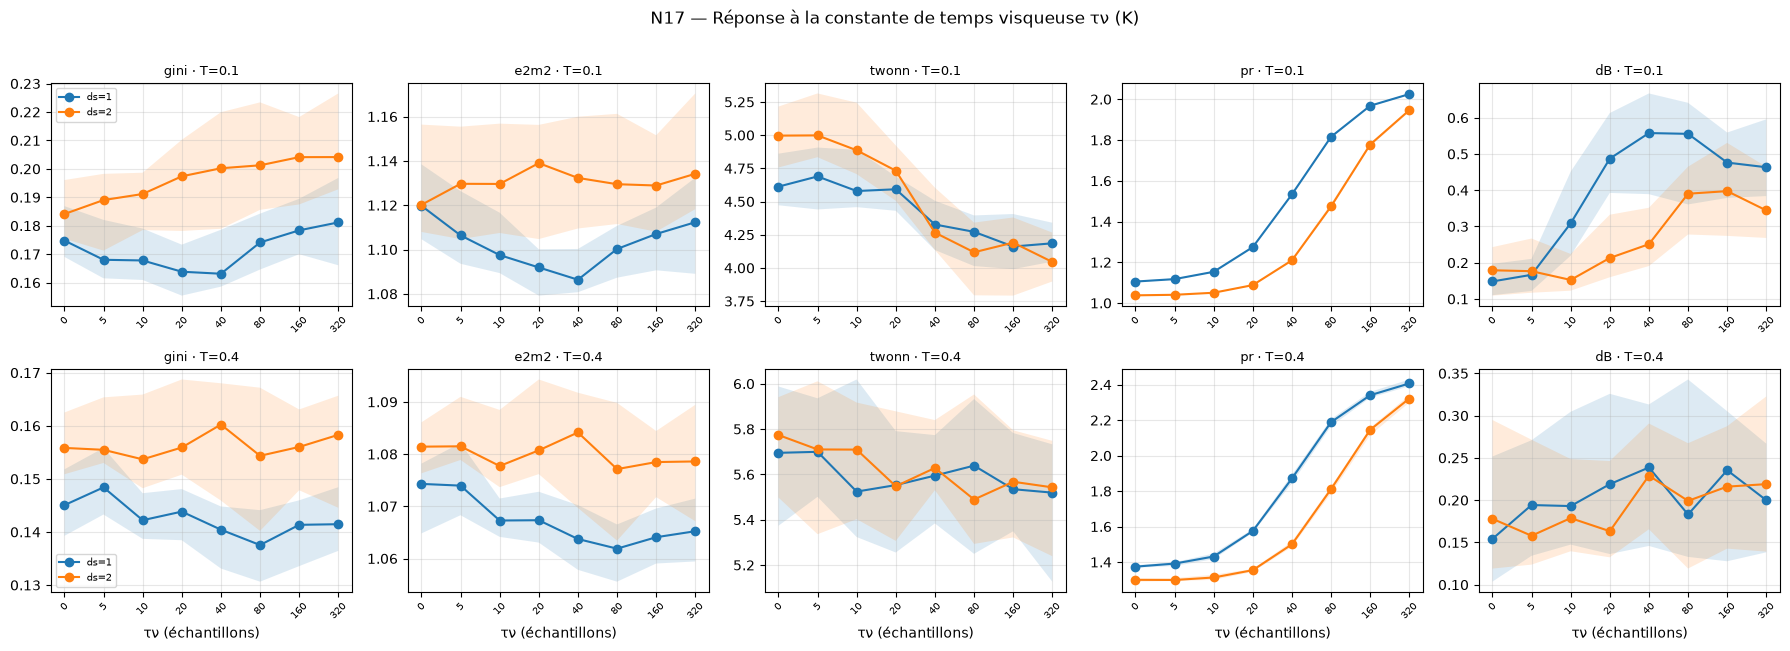

In [34]:
# -----------------------------------------------------------------------------
# N17. ANALOGUE VISQUEUX — covariance d'échelle  (nuages : K)
# -----------------------------------------------------------------------------
def bottleneck_marginal(X, m=3):
    d1 = single_linkage_h0_diagram(X[:, :m]); d2 = single_linkage_h0_diagram(X[:, m:2 * m])
    fn = globals().get("BOTTLENECK_FN"); val = None
    if fn is not None:
        try: val = float(fn(d1, d2))
        except Exception: val = None
    a, b = np.sort(lifetimes(d1)), np.sort(lifetimes(d2))
    if val is None: n = min(len(a), len(b)); val = float(np.max(np.abs(a[-n:] - b[-n:])))
    return val / (0.5 * (a.max() + b.max()))

def run_N17():
    TVS = grille("K", "tv", ds=1, T=0.1)
    if len(TVS) < 4: raise RuntimeError("Famille K absente -> générer K (04c)")
    Ts = grille("K", "T"); DSs = grille("K", "ds"); tvs = np.array(TVS, float); print(f"N17 : tv={TVS} ; ds={DSs} ; T={Ts}")
    keys = ("gini", "e2m2", "twonn", "pr", "dB")
    seeds = [s for s in SEEDS if all(get_cloud(fam="K", seed=s, tv=tv, ds=ds, T=T) is not None for tv in TVS for ds in DSs for T in Ts)]
    D = {(ds, T): {k: np.full((len(TVS), len(seeds)), np.nan) for k in keys} for ds in DSs for T in Ts}
    for ds in DSs:
        for T in Ts:
            for a, tv in enumerate(TVS):
                for b, s in enumerate(seeds):
                    X = get_cloud(fam="K", seed=s, tv=tv, ds=ds, T=T); r = ind_meta(fam="K", seed=s, tv=tv, ds=ds, T=T)
                    for k in ("gini", "e2m2", "twonn", "pr"): D[(ds, T)][k][a, b] = r[k]
                    D[(ds, T)]["dB"][a, b] = bottleneck_marginal(X)
                for k in keys:
                    add_row(test="N17", famille="K", variante=f"ds={ds}", param="tv", param_value=tv, charge=k, T=T, m=3, seed="ALL",
                            valeur_mediane=float(np.nanmedian(D[(ds, T)][k][a])), n_samples=len(seeds))
    def istar(M):
        y = np.nanmedian(M, axis=1); return int(np.nanargmax(np.abs(y - np.nanmedian(y))))
    h5 = {}; print(f"\n{'indic':7s} {'T':>4s}  i*(ds=1) i*(ds=2)  intérieur  P(décalage=+1)")
    if len(DSs) >= 2:
        d1, d2 = DSs[0], DSs[1]; rng = np.random.default_rng(17)
        for k in ("gini", "e2m2", "twonn", "dB"):
            for T in Ts:
                i1, i2 = istar(D[(d1, T)][k]), istar(D[(d2, T)][k]); inter = 0 < i1 < len(TVS) - 1 and 0 < i2 < len(TVS) - 1
                shifts, ints = [], []
                for _ in range(N_BOOT_FIT):
                    pick = rng.integers(0, len(seeds), len(seeds)); a1, a2 = istar(D[(d1, T)][k][:, pick]), istar(D[(d2, T)][k][:, pick])
                    shifts.append(a2 - a1); ints.append(0 < a1 < len(TVS) - 1 and 0 < a2 < len(TVS) - 1)
                p_shift = float(np.mean([(s_ == 1) and i_ for s_, i_ in zip(shifts, ints)])); h5[(k, T)] = (i1, i2, inter, p_shift)
                print(f"{k:7s} {T:4.1f}  {i1:8d} {i2:8d}  {str(inter):9s}  {p_shift:.2f}")
                add_row(test="N17", famille="K", param="decalage_extremum", charge=k, T=T, seed="ALL", valeur_mediane=float(i2 - i1),
                        note=f"i*(ds={d1})={i1} ; i*(ds={d2})={i2} ; interieur={inter} ; P(decalage=+1 & interieur)={p_shift:.2f}")
        ok = [(k, T) for (k, T), v in h5.items() if k in PRIMAIRES and v[3] >= 0.60]
        verdict("H5", "SOUTENUE" if ok else "NON SOUTENUE", f"cas (indicateur primaire, T) avec P(+1, intérieur) ≥ 0,6 : {ok if ok else 'aucun'}")
    else:
        print("⚠️ une seule vitesse de pilote : test de covariance d'échelle impossible")
    # ---- figure
    fig, axes = plt.subplots(len(Ts), len(keys), figsize=(3.6 * len(keys), 3.2 * len(Ts)), squeeze=False)
    for r_i, T in enumerate(Ts):
        for c_i, k in enumerate(keys):
            ax = axes[r_i, c_i]
            for ds in DSs:
                M = D[(ds, T)][k]; med = np.nanmedian(M, axis=1); q1, q3 = np.nanpercentile(M, 25, axis=1), np.nanpercentile(M, 75, axis=1)
                ax.plot(range(len(TVS)), med, marker="o", label=f"ds={ds}"); ax.fill_between(range(len(TVS)), q1, q3, alpha=0.15)
            ax.set_xticks(range(len(TVS))); ax.set_xticklabels([str(t) for t in TVS], fontsize=7, rotation=45); ax.set_title(f"{k} · T={T}", fontsize=9); ax.grid(True, alpha=0.3)
            if r_i == len(Ts) - 1: ax.set_xlabel("τν (échantillons)")
            if c_i == 0: ax.legend(fontsize=7)
    plt.suptitle("N17 — Réponse à la constante de temps visqueuse τν (K)", y=1.01); plt.tight_layout(); savefig("N17_analogue_visqueux.png"); plt.show()
    return D

n17 = safe_run("N17", run_N17)

## Verdicts pré-enregistrés et export
Les verdicts appliquent les règles écrites dans `PREREG` **avant** les résultats. « NON DÉMONTRÉE » / « NON SOUTENUE » signifie que le protocole n'a pas établi l'hypothèse, pas qu'elle est fausse. Un verdict dépend de la puissance (nombre de graines) : avec peu de graines, lire les IC avant le verdict.

In [35]:
# -----------------------------------------------------------------------------
# VERDICTS + EXPORT CSV (indépendant de l'export de la v2) + journal d'erreurs
# -----------------------------------------------------------------------------
print("=== VERDICTS (règles fixées avant les résultats) ===")
for h, rule in PREREG.items():
    st, det = VERDICT.get(h, ("NON ÉVALUÉ", "test non exécuté (famille absente ?)"))
    print(f"{h} : {st}\n     règle   : {rule}\n     mesures : {det}\n")
    add_row(test="VERDICT", param=h, regime=st, note=det[:400])

_TESTS = {"N11", "N12", "N13", "N14", "N15", "N16", "N17", "VERDICT"}
csv_path2 = os.path.join(BASE_DIR, "noether_surphin_synthese_N11_N17.csv")
with open(csv_path2, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=CSV_FIELDS); w.writeheader()
    for row in ROWS:
        if row["test"] in _TESTS: w.writerow(row)
print(f"Export : {csv_path2}  ({sum(1 for r in ROWS if r['test'] in _TESTS)} lignes)")
print("\n=== Journal d'erreurs (N11–N17) ===")
_err = [e for e in ERRORS if str(e[0]).startswith("N1") and e[0][:3] in {"N11", "N12", "N13", "N14", "N15", "N16", "N17"}]
print("aucune erreur" if not _err else "\n".join(f" - {a}: {b}" for a, b in _err))

=== VERDICTS (règles fixées avant les résultats) ===
H1 : SOUTENUE
     règle   : L'indice lit une information de couplage au-delà de la covariance : d(g) = (vrai − nul covariance)(g) − (vrai − nul covariance)(g=0), apparié par graine ; SOUTENUE si ≥ 3 valeurs de g>0 ont p de Holm < 0,05 avec un signe constant, sur un indicateur primaire. (N12, appui N16)
     mesures : gini: 4 g significatifs (Holm), signe constant=True; e2m2: 2 g significatifs (Holm), signe constant=False

H2 : SOUTENUE
     règle   : Le gini mesure « variété contre bruit » : l'écart (vrai − nul covariance), sans hypothèse de signe, a un IC excluant 0 à T=0,1 et une amplitude au moins deux fois plus faible à T=0,8. (N12)
     mesures : écart gini vrai−cov : T=0.1 médiane=-0.0335 IC=[-0.03644; -0.03021] ; T=0.8 médiane=-0.0089 IC=[-0.01064; -0.006992] ; rapport |T bas|/|T haut|=3.8

H3 : SOUTENUE
     règle   : Il existe un minimum (« obliquité ») : modèle non monotone préféré (ΔAIC > 10), convexe, argmin intérieur (I

Démarrage du balayage Kramers-Topologique (35 graines par T)...
  T = 0.15 ... tau_K = 72203.4, Pers_Max_med = 0.9207, IQR = [0.6788, 1.0169]
  T = 0.20 ... tau_K =  6689.3, Pers_Max_med = 0.6509, IQR = [0.4030, 0.7890]
  T = 0.25 ... tau_K =  1688.2, Pers_Max_med = 0.4167, IQR = [0.3272, 0.5902]
  T = 0.30 ... tau_K =   697.2, Pers_Max_med = 0.3069, IQR = [0.2568, 0.4022]
  T = 0.35 ... tau_K =   379.7, Pers_Max_med = 0.3007, IQR = [0.2304, 0.3602]
  T = 0.40 ... tau_K =   245.0, Pers_Max_med = 0.2681, IQR = [0.2122, 0.3276]

🎯 CORRÉLATION LOG-LOG (Pearson) : 0.9866
✅ VERDICT : Corrélation forte. La topologie est un proxy valide de la métastabilité.

✅ Analyse terminée. Graphique sauvegardé sous 'pont_kramers_topologique.png'


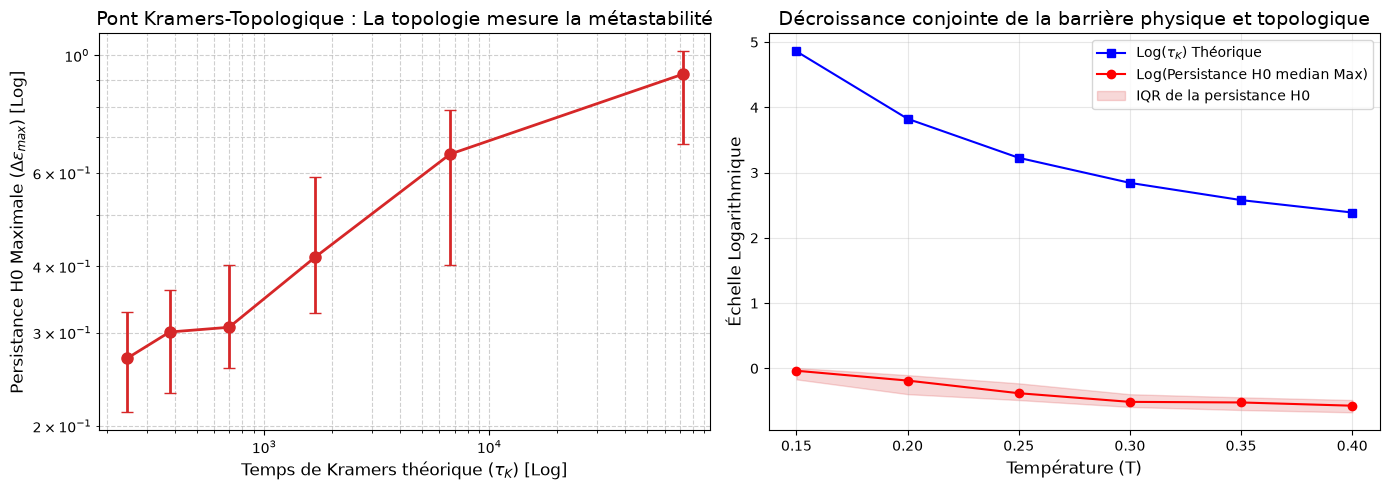

In [36]:
"""
N18_Pont_Kramers_Topologique.ipynb
Objectif : Valider l'hypothèse que la persistance H0 maximale (la "barrière topologique") 
est un proxy du temps d'échappement de Kramers (tau_K) dans un système métastable.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster
import sys

# ==============================================================================
# 0. IMPORTS DE TON PIPELINE EXISTANT
# ==============================================================================
# Assure-toi que noether_persistence.py est dans le même dossier
from noether_persistence import TopologicalCharges, PersDiagram

# ==============================================================================
# 1. LE MOTEUR PHYSIQUE (Ton script, légèrement adapté pour le bouclage)
# ==============================================================================
PUITS = [
    {"position": -2.0, "profondeur": 1.0, "largeur": 0.6},
    {"position": 0.0, "profondeur": 1.6, "largeur": 0.5}, # Puits central le plus profond
    {"position": 2.3, "profondeur": 0.8, "largeur": 0.7},
]
RAIDEUR_CONFINEMENT = 0.05
DT = 0.01
TEMPS_FINAL = 500.0  # Augmenté pour assurer des sauts rares à bas T

def potentiel(theta):
    v = 0.5 * RAIDEUR_CONFINEMENT * theta**2
    for p in PUITS:
        ecart = (theta - p["position"]) / p["largeur"]
        v -= p["profondeur"] * np.exp(-0.5 * ecart**2)
    return v

def force_potentiel(theta, pas=1e-4):
    return -(potentiel(theta + pas) - potentiel(theta - pas)) / (2 * pas)

def simuler_langevin(gamma, T, graine):
    rng = np.random.default_rng(graine)
    n_pas = int(TEMPS_FINAL / DT)
    theta = np.zeros(n_pas)
    vitesse = np.zeros(n_pas)
    theta[0], vitesse[0] = 0.0, 0.0 # On part du puits central
    
    sigma_bruit = np.sqrt(2 * gamma * T) # Fluctuation-dissipation
    
    for i in range(1, n_pas):
        dW = rng.normal(0, np.sqrt(DT))
        acceleration = force_potentiel(theta[i-1]) - gamma * vitesse[i-1]
        vitesse[i] = vitesse[i-1] + acceleration * DT + sigma_bruit * dW
        theta[i] = theta[i-1] + vitesse[i-1] * DT
        
    return theta

# ==============================================================================
# 2. LE MOTEUR GÉOMÉTRIQUE : Plongement de Takens
# ==============================================================================
def embed_takens(signal, m=3, delay=20):
    """Crée un nuage de points dans R^m à partir d'une série temporelle 1D."""
    n = len(signal)
    if n <= m * delay:
        raise ValueError("Signal trop court pour ce plongement")
    # On sous-échantillonne pour éviter les nuages trop denses (comme dans ton Atlas)
    indices = np.arange(0, n - m * delay, delay) 
    cloud = np.zeros((len(indices), m))
    for j in range(m):
        cloud[:, j] = signal[indices + j * delay]
    
    # Normalisation standard (cruciale pour que la distance epsilon ait un sens physique)
    cloud = (cloud - np.mean(cloud, axis=0)) / (np.std(cloud, axis=0) + 1e-8)
    return cloud

# ==============================================================================
# 3. LE MOTEUR TOPOLOGIQUE : Extraction de la "Barrière"
# ==============================================================================
def get_max_h0_persistence(cloud):
    """
    Calcule le diagramme de persistance H0 et retourne la durée de vie 
    de la barre la plus longue (hors la barre infinie de la composante finale).
    C'est notre "Barrière Topologique" (Delta_epsilon_topo).
    """
    # Utilisation de single-linkage via scipy (équivalent à ton MST)
    Z = linkage(pdist(cloud), method='single')
    # Z[:, 2] contient les hauteurs de fusion (les "deaths", les "births" sont 0)
    deaths = Z[:, 2]
    
    # La plus longue barre finie est la dernière fusion avant que tout ne soit connecté
    # (ou l'avant-dernière si on compte la fusion finale vers l'infini)
    max_persistence = np.max(deaths) if len(deaths) > 0 else 0.0
    return max_persistence

# ==============================================================================
# 4. LE PONT DE KRAMERS (Théorie)
# ==============================================================================
def taux_kramers_approx(gamma, T):
    """
    Approximation du taux de Kramers pour le puits central (le plus profond).
    On simplifie en prenant delta_V ~ 1.6 (profondeur) et omega0 ~ 1.0
    L'essentiel est la dépendance exponentielle en 1/T.
    """
    delta_V = 1.6 # Approximation de la barrière depuis le puits central
    omega0 = 1.0
    # Régime sous-amorti (gamma = 0.35 est faible devant omega0)
    taux = gamma * (delta_V / T) * (omega0 / (2 * np.pi)) * np.exp(-delta_V / T)
    return 1.0 / taux # Retourne le temps d'attente tau_K

# ==============================================================================
# 5. EXPÉRIENCE NUMÉRIQUE : Balayage en Température avec Moyennage (Le vrai test)
# ==============================================================================
if __name__ == "__main__":
    GAMMA = 0.35
    TEMPERATURES = np.array([0.15, 0.20, 0.25, 0.30, 0.35, 0.40])
    N_SEEDS = 35  # On moyenne sur 15 réalisations stochastiques pour lisser le "rip"
    
    results = {
        "T": [],
        "tau_K_theorique": [],
        "pers_max_median": [],
        "pers_max_q25": [],
        "pers_max_q75": [],        
        "pers_max_iqr": []  # Pour montrer la dispersion (l'épaisseur simondonienne !)
    }
    
    print(f"Démarrage du balayage Kramers-Topologique ({N_SEEDS} graines par T)...")
    for T in TEMPERATURES:
        print(f"  T = {T:.2f} ...", end=" ")
        tau_K = taux_kramers_approx(GAMMA, T)
        
        pers_max_values = []
        for seed in range(N_SEEDS):
            # 1. Physique
            theta = simuler_langevin(gamma=GAMMA, T=T, graine=seed)
            # 2. Géométrie
            cloud = embed_takens(theta, m=3, delay=20)
            # 3. Topologie
            pers_max_values.append(get_max_h0_persistence(cloud))
            
        # On prend la médiane pour être robuste aux "rips" stochastiques
        #med_pers = np.median(pers_max_values)
        q25_pers, med_pers, q75_pers = np.percentile(
            pers_max_values, [25, 50, 75]
        )
        iqr_pers = q75_pers - q25_pers

        results["T"].append(T)
        results["tau_K_theorique"].append(tau_K)
        results["pers_max_median"].append(med_pers)
        results["pers_max_q25"].append(q25_pers)
        results["pers_max_q75"].append(q75_pers)
        results["pers_max_iqr"].append(iqr_pers)
        print(
            f"tau_K = {tau_K:7.1f}, Pers_Max_med = {med_pers:.4f}, "
            f"IQR = [{q25_pers:.4f}, {q75_pers:.4f}]"
        )

    # Calcul de la corrélation log-log (Le chiffre du "Smoking Gun")
    log_tau = np.log10(results["tau_K_theorique"])
    log_pers = np.log10(results["pers_max_median"])
    correlation = np.corrcoef(log_tau, log_pers)[0, 1]
    print(f"\n🎯 CORRÉLATION LOG-LOG (Pearson) : {correlation:.4f}")
    if correlation > 0.9:
        print("✅ VERDICT : Corrélation forte. La topologie est un proxy valide de la métastabilité.")
        
    # ==============================================================================
    # 6. VISUALISATION DU PONT
    # ==============================================================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Graphique 1 : Corrélation directe (Échelle Log-Log pour révéler la loi de puissance/exponentielle)
    ax1 = axes[0]
    median = np.asarray(results["pers_max_median"])
    q25 = np.asarray(results["pers_max_q25"])
    q75 = np.asarray(results["pers_max_q75"])
    tau = np.asarray(results["tau_K_theorique"])

    ax1.errorbar(
        tau,
        median,
        yerr=np.vstack((median - q25, q75 - median)),
        fmt="o-",
        color="tab:red",
        linewidth=2,
        markersize=8,
        capsize=4,
        label="Médiane et intervalle interquartile",
    )
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel("Temps de Kramers théorique ($\\tau_K$) [Log]", fontsize=12)
    ax1.set_ylabel("Persistance H0 Maximale ($\\Delta\\epsilon_{max}$) [Log]", fontsize=12)
    ax1.set_title("Pont Kramers-Topologique : La topologie mesure la métastabilité", fontsize=14)
    ax1.grid(True, which="both", ls="--", alpha=0.6)

    # Graphique 2 : Évolution en fonction de T
    ax2 = axes[1]
    ax2.plot(results["T"], np.log10(results["tau_K_theorique"]), label='Log($\\tau_K$) Théorique', color='blue', marker='s')
    ax2.plot(results["T"], np.log10(results["pers_max_median"]), label='Log(Persistance H0 median Max)', color='red', marker='o')
    ax2.fill_between(
        results["T"],
        np.log10(results["pers_max_q25"]),
        np.log10(results["pers_max_q75"]),
        color="tab:red",
        alpha=0.18,
        label="IQR de la persistance H0",
    )
    ax2.set_xlabel("Température (T)", fontsize=12)
    ax2.set_ylabel("Échelle Logarithmique", fontsize=12)
    ax2.set_title("Décroissance conjointe de la barrière physique et topologique", fontsize=14)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("pont_kramers_topologique.png", dpi=300)
    print("\n✅ Analyse terminée. Graphique sauvegardé sous 'pont_kramers_topologique.png'")
    plt.show()

N19 pilote [bi] : eps=[0.0, 0.07, 0.0877, 0.1408, 0.3], graines=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9], fractions=[0.2, 0.32000000000000006, 0.44000000000000006, 0.56, 0.6800000000000002, 0.8], décalages=[60, 96, 132, 168, 204, 240], thresh=2.2
eps=0.0000 | d(réel,nul)=0.1558 IC95[0.1442,0.1723] | d(nul,nul)=0.1671 IC95[0.1552,0.1816] | Δ apparié=-0.0134 IC95[-0.0290,+0.0065] | Rproxy réel/nul=0.446/0.587 | ΔRproxy=-0.092 IC95[-0.252,+0.032] | R vrai=0.452
eps=0.0700 | d(réel,nul)=0.2042 IC95[0.1822,0.2579] | d(nul,nul)=0.1789 IC95[0.1663,0.1928] | Δ apparié=+0.0418 IC95[-0.0130,+0.0791] | Rproxy réel/nul=0.941/0.744 | ΔRproxy=+0.184 IC95[+0.092,+0.367] | R vrai=0.947
eps=0.0877 | d(réel,nul)=0.1955 IC95[0.1625,0.2402] | d(nul,nul)=0.1833 IC95[0.1591,0.2257] | Δ apparié=+0.0117 IC95[-0.0067,+0.0253] | Rproxy réel/nul=0.951/0.648 | ΔRproxy=+0.315 IC95[+0.093,+0.470] | R vrai=0.966
eps=0.1408 | d(réel,nul)=0.3173 IC95[0.2872,0.3551] | d(nul,nul)=0.2475 IC95[0.1728,0.2636] | Δ apparié=+0.0957 IC9

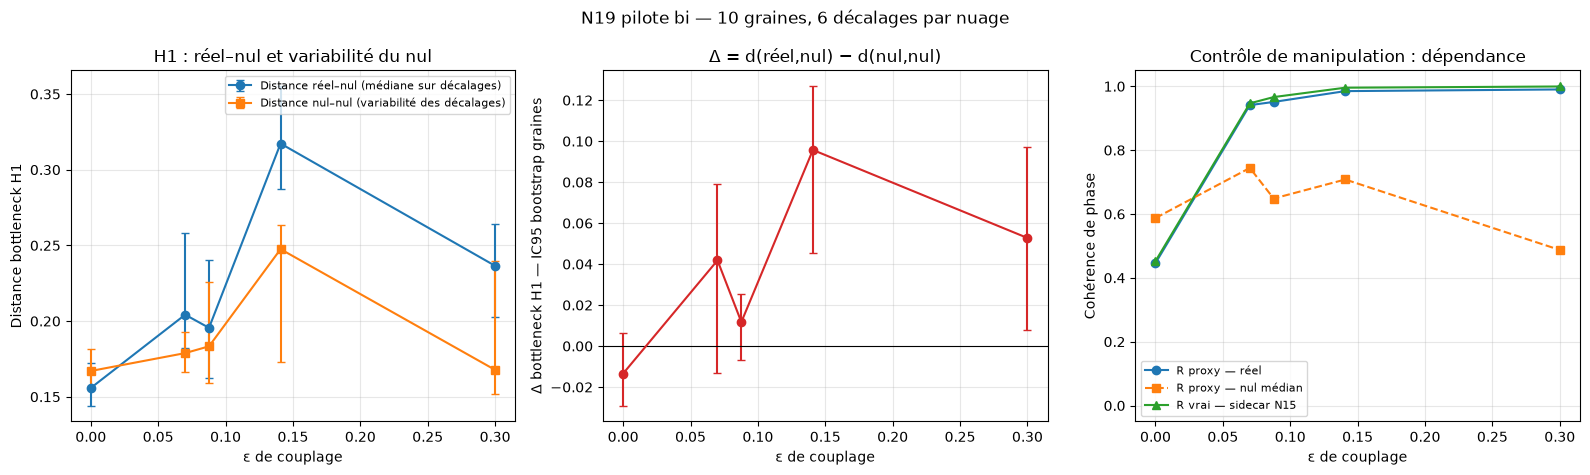

Lecture : un IC95 de Δ entièrement > 0 indique que la distance réel–nul dépasse la variabilité entre décalages nuls; entièrement < 0 indique l'inverse; s'il contient 0, le pilote ne tranche pas. Ce contraste est descriptif : il ne constitue pas à lui seul une vérité H1. Vérifier le contrôle de phase et, s'il existe, R vrai du sidecar N15.


In [38]:
# ---------------------------------------------------------------------------
# N19 PILOTE — H1 réel vs nuls circulaires, avec contrôle de phase et bootstrap
# Prérequis : cellules définissant get_cloud, grille et SEEDS déjà exécutées.
# ---------------------------------------------------------------------------
from pathlib import Path as _N19Path

import matplotlib.pyplot as _N19plt
import numpy as _N19np
from persim import bottleneck as _N19bottleneck
from ripser import ripser as _N19ripser
from scipy.signal import hilbert as _N19hilbert


# ---- 0. Paramètres du pilote
N19_FAMILLE = "J"
N19_VARIANTE = "bi"                     # refaire ensuite en "uni", comme analyse secondaire
N19_T = 0.10
N19_M = 3
N19_EPS_CIBLES = (0.0000, 0.0700, 0.0877, 0.1408, 0.3000)
N19_N_SEEDS = 10
N19_BOOT = 1000

# Réutilise les six fractions de N15d si la cellule correspondante a été exécutée.
# Sinon, reprend la grille de fractions de N15d.
N19_LAG_FRACS = _N19np.asarray(
    globals().get("J2_LAG_FRACS", _N19np.linspace(0.20, 0.80, 6)),
    dtype=float,
)

# Ripser calcule H1 jusqu'à cette échelle. Une classe non terminée déclenche une
# erreur explicite plutôt que d'être silencieusement exclue du calcul.
N19_THRESH = 2.2
N19_RNG = _N19np.random.default_rng(1919)

if not callable(globals().get("get_cloud")) or not callable(globals().get("grille")):
    raise RuntimeError(
        "N19 : exécuter d'abord les cellules qui définissent get_cloud et grille."
    )

if not N19_LAG_FRACS.size or _N19np.any(
    (N19_LAG_FRACS <= 0) | (N19_LAG_FRACS >= 1)
):
    raise ValueError(
        "N19 : chaque fraction de décalage doit être strictement comprise entre 0 et 1."
    )

# Vérifie que les epsilons demandés existent dans la grille au lieu de les approximer.
N19_EPS_GRILLE = _N19np.asarray(
    grille(N19_FAMILLE, "eps", var=N19_VARIANTE), dtype=float
)
N19_EPS = []

for _target in N19_EPS_CIBLES:
    _found = N19_EPS_GRILLE[
        _N19np.isclose(N19_EPS_GRILLE, _target, atol=1e-5, rtol=0)
    ]
    if not len(_found):
        raise ValueError(
            f"N19 : epsilon {_target:.4f} absent de la grille "
            f"{N19_FAMILLE}/{N19_VARIANTE} : {N19_EPS_GRILLE.tolist()}"
        )
    N19_EPS.append(float(_found[0]))

# Ne garder que des graines présentes à tous les epsilons du pilote.
N19_CANDIDATS_SEEDS = list(globals().get("SEEDS", range(35)))
N19_SEEDS = []

for _seed in N19_CANDIDATS_SEEDS:
    _present_partout = all(
        get_cloud(
            fam=N19_FAMILLE,
            seed=_seed,
            var=N19_VARIANTE,
            eps=_eps,
            T=N19_T,
            m=N19_M,
        ) is not None
        for _eps in N19_EPS
    )
    if _present_partout:
        N19_SEEDS.append(int(_seed))
    if len(N19_SEEDS) >= N19_N_SEEDS:
        break

if len(N19_SEEDS) < 6:
    raise RuntimeError(
        f"N19 : seulement {len(N19_SEEDS)} graines communes; "
        "il en faut au moins 6 pour ce pilote."
    )

# Déduit N du premier nuage plutôt que de supposer qu'il vaut toujours 300.
_N19_FIRST = get_cloud(
    fam=N19_FAMILLE,
    seed=N19_SEEDS[0],
    var=N19_VARIANTE,
    eps=N19_EPS[0],
    T=N19_T,
    m=N19_M,
)
if _N19_FIRST is None or _N19_FIRST.ndim != 2 or _N19_FIRST.shape[1] != 2 * N19_M:
    raise ValueError("N19 : le premier nuage est absent ou sa forme est inattendue.")

N19_N_POINTS = int(_N19_FIRST.shape[0])

# 0.0775 dans N15c/N15e est un landmark en epsilon, pas une fraction de décalage.
N19_SHIFTS = _N19np.unique(
    _N19np.clip(
        _N19np.rint(N19_LAG_FRACS * N19_N_POINTS).astype(int),
        1,
        N19_N_POINTS - 1,
    )
)
if len(N19_SHIFTS) < 3:
    raise ValueError(
        "N19 : moins de trois décalages distincts après conversion en nombre de lignes."
    )


# ---- Fonctions de calcul
def _n19_phase_lock(x1, x2):
    """Cohérence de phase proxy, selon le principe du contrôle N15d."""
    p1 = _N19np.unwrap(
        _N19np.angle(_N19hilbert(x1 - _N19np.mean(x1)))
    )
    p2 = _N19np.unwrap(
        _N19np.angle(_N19hilbert(x2 - _N19np.mean(x2)))
    )
    value = float(abs(_N19np.mean(_N19np.exp(1j * (p1 - p2)))))
    return value, p1, p2


def _n19_h1_diagram(cloud, label):
    diagram = _N19np.asarray(
        _N19ripser(
            cloud,
            maxdim=1,
            thresh=N19_THRESH,
        )["dgms"][1],
        dtype=float,
    )

    if not _N19np.isfinite(diagram).all():
        n_censored = int((~_N19np.isfinite(diagram)).any(axis=1).sum())
        raise RuntimeError(
            f"N19 : {n_censored} cycle(s) H1 de {label} non terminés "
            f"à thresh={N19_THRESH}. Augmenter N19_THRESH et relancer; "
            "ne pas supprimer ces classes."
        )
    return diagram


def _n19_bottleneck(dgm_a, dgm_b):
    """Distance bottleneck, avec traitement explicite des diagrammes vides."""
    if len(dgm_a) == 0 and len(dgm_b) == 0:
        return 0.0
    if len(dgm_a) == 0:
        return float(_N19np.max((dgm_b[:, 1] - dgm_b[:, 0]) / 2))
    if len(dgm_b) == 0:
        return float(_N19np.max((dgm_a[:, 1] - dgm_a[:, 0]) / 2))
    return float(_N19bottleneck(dgm_a, dgm_b))


def _n19_median_ci(values):
    """Médiane et IC95 bootstrap en rééchantillonnant les graines."""
    values = _N19np.asarray(values, dtype=float)
    if values.ndim != 1 or not len(values) or not _N19np.isfinite(values).all():
        raise ValueError("N19 : valeurs invalides pour le bootstrap par graines.")

    n = len(values)
    boot = _N19np.empty(N19_BOOT, dtype=float)
    for b in range(N19_BOOT):
        boot[b] = _N19np.median(values[N19_RNG.integers(0, n, n)])

    return (
        float(_N19np.median(values)),
        tuple(_N19np.percentile(boot, [2.5, 97.5])),
    )


# ---- 1. Calcul apparié : chaque réel et ses nuls viennent du même nuage
N19_RESULTATS = []

print(
    f"N19 pilote [{N19_VARIANTE}] : eps={N19_EPS}, "
    f"graines={N19_SEEDS}, fractions={N19_LAG_FRACS.tolist()}, "
    f"décalages={N19_SHIFTS.tolist()}, thresh={N19_THRESH}"
)

for _eps in N19_EPS:
    _d_real_null = []
    _d_null_null = []
    _r_real = []
    _r_null = []
    _r_true = []

    for _seed in N19_SEEDS:
        _X_loaded = get_cloud(
            fam=N19_FAMILLE,
            seed=_seed,
            var=N19_VARIANTE,
            eps=_eps,
            T=N19_T,
            m=N19_M,
        )
        if (
            _X_loaded is None
            or _X_loaded.ndim != 2
            or _X_loaded.shape[1] != 2 * N19_M
        ):
            raise RuntimeError(
                f"N19 : nuage absent ou forme inattendue à eps={_eps}, seed={_seed}."
            )
        if _X_loaded.shape[0] != N19_N_POINTS:
            raise ValueError(
                f"N19 : N={_X_loaded.shape[0]} à eps={_eps}, seed={_seed}; "
                f"attendu N={N19_N_POINTS}."
            )
        if not _N19np.isfinite(_X_loaded).all():
            raise ValueError(
                f"N19 : valeurs non finies à eps={_eps}, seed={_seed}."
            )

        # get_cloud peut renvoyer un tableau partagé en lecture seule.
        _X = _N19np.array(_X_loaded, copy=True)
        _dgm_real = _n19_h1_diagram(
            _X,
            f"réel eps={_eps} seed={_seed}",
        )

        _dgm_nulls = []
        _distances = []
        _r_null_seed = []

        _r_real_seed, _p1, _p2 = _n19_phase_lock(
            _X[:, 0],
            _X[:, N19_M],
        )

        for _shift in N19_SHIFTS:
            _X_null = _X.copy()
            _X_null[:, N19_M:] = _N19np.roll(
                _X_null[:, N19_M:],
                int(_shift),
                axis=0,
            )

            _dgm_null = _n19_h1_diagram(
                _X_null,
                f"nul eps={_eps} seed={_seed} shift={_shift}",
            )
            _dgm_nulls.append(_dgm_null)
            _distances.append(_n19_bottleneck(_dgm_real, _dgm_null))

            # Comme dans N15d, on décale la série de phase déjà calculée.
            _r_null_seed.append(
                float(
                    abs(
                        _N19np.mean(
                            _N19np.exp(
                                1j * (_p1 - _N19np.roll(_p2, int(_shift)))
                            )
                        )
                    )
                )
            )

        # Référence interne : dispersion entre les différents nuls du même nuage.
        _pair_null_distances = [
            _n19_bottleneck(_dgm_nulls[i], _dgm_nulls[j])
            for i in range(len(_dgm_nulls))
            for j in range(i + 1, len(_dgm_nulls))
        ]

        _d_real_null.append(float(_N19np.median(_distances)))
        _d_null_null.append(float(_N19np.median(_pair_null_distances)))
        _r_real.append(_r_real_seed)
        _r_null.append(float(_N19np.median(_r_null_seed)))

        # R_vrai lit le sidecar de référence de N15, s'il existe.
        _r_truth_fn = globals().get("R_vrai")
        _r_truth_value = (
            _r_truth_fn(N19_VARIANTE, _eps, _seed)
            if callable(_r_truth_fn)
            else None
        )
        _r_true.append(
            _N19np.nan if _r_truth_value is None else float(_r_truth_value)
        )

    _d_real_null = _N19np.asarray(_d_real_null)
    _d_null_null = _N19np.asarray(_d_null_null)
    _contrast = _d_real_null - _d_null_null
    _r_real = _N19np.asarray(_r_real)
    _r_null = _N19np.asarray(_r_null)
    _r_true = _N19np.asarray(_r_true)

    _dr_med, _dr_ci = _n19_median_ci(_d_real_null)
    _dn_med, _dn_ci = _n19_median_ci(_d_null_null)
    _dc_med, _dc_ci = _n19_median_ci(_contrast)
    _rr_med, _rr_ci = _n19_median_ci(_r_real)
    _rn_med, _rn_ci = _n19_median_ci(_r_null)
    _rg_med, _rg_ci = _n19_median_ci(_r_real - _r_null)

    _rt_med = (
        float(_N19np.nanmedian(_r_true))
        if _N19np.isfinite(_r_true).any()
        else float("nan")
    )

    _record = {
        "eps": _eps,
        "seeds": N19_SEEDS.copy(),
        "d_real_null": _d_real_null,
        "d_null_null": _d_null_null,
        "contrast": _contrast,
        "r_real": _r_real,
        "r_null": _r_null,
        "r_true": _r_true,
        "d_real_null_summary": (_dr_med, _dr_ci),
        "d_null_null_summary": (_dn_med, _dn_ci),
        "contrast_summary": (_dc_med, _dc_ci),
        "r_real_summary": (_rr_med, _rr_ci),
        "r_null_summary": (_rn_med, _rn_ci),
        "r_gap_summary": (_rg_med, _rg_ci),
        "r_true_median": _rt_med,
    }
    N19_RESULTATS.append(_record)

    print(
        f"eps={_eps:.4f} | "
        f"d(réel,nul)={_dr_med:.4f} IC95[{_dr_ci[0]:.4f},{_dr_ci[1]:.4f}] | "
        f"d(nul,nul)={_dn_med:.4f} IC95[{_dn_ci[0]:.4f},{_dn_ci[1]:.4f}] | "
        f"Δ apparié={_dc_med:+.4f} IC95[{_dc_ci[0]:+.4f},{_dc_ci[1]:+.4f}] | "
        f"Rproxy réel/nul={_rr_med:.3f}/{_rn_med:.3f} | "
        f"ΔRproxy={_rg_med:+.3f} IC95[{_rg_ci[0]:+.3f},{_rg_ci[1]:+.3f}] | "
        f"R vrai={_rt_med:.3f}"
    )


# ---- 2. Graphiques de diagnostic
_N19_eps_plot = _N19np.asarray([r["eps"] for r in N19_RESULTATS])

_N19_dr = _N19np.asarray(
    [r["d_real_null_summary"][0] for r in N19_RESULTATS]
)
_N19_dr_ci = _N19np.asarray(
    [r["d_real_null_summary"][1] for r in N19_RESULTATS]
)
_N19_dn = _N19np.asarray(
    [r["d_null_null_summary"][0] for r in N19_RESULTATS]
)
_N19_dn_ci = _N19np.asarray(
    [r["d_null_null_summary"][1] for r in N19_RESULTATS]
)
_N19_dc = _N19np.asarray(
    [r["contrast_summary"][0] for r in N19_RESULTATS]
)
_N19_dc_ci = _N19np.asarray(
    [r["contrast_summary"][1] for r in N19_RESULTATS]
)
_N19_rr = _N19np.asarray(
    [r["r_real_summary"][0] for r in N19_RESULTATS]
)
_N19_rn = _N19np.asarray(
    [r["r_null_summary"][0] for r in N19_RESULTATS]
)
_N19_rt = _N19np.asarray([r["r_true_median"] for r in N19_RESULTATS])

N19_FIG, N19_AX = _N19plt.subplots(1, 3, figsize=(16, 4.8))

N19_AX[0].errorbar(
    _N19_eps_plot,
    _N19_dr,
    yerr=_N19np.vstack(
        (_N19_dr - _N19_dr_ci[:, 0], _N19_dr_ci[:, 1] - _N19_dr)
    ),
    marker="o",
    capsize=3,
    label="Distance réel–nul (médiane sur décalages)",
)
N19_AX[0].errorbar(
    _N19_eps_plot,
    _N19_dn,
    yerr=_N19np.vstack(
        (_N19_dn - _N19_dn_ci[:, 0], _N19_dn_ci[:, 1] - _N19_dn)
    ),
    marker="s",
    capsize=3,
    label="Distance nul–nul (variabilité des décalages)",
)
N19_AX[0].set_title("H1 : réel–nul et variabilité du nul")
N19_AX[0].set_xlabel("ε de couplage")
N19_AX[0].set_ylabel("Distance bottleneck H1")
N19_AX[0].grid(alpha=0.3)
N19_AX[0].legend(fontsize=8)

N19_AX[1].errorbar(
    _N19_eps_plot,
    _N19_dc,
    yerr=_N19np.vstack(
        (_N19_dc - _N19_dc_ci[:, 0], _N19_dc_ci[:, 1] - _N19_dc)
    ),
    marker="o",
    capsize=3,
    color="tab:red",
)
N19_AX[1].axhline(0, color="black", linewidth=0.8)
N19_AX[1].set_title("Δ = d(réel,nul) − d(nul,nul)")
N19_AX[1].set_xlabel("ε de couplage")
N19_AX[1].set_ylabel("Δ bottleneck H1 — IC95 bootstrap graines")
N19_AX[1].grid(alpha=0.3)

N19_AX[2].plot(_N19_eps_plot, _N19_rr, "o-", label="R proxy — réel")
N19_AX[2].plot(_N19_eps_plot, _N19_rn, "s--", label="R proxy — nul médian")
if _N19np.isfinite(_N19_rt).any():
    N19_AX[2].plot(
        _N19_eps_plot,
        _N19_rt,
        "^-",
        label="R vrai — sidecar N15",
    )
N19_AX[2].set_ylim(-0.05, 1.05)
N19_AX[2].set_title("Contrôle de manipulation : dépendance")
N19_AX[2].set_xlabel("ε de couplage")
N19_AX[2].set_ylabel("Cohérence de phase")
N19_AX[2].grid(alpha=0.3)
N19_AX[2].legend(fontsize=8)

N19_FIG.suptitle(
    f"N19 pilote {N19_VARIANTE} — {len(N19_SEEDS)} graines, "
    f"{len(N19_SHIFTS)} décalages par nuage"
)
N19_FIG.tight_layout()

N19_FIG_PATH = (
    _N19Path(FIG_DIR) / f"N19_pilote_H1_{N19_VARIANTE}.png"
)
N19_FIG.savefig(N19_FIG_PATH, dpi=250, bbox_inches="tight")
print(f"Figure enregistrée : {N19_FIG_PATH}")

_N19plt.show()

print(
    "Lecture : un IC95 de Δ entièrement > 0 indique que la distance réel–nul "
    "dépasse la variabilité entre décalages nuls; entièrement < 0 indique "
    "l'inverse; s'il contient 0, le pilote ne tranche pas. Ce contraste est "
    "descriptif : il ne constitue pas à lui seul une vérité H1. "
    "Vérifier le contrôle de phase et, s'il existe, R vrai du sidecar N15."
)

In [1]:
# v0.1 (old)
# ---------------------------------------------------------------------------
# N19 — TEST H1 SUR UN NUAGE J/bi ET SON NUL PAR DÉCALAGE CIRCULAIRE
# Prérequis : la cellule d'initialisation du notebook, dont get_cloud, a été exécutée.
# ---------------------------------------------------------------------------
from pathlib import Path as _N19Path

import matplotlib.pyplot as _N19plt
import numpy as _N19np
from persim import bottleneck as _N19bottleneck
from ripser import ripser as _N19ripser

# Cas de test : cette combinaison existe dans la grille de nuages J.
N19_FAMILLE = "J"
N19_VARIANTE = "bi"
N19_EPS = 0.1408 #presents: 0.1408 0.1585
N19_T = 0.10
N19_SEED = 8
N19_M = 3

# Le canal 2 est décalé de la moitié des lignes, comme dans le PoC N19.
N19_SHIFT_FRAC = 0.0877 #0.50

# Seuil de calcul H1. Une classe encore vivante à ce seuil est censurée ;
# la cellule s'arrête plutôt que de l'ignorer silencieusement.
N19_MAX_EDGE_LENGTH = 2.5

# Ce seuil ne sert qu'à rendre le graphique plus lisible.
# La distance bottleneck est calculée sur tous les cycles finis.
N19_MIN_LIFETIME_PLOT = 0.05


# ---- 1. Chargement et vérification du nuage
N19_X_loaded = get_cloud(
    fam=N19_FAMILLE,
    seed=N19_SEED,
    var=N19_VARIANTE,
    eps=N19_EPS,
    T=N19_T,
    m=N19_M,
)

if N19_X_loaded is None:
    raise FileNotFoundError(
        "N19 : nuage absent pour "
        f"fam={N19_FAMILLE}, var={N19_VARIANTE}, eps={N19_EPS}, "
        f"T={N19_T}, m={N19_M}, seed={N19_SEED}. "
        "Vérifier la grille et l'index des nuages."
    )

if N19_X_loaded.ndim != 2 or N19_X_loaded.shape[1] != 2 * N19_M:
    raise ValueError(
        f"N19 : forme inattendue {N19_X_loaded.shape}; "
        f"attendu un tableau à {2 * N19_M} colonnes."
    )

if N19_X_loaded.shape[0] < 3 or not _N19np.isfinite(N19_X_loaded).all():
    raise ValueError("N19 : le nuage est trop petit ou contient des valeurs non finies.")

# get_cloud peut renvoyer un tableau partagé en lecture seule : on travaille sur une copie.
N19_X_real = N19_X_loaded.copy()
N19_X_null = N19_X_real.copy()

N19_shift = int(round(N19_X_real.shape[0] * N19_SHIFT_FRAC))
if not 0 < N19_shift < N19_X_real.shape[0]:
    raise ValueError(f"N19 : décalage circulaire invalide ({N19_shift} lignes).")

# Colonnes 0..m-1 : canal 1 ; colonnes m..2m-1 : canal 2.
N19_X_null[:, N19_M:] = _N19np.roll(
    N19_X_null[:, N19_M:],
    N19_shift,
    axis=0,
)

print(
    f"N19 : nuage {N19_FAMILLE}/{N19_VARIANTE}, "
    f"eps={N19_EPS:.4f}, T={N19_T:.2f}, seed={N19_SEED} — "
    f"forme {N19_X_real.shape}, décalage={N19_shift} lignes."
)


# ---- 2. Calcul des diagrammes H1
def _n19_diagramme_h1(cloud, label):
    diagram = _N19np.asarray(
        _N19ripser(
            cloud,
            maxdim=1,
            thresh=N19_MAX_EDGE_LENGTH,
        )["dgms"][1],
        dtype=float,
    )

    # Avec un seuil de filtration fini, une mort infinie signifie que le cycle
    # n'a pas disparu dans la plage calculée : ne pas l'écarter en silence.
    if not _N19np.isfinite(diagram).all():
        n_censored = int((~_N19np.isfinite(diagram)).any(axis=1).sum())
        raise RuntimeError(
            f"N19 : {n_censored} cycle(s) H1 de {label} encore censuré(s) "
            f"à thresh={N19_MAX_EDGE_LENGTH}. Augmenter N19_MAX_EDGE_LENGTH "
            "puis relancer la cellule."
        )

    return diagram


N19_DGM_REAL = _n19_diagramme_h1(N19_X_real, "réel")
N19_DGM_NULL = _n19_diagramme_h1(N19_X_null, "décalé")

print(f"Cycles H1 finis — réel : {len(N19_DGM_REAL)}")
print(f"Cycles H1 finis — décalé : {len(N19_DGM_NULL)}")


# ---- 3. Distance bottleneck
# persim calcule la distance bottleneck entre deux diagrammes.
# Cas limites explicites pour les diagrammes vides.
if len(N19_DGM_REAL) == 0 and len(N19_DGM_NULL) == 0:
    N19_SIGMA_H1 = 0.0
elif len(N19_DGM_REAL) == 0:
    N19_SIGMA_H1 = float(
        _N19np.max(N19_DGM_NULL[:, 1] - N19_DGM_NULL[:, 0]) / 2
    )
elif len(N19_DGM_NULL) == 0:
    N19_SIGMA_H1 = float(
        _N19np.max(N19_DGM_REAL[:, 1] - N19_DGM_REAL[:, 0]) / 2
    )
else:
    N19_SIGMA_H1 = float(_N19bottleneck(N19_DGM_REAL, N19_DGM_NULL))

print(f"\nCopeau rythmique — distance bottleneck H1 : {N19_SIGMA_H1:.6f}")


# ---- 4. Visualisation des cycles suffisamment persistants
def _n19_plot_cycles(ax, diagram, title):
    lifetimes = diagram[:, 1] - diagram[:, 0]
    shown = _N19np.flatnonzero(lifetimes >= N19_MIN_LIFETIME_PLOT)

    if len(shown) == 0:
        ax.text(
            0.5, 0.5,
            f"Aucun cycle avec durée ≥ {N19_MIN_LIFETIME_PLOT:g}",
            ha="center", va="center",
            transform=ax.transAxes,
        )
    else:
        shown = shown[_N19np.argsort(lifetimes[shown])]
        colors = _N19plt.cm.viridis(
            _N19np.linspace(0.15, 0.9, len(shown))
        )
        for y, (idx, color) in enumerate(zip(shown, colors)):
            birth, death = diagram[idx]
            ax.plot(
                [birth, death],
                [y, y],
                color=color,
                linewidth=3,
                solid_capstyle="round",
            )

    ax.set_title(f"{title} — {len(shown)} cycle(s) affiché(s)")
    ax.set_xlabel("Échelle de naissance / mort")
    ax.set_ylabel("Cycles H1 (triés par durée de vie)")
    ax.grid(True, alpha=0.3)


N19_FIG, N19_AXES = _N19plt.subplots(1, 2, figsize=(13, 5))
_n19_plot_cycles(N19_AXES[0], N19_DGM_REAL, "N19 — Réel synchronisé")
_n19_plot_cycles(N19_AXES[1], N19_DGM_NULL, "N19 — Canal 2 décalé")

N19_FIG.suptitle(
    f"N19 — Test H1, distance bottleneck = {N19_SIGMA_H1:.4f}",
    y=1.02,
)
N19_FIG.tight_layout()

N19_FIG_PATH = _N19Path(FIG_DIR) / "N19_copeau_rythmique.png"
N19_FIG.savefig(N19_FIG_PATH, dpi=300, bbox_inches="tight")
print(f"Figure enregistrée : {N19_FIG_PATH}")

_N19plt.show()

NameError: name 'get_cloud' is not defined